In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV , KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew, kurtosis, shapiro
import seaborn as sns
# Grafico de Radar

from matplotlib.patches import Circle, RegularPolygon
from matplotlib.path import Path
from matplotlib.projections.polar import PolarAxes
from matplotlib.projections import register_projection
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D

import joblib

# Metricas

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import cross_val_score


In [2]:
df = pd.read_csv('DATOS/Conjunto_Datatraining.csv')
print(df.head())

   id id_siva  AB2_1  AB2_2  AB2_3  AB2_4  AB2_5  AB2_6  AB2_7  AB2_8  ...  \
0   6    row6    2.0    5.0    8.0   10.0   12.0   15.0   18.0   20.0  ...   
1  10   row10    2.0    5.0    8.0   10.0   12.0   15.0   18.0   20.0  ...   
2  16   row16    2.0    5.0    8.0   10.0   12.0   15.0   18.0   20.0  ...   
3  19   row19    2.0    5.0    8.0   10.0   12.0   15.0   18.0   20.0  ...   
4  20   row20    2.0    5.0    8.0   10.0   12.0   15.0   18.0   20.0  ...   

      R_21     R_22     R_23     R_24     R_25     R_26     R_27     R_28  \
0   100.00   100.00   100.00   100.00   100.00   100.00   100.00   100.00   
1  4765.06  4765.06  4765.06  4765.06  4765.06  4765.06  4765.06  4765.06   
2   804.50   804.50   804.50   804.50   804.50   804.50   804.50   804.50   
3  4765.06  4765.06  4765.06  4765.06  4765.06  4765.06  4765.06  4765.06   
4   100.00   100.00   100.00   100.00   100.00   100.00   100.00   100.00   

       R_29      R_30  
0   120.000   120.000  
1  4765.060  5718.07

In [3]:
# Copia y columnas
df_ml = df.copy()
ab2_cols = [f"AB2_{i}" for i in range(1, 31)]
rhoa_cols = [f"Rhoa_{i}" for i in range(1, 31)]
indicator_cols = [f"is_observed_{i}" for i in range(1, 31)]
X_cols = ab2_cols + rhoa_cols + indicator_cols
y_cols = rhoa_cols

# Split
df_train, df_test = train_test_split(df_ml, test_size=0.2, random_state=42)
y_train = df_train[y_cols].copy()
y_test = df_test[y_cols].copy()

# Indicadores y enmascaramiento
for df_set in [df_train, df_test]:
    for col in indicator_cols:
        df_set[col] = 1.0

np.random.seed(42)
mask_prob = 0.2
for df_set in [df_train, df_test]:
    for i in range(1, 31):
        col = f"Rhoa_{i}"
        ind_col = f"is_observed_{i}"
        mask = np.random.rand(len(df_set)) < mask_prob
        df_set.loc[mask, col] = 0.0
        df_set.loc[mask, ind_col] = 0.0

X_train = df_train[X_cols]
X_test = df_test[X_cols]



# Random Forest

Version 2 final

In [4]:
# Definir parámetros para GridSearchCV
param_grid_rf = {
    "n_estimators": [50, 100, 200],#[100, 200],
    "max_depth": [10, 15, 20, 30, None],#[10, 15, 20, 30, None],
    "min_samples_split": [2, 5, 7, 10]#[2, 5]
}

# Modelo con GridSearchCV
rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_multi = MultiOutputRegressor(GridSearchCV(rf, param_grid_rf, cv=5, scoring="r2", n_jobs=-1, verbose=1))
rf_multi.fit(X_train, y_train)

# Guardar el modelo y columnas
joblib.dump(rf_multi, "random_forest_multioutput.joblib")
joblib.dump(X_cols, "random_forest_feature_columns.joblib")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 

['random_forest_feature_columns.joblib']

In [5]:
# Predicciones
y_pred = rf_multi.predict(X_test)

# Asegurar que y_test y y_pred sean compatibles
y_test_array = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test
y_pred_array = np.array(y_pred)

# Verificar dimensiones
print(f"Shape y_test: {y_test_array.shape}, Shape y_pred: {y_pred_array.shape}")

# Métricas globales (promedio sobre todas las columnas)
mse_global = mean_squared_error(y_test_array, y_pred_array)
rmse_global = np.sqrt(mse_global)
mae_global = mean_absolute_error(y_test_array, y_pred_array)
r2_global = r2_score(y_test_array, y_pred_array, multioutput='uniform_average')

# MAPE por columna y global
def calculate_mape(y_true, y_pred):
    mape_values = []
    for i in range(y_true.shape[1]):
        mask = y_true[:, i] != 0
        if mask.sum() > 0:
            mape_col = np.mean(np.abs((y_true[mask, i] - y_pred[mask, i]) / y_true[mask, i])) * 100
            mape_values.append(mape_col)
    return np.mean(mape_values) if mape_values else np.nan

mape_global = calculate_mape(y_test_array, y_pred_array)

# Métricas por columna (ejemplo para las primeras 5 columnas)
for i in range(min(30, y_test_array.shape[1])):
    mse_col = mean_squared_error(y_test_array[:, i], y_pred_array[:, i])
    r2_col = r2_score(y_test_array[:, i], y_pred_array[:, i])
    print(f"Columna {i+1} - MSE: {mse_col:.4f}, R²: {r2_col:.4f}")

# Acceder a los mejores parámetros (corrección)
try:
    # Acceder al GridSearchCV interno del primer estimador
    best_params = rf_multi.estimators_[0].best_params_
    print("Mejores parámetros del primer target:", best_params)
except AttributeError:
    print("No se encontraron mejores parámetros. Asegúrate de que el modelo fue entrenado con GridSearchCV.")
    print("Parámetros usados en el RandomForestRegressor:", rf_multi.estimators_[0].get_params())

# Imprimir resultados globales
print(f"Score RF (R² global): {r2_global:.4f}")
print(f"MSE global: {mse_global:.4f}")
print(f"RMSE global: {rmse_global:.4f}")
print(f"MAE global: {mae_global:.4f}")
print(f"MAPE global: {mape_global:.2f}%")

# Análisis de residuos
residuals = y_test_array - y_pred_array
residual_mean = np.mean(residuals)
residual_std = np.std(residuals)
print(f"Residuo medio global: {residual_mean:.4f}")
print(f"Desviación estándar de residuos global: {residual_std:.4f}")

for i in range(30):
    res_col = residuals[:, i]
    mean_res = np.mean(res_col)
    std_res = np.std(res_col)
    skew_res = skew(res_col)
    kurt_res = kurtosis(res_col)
    stat, p_value = shapiro(res_col[~np.isnan(res_col)])  # Prueba de normalidad
    print(f"Columna {i+1} - Residuo Media: {mean_res:.4f}, Std: {std_res:.4f}, Asimetría: {skew_res:.4f}, Curtosis: {kurt_res:.4f}, Shapiro-Wilk p-value: {p_value:.4f}")


Shape y_test: (347, 30), Shape y_pred: (347, 30)
Columna 1 - MSE: 449.3789, R²: 0.9922
Columna 2 - MSE: 451.7683, R²: 0.9921
Columna 3 - MSE: 255.7646, R²: 0.9955
Columna 4 - MSE: 184.1613, R²: 0.9967
Columna 5 - MSE: 723.6514, R²: 0.9875
Columna 6 - MSE: 968.7905, R²: 0.9849
Columna 7 - MSE: 1202.3735, R²: 0.9836
Columna 8 - MSE: 1159.9705, R²: 0.9862
Columna 9 - MSE: 1534.1931, R²: 0.9850
Columna 10 - MSE: 2157.5640, R²: 0.9822
Columna 11 - MSE: 2561.9288, R²: 0.9807
Columna 12 - MSE: 3499.5387, R²: 0.9770
Columna 13 - MSE: 3623.6083, R²: 0.9795
Columna 14 - MSE: 3496.7671, R²: 0.9815
Columna 15 - MSE: 4345.8189, R²: 0.9789
Columna 16 - MSE: 3855.2248, R²: 0.9832
Columna 17 - MSE: 3514.3269, R²: 0.9854
Columna 18 - MSE: 3589.4009, R²: 0.9863
Columna 19 - MSE: 3003.6186, R²: 0.9894
Columna 20 - MSE: 2743.7693, R²: 0.9907
Columna 21 - MSE: 3281.9315, R²: 0.9895
Columna 22 - MSE: 2634.1303, R²: 0.9921
Columna 23 - MSE: 1864.8633, R²: 0.9946
Columna 24 - MSE: 1572.4660, R²: 0.9957
Column

CV=5
Columna: 1, MSE: 449.3789, R²: 0.9922, Residuo Media: 2.0281, Std: 21.1013, Asimetría: 14.6709, Curtosis: 237.3178
Columna: 2, MSE: 451.7683, R²: 0.9921, Residuo Media: 2.1709, Std: 21.1437, Asimetría: 14.2406, Curtosis: 223.4228
Columna: 3, MSE: 255.7646, R²: 0.9955, Residuo Media: 2.3439, Std: 15.8200, Asimetría: 9.5241, Curtosis: 107.4582
Columna: 4, MSE: 184.1613, R²: 0.9967, Residuo Media: 2.7779, Std: 13.2833, Asimetría: 5.9781, Curtosis: 48.5586
Columna: 5, MSE: 723.6514, R²: 0.9875, Residuo Media: 4.7892, Std: 26.4710, Asimetría: 5.8868, Curtosis: 51.6807
Columna: 6, MSE: 968.7905, R²: 0.9849, Residuo Media: 6.1243, Std: 30.5169, Asimetría: 6.4381, Curtosis: 54.1212
Columna: 7, MSE: 1202.3735, R²: 0.9836, Residuo Media: 6.6501, Std: 34.0316, Asimetría: 7.7135, Curtosis: 68.2500
Columna: 8, MSE: 1159.9705, R²: 0.9862, Residuo Media: 6.0848, Std: 33.5104, Asimetría: 8.6403, Curtosis: 86.8977
Columna: 9, MSE: 1534.1931, R²: 0.9850, Residuo Media: 7.0963, Std: 38.5206, Asimetría: 9.1762, Curtosis: 95.9442
Columna: 10, MSE: 2157.5640, R²: 0.9822, Residuo Media: 9.6115, Std: 45.4443, Asimetría: 9.2997, Curtosis: 100.0925
Columna: 11, MSE: 2561.9288, R²: 0.9807, Residuo Media: 10.9458, Std: 49.4178, Asimetría: 9.3978, Curtosis: 101.4424
Columna: 12, MSE: 3499.5387, R²: 0.9770, Residuo Media: 13.3127, Std: 57.6395, Asimetría: 9.0650, Curtosis: 94.5313
Columna: 13, MSE: 3623.6083, R²: 0.9795, Residuo Media: 13.5188, Std: 58.6588, Asimetría: 9.4085, Curtosis: 106.7399
Columna: 14, MSE: 3496.7671, R²: 0.9815, Residuo Media: 13.1906, Std: 57.6435, Asimetría: 9.4054, Curtosis: 106.2402
Columna: 15, MSE: 4345.8189, R²: 0.9789, Residuo Media: 13.8201, Std: 64.4579, Asimetría: 10.5982, Curtosis: 134.0419
Columna: 16, MSE: 3855.2248, R²: 0.9832, Residuo Media: 13.2270, Std: 60.6652, Asimetría: 11.6313, Curtosis: 161.5394
Columna: 17, MSE: 3514.3269, R²: 0.9854, Residuo Media: 13.2683, Std: 57.7778, Asimetría: 10.9768, Curtosis: 145.9213
Columna: 18, MSE: 3589.4009, R²: 0.9863, Residuo Media: 12.7074, Std: 58.5485, Asimetría: 11.1859, Curtosis: 151.1576
Columna: 19, MSE: 3003.6186, R²: 0.9894, Residuo Media: 12.4223, Std: 53.3789, Asimetría: 10.3359, Curtosis: 129.3795
Columna: 20, MSE: 2743.7693, R²: 0.9907, Residuo Media: 12.4880, Std: 50.8706, Asimetría: 10.7330, Curtosis: 144.8018
Columna: 21, MSE: 3281.9315, R²: 0.9895, Residuo Media: 13.6569, Std: 55.6365, Asimetría: 10.8109, Curtosis: 144.1573
Columna: 22, MSE: 2634.1303, R²: 0.9921, Residuo Media: 13.7054, Std: 49.4600, Asimetría: 9.1230, Curtosis: 104.8610
Columna: 23, MSE: 1864.8633, R²: 0.9946, Residuo Media: 12.7347, Std: 41.2637, Asimetría: 7.7806, Curtosis: 79.6351
Columna: 24, MSE: 1572.4660, R²: 0.9957, Residuo Media: 12.0078, Std: 37.7926, Asimetría: 6.3038, Curtosis: 52.0747
Columna: 25, MSE: 1467.5920, R²: 0.9961, Residuo Media: 11.3971, Std: 36.5745, Asimetría: 6.5244, Curtosis: 53.1132
Columna: 26, MSE: 1157.2403, R²: 0.9970, Residuo Media: 9.8961, Std: 32.5470, Asimetría: 5.8833, Curtosis: 42.6215
Columna: 27, MSE: 852.9950, R²: 0.9979, Residuo Media: 8.3870, Std: 27.9759, Asimetría: 4.8718, Curtosis: 29.8495
Columna: 28, MSE: 640.3746, R²: 0.9985, Residuo Media: 6.8832, Std: 24.3515, Asimetría: 3.8627, Curtosis: 27.2376
Columna: 29, MSE: 700.1945, R²: 0.9984, Residuo Media: 6.0625, Std: 25.7573, Asimetría: 1.9985, Curtosis: 27.6856
Columna: 30, MSE: 822.6785, R²: 0.9983, Residuo Media: 4.5694, Std: 28.3161, Asimetría: 0.4818, Curtosis: 28.2685

CV=3
Columna: 1, MSE: 435.9630, R²: 0.9924, Residuo Media: 2.0371, Std: 20.7801, Asimetría: 14.7321, Curtosis: 241.3256
Columna: 2, MSE: 438.2913, R²: 0.9924, Residuo Media: 2.0299, Std: 20.8368, Asimetría: 14.1311, Curtosis: 219.5262
Columna: 3, MSE: 252.4255, R²: 0.9955, Residuo Media: 2.2846, Std: 15.7228, Asimetría: 9.6396, Curtosis: 112.5523
Columna: 4, MSE: 202.7687, R²: 0.9964, Residuo Media: 2.9725, Std: 13.9260, Asimetría: 6.3730, Curtosis: 52.2953
Columna: 5, MSE: 805.7387, R²: 0.9861, Residuo Media: 5.0624, Std: 27.9305, Asimetría: 6.8719, Curtosis: 67.6894
Columna: 6, MSE: 1077.3904, R²: 0.9832, Residuo Media: 5.9923, Std: 32.2720, Asimetría: 7.3965, Curtosis: 72.7115
Columna: 7, MSE: 1189.8454, R²: 0.9838, Residuo Media: 6.4805, Std: 33.8799, Asimetría: 7.7055, Curtosis: 67.4317
Columna: 8, MSE: 1133.3265, R²: 0.9865, Residuo Media: 6.1772, Std: 33.0933, Asimetría: 8.3161, Curtosis: 79.5056
Columna: 9, MSE: 1552.1969, R²: 0.9848, Residuo Media: 7.0822, Std: 38.7562, Asimetría: 8.9442, Curtosis: 91.3019
Columna: 10, MSE: 2157.5640, R²: 0.9822, Residuo Media: 9.6115, Std: 45.4443, Asimetría: 9.2997, Curtosis: 100.0925
Columna: 11, MSE: 2561.9288, R²: 0.9807, Residuo Media: 10.9458, Std: 49.4178, Asimetría: 9.3978, Curtosis: 101.4424
Columna: 12, MSE: 3459.0048, R²: 0.9773, Residuo Media: 13.1696, Std: 57.3199, Asimetría: 9.2813, Curtosis: 99.7873
Columna: 13, MSE: 3484.2570, R²: 0.9803, Residuo Media: 13.1345, Std: 57.5477, Asimetría: 9.6881, Curtosis: 112.5699
Columna: 14, MSE: 3877.2314, R²: 0.9795, Residuo Media: 13.4861, Std: 60.7894, Asimetría: 10.1707, Curtosis: 123.9071
Columna: 15, MSE: 4152.3678, R²: 0.9799, Residuo Media: 13.5528, Std: 62.9975, Asimetría: 10.5270, Curtosis: 131.1671
Columna: 16, MSE: 4326.3773, R²: 0.9811, Residuo Media: 13.8288, Std: 64.3051, Asimetría: 11.5515, Curtosis: 157.6384
Columna: 17, MSE: 3496.9086, R²: 0.9854, Residuo Media: 14.0088, Std: 57.4514, Asimetría: 10.1508, Curtosis: 125.2526
Columna: 18, MSE: 4043.1918, R²: 0.9846, Residuo Media: 13.4784, Std: 62.1412, Asimetría: 11.3408, Curtosis: 153.1866
Columna: 19, MSE: 4014.7423, R²: 0.9859, Residuo Media: 13.7742, Std: 61.8467, Asimetría: 11.3979, Curtosis: 156.3922
Columna: 20, MSE: 3016.8709, R²: 0.9898, Residuo Media: 12.6490, Std: 53.4497, Asimetría: 10.7758, Curtosis: 143.6697
Columna: 21, MSE: 3097.3880, R²: 0.9901, Residuo Media: 13.0933, Std: 54.0921, Asimetría: 11.1236, Curtosis: 153.7613
Columna: 22, MSE: 2523.4432, R²: 0.9924, Residuo Media: 13.4403, Std: 48.4025, Asimetría: 8.6076, Curtosis: 93.5380
Columna: 23, MSE: 1692.6869, R²: 0.9951, Residuo Media: 12.1614, Std: 39.3038, Asimetría: 6.8787, Curtosis: 62.1582
Columna: 24, MSE: 1539.1727, R²: 0.9957, Residuo Media: 12.0461, Std: 37.3372, Asimetría: 6.4639, Curtosis: 55.4628
Columna: 25, MSE: 1342.9030, R²: 0.9965, Residuo Media: 10.9925, Std: 34.9581, Asimetría: 6.5976, Curtosis: 56.9946
Columna: 26, MSE: 1159.1388, R²: 0.9970, Residuo Media: 10.1582, Std: 32.4954, Asimetría: 5.7257, Curtosis: 39.5736
Columna: 27, MSE: 796.0270, R²: 0.9981, Residuo Media: 7.9930, Std: 27.0581, Asimetría: 4.5582, Curtosis: 28.1795
Columna: 28, MSE: 684.0965, R²: 0.9984, Residuo Media: 6.8499, Std: 25.2423, Asimetría: 4.4108, Curtosis: 32.8755
Columna: 29, MSE: 700.1945, R²: 0.9984, Residuo Media: 6.0625, Std: 25.7573, Asimetría: 1.9985, Curtosis: 27.6856
Columna: 30, MSE: 881.7300, R²: 0.9981, Residuo Media: 4.9398, Std: 29.2802, Asimetría: 0.0329, Curtosis: 32.1249

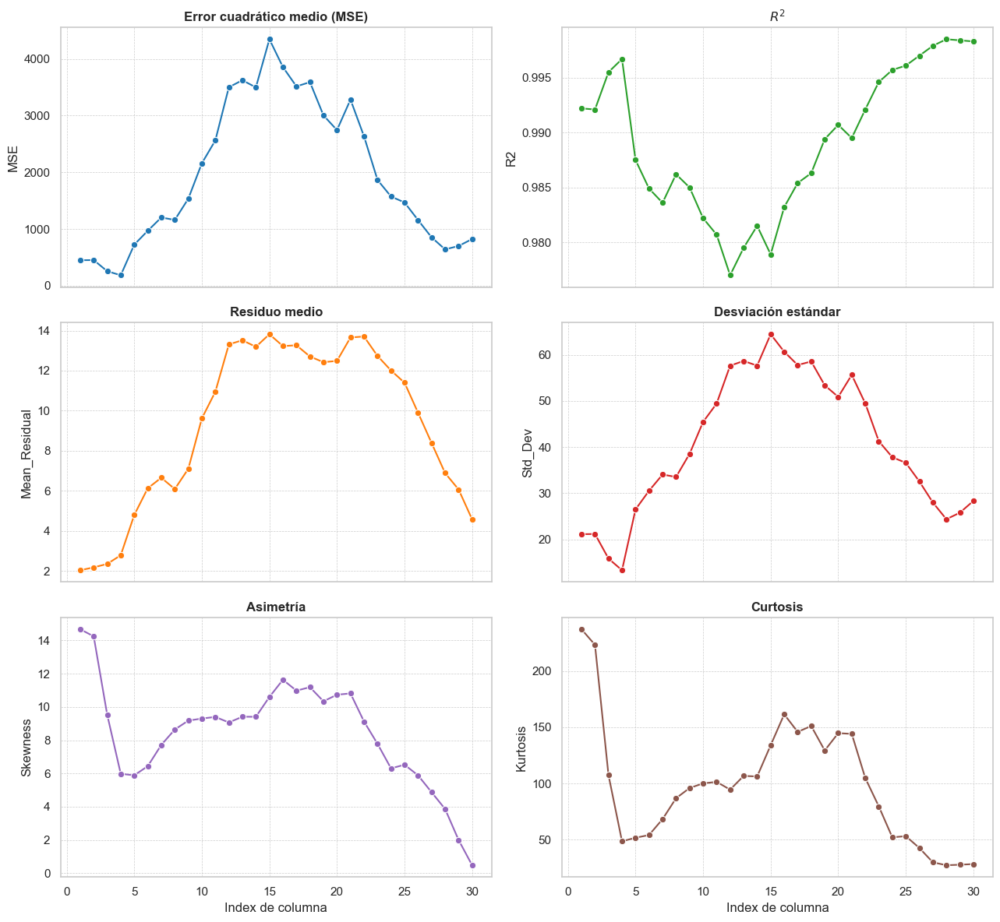

In [6]:
######## Random Forest
######## CV=5

# 1. DATOS DE ENTRADA
# Copiamos el bloque de texto tal cual lo proporcionaste para evitar errores de transcripción
raw_data = """
Columna: 1, MSE: 449.3789, R²: 0.9922, Residuo Media: 2.0281, Std: 21.1013, Asimetría: 14.6709, Curtosis: 237.3178
Columna: 2, MSE: 451.7683, R²: 0.9921, Residuo Media: 2.1709, Std: 21.1437, Asimetría: 14.2406, Curtosis: 223.4228
Columna: 3, MSE: 255.7646, R²: 0.9955, Residuo Media: 2.3439, Std: 15.8200, Asimetría: 9.5241, Curtosis: 107.4582
Columna: 4, MSE: 184.1613, R²: 0.9967, Residuo Media: 2.7779, Std: 13.2833, Asimetría: 5.9781, Curtosis: 48.5586
Columna: 5, MSE: 723.6514, R²: 0.9875, Residuo Media: 4.7892, Std: 26.4710, Asimetría: 5.8868, Curtosis: 51.6807
Columna: 6, MSE: 968.7905, R²: 0.9849, Residuo Media: 6.1243, Std: 30.5169, Asimetría: 6.4381, Curtosis: 54.1212
Columna: 7, MSE: 1202.3735, R²: 0.9836, Residuo Media: 6.6501, Std: 34.0316, Asimetría: 7.7135, Curtosis: 68.2500
Columna: 8, MSE: 1159.9705, R²: 0.9862, Residuo Media: 6.0848, Std: 33.5104, Asimetría: 8.6403, Curtosis: 86.8977
Columna: 9, MSE: 1534.1931, R²: 0.9850, Residuo Media: 7.0963, Std: 38.5206, Asimetría: 9.1762, Curtosis: 95.9442
Columna: 10, MSE: 2157.5640, R²: 0.9822, Residuo Media: 9.6115, Std: 45.4443, Asimetría: 9.2997, Curtosis: 100.0925
Columna: 11, MSE: 2561.9288, R²: 0.9807, Residuo Media: 10.9458, Std: 49.4178, Asimetría: 9.3978, Curtosis: 101.4424
Columna: 12, MSE: 3499.5387, R²: 0.9770, Residuo Media: 13.3127, Std: 57.6395, Asimetría: 9.0650, Curtosis: 94.5313
Columna: 13, MSE: 3623.6083, R²: 0.9795, Residuo Media: 13.5188, Std: 58.6588, Asimetría: 9.4085, Curtosis: 106.7399
Columna: 14, MSE: 3496.7671, R²: 0.9815, Residuo Media: 13.1906, Std: 57.6435, Asimetría: 9.4054, Curtosis: 106.2402
Columna: 15, MSE: 4345.8189, R²: 0.9789, Residuo Media: 13.8201, Std: 64.4579, Asimetría: 10.5982, Curtosis: 134.0419
Columna: 16, MSE: 3855.2248, R²: 0.9832, Residuo Media: 13.2270, Std: 60.6652, Asimetría: 11.6313, Curtosis: 161.5394
Columna: 17, MSE: 3514.3269, R²: 0.9854, Residuo Media: 13.2683, Std: 57.7778, Asimetría: 10.9768, Curtosis: 145.9213
Columna: 18, MSE: 3589.4009, R²: 0.9863, Residuo Media: 12.7074, Std: 58.5485, Asimetría: 11.1859, Curtosis: 151.1576
Columna: 19, MSE: 3003.6186, R²: 0.9894, Residuo Media: 12.4223, Std: 53.3789, Asimetría: 10.3359, Curtosis: 129.3795
Columna: 20, MSE: 2743.7693, R²: 0.9907, Residuo Media: 12.4880, Std: 50.8706, Asimetría: 10.7330, Curtosis: 144.8018
Columna: 21, MSE: 3281.9315, R²: 0.9895, Residuo Media: 13.6569, Std: 55.6365, Asimetría: 10.8109, Curtosis: 144.1573
Columna: 22, MSE: 2634.1303, R²: 0.9921, Residuo Media: 13.7054, Std: 49.4600, Asimetría: 9.1230, Curtosis: 104.8610
Columna: 23, MSE: 1864.8633, R²: 0.9946, Residuo Media: 12.7347, Std: 41.2637, Asimetría: 7.7806, Curtosis: 79.6351
Columna: 24, MSE: 1572.4660, R²: 0.9957, Residuo Media: 12.0078, Std: 37.7926, Asimetría: 6.3038, Curtosis: 52.0747
Columna: 25, MSE: 1467.5920, R²: 0.9961, Residuo Media: 11.3971, Std: 36.5745, Asimetría: 6.5244, Curtosis: 53.1132
Columna: 26, MSE: 1157.2403, R²: 0.9970, Residuo Media: 9.8961, Std: 32.5470, Asimetría: 5.8833, Curtosis: 42.6215
Columna: 27, MSE: 852.9950, R²: 0.9979, Residuo Media: 8.3870, Std: 27.9759, Asimetría: 4.8718, Curtosis: 29.8495
Columna: 28, MSE: 640.3746, R²: 0.9985, Residuo Media: 6.8832, Std: 24.3515, Asimetría: 3.8627, Curtosis: 27.2376
Columna: 29, MSE: 700.1945, R²: 0.9984, Residuo Media: 6.0625, Std: 25.7573, Asimetría: 1.9985, Curtosis: 27.6856
Columna: 30, MSE: 822.6785, R²: 0.9983, Residuo Media: 4.5694, Std: 28.3161, Asimetría: 0.4818, Curtosis: 28.2685
"""

# 2. PROCESAMIENTO (PARSING)
rows = []
lines = raw_data.strip().split('\n')
for line in lines:
    parts = line.split(',')
    row_data = {}
    for part in parts:
        key, val = part.split(':')
        row_data[key.strip()] = float(val.strip())
    rows.append(row_data)

df = pd.DataFrame(rows)

# Renombrar columnas para facilitar manejo y estandarización (Paper en inglés)
df = df.rename(columns={
    'Columna': 'Index de columna',
    'MSE': 'MSE',
    'R²': 'R2',
    'Residuo Media': 'Mean_Residual',
    'Std': 'Std_Dev',
    'Asimetría': 'Skewness',
    'Curtosis': 'Kurtosis'
})

# 3. GRAFICACIÓN
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True) #figsize=(15, 12)
axes = axes.flatten()

# Lista de métricas y sus títulos
metrics = ['MSE', 'R2', 'Mean_Residual', 'Std_Dev', 'Skewness', 'Kurtosis']
titles = [
    'Error cuadrático medio (MSE)', 
    '$R^2$', 
    'Residuo medio', 
    'Desviación estándar', 
    'Asimetría', 
    'Curtosis'
]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red', 'tab:purple', 'tab:brown']

# Bucle para generar los 6 subgráficos
for i, metric in enumerate(metrics):
    sns.lineplot(ax=axes[i], x='Index de columna', y=metric, data=df, marker='o', color=colors[i])
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_ylabel(metric)
    # Mejora visual: añadir rejilla menor para lectura precisa
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)

# Ajustes finales
plt.xlabel('Index de columna')
plt.tight_layout()
plt.savefig('metricas_validacion_RF_CV5.png', dpi=600)
plt.show() # O usar plt.savefig('metricas_validacion.png', dpi=300)

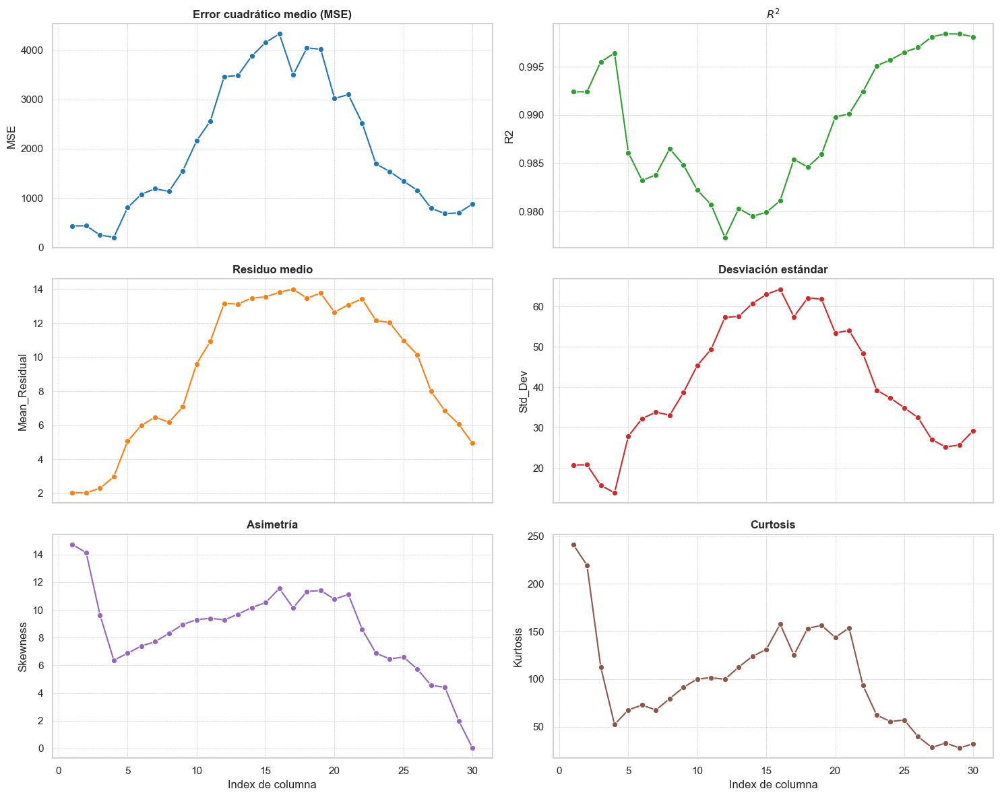

In [7]:
#################   CV=3

# 1. DATOS DE ENTRADA
# Copiamos el bloque de texto tal cual lo proporcionaste para evitar errores de transcripción
raw_data = """
Columna: 1, MSE: 435.9630, R²: 0.9924, Residuo Media: 2.0371, Std: 20.7801, Asimetría: 14.7321, Curtosis: 241.3256
Columna: 2, MSE: 438.2913, R²: 0.9924, Residuo Media: 2.0299, Std: 20.8368, Asimetría: 14.1311, Curtosis: 219.5262
Columna: 3, MSE: 252.4255, R²: 0.9955, Residuo Media: 2.2846, Std: 15.7228, Asimetría: 9.6396, Curtosis: 112.5523
Columna: 4, MSE: 202.7687, R²: 0.9964, Residuo Media: 2.9725, Std: 13.9260, Asimetría: 6.3730, Curtosis: 52.2953
Columna: 5, MSE: 805.7387, R²: 0.9861, Residuo Media: 5.0624, Std: 27.9305, Asimetría: 6.8719, Curtosis: 67.6894
Columna: 6, MSE: 1077.3904, R²: 0.9832, Residuo Media: 5.9923, Std: 32.2720, Asimetría: 7.3965, Curtosis: 72.7115
Columna: 7, MSE: 1189.8454, R²: 0.9838, Residuo Media: 6.4805, Std: 33.8799, Asimetría: 7.7055, Curtosis: 67.4317
Columna: 8, MSE: 1133.3265, R²: 0.9865, Residuo Media: 6.1772, Std: 33.0933, Asimetría: 8.3161, Curtosis: 79.5056
Columna: 9, MSE: 1552.1969, R²: 0.9848, Residuo Media: 7.0822, Std: 38.7562, Asimetría: 8.9442, Curtosis: 91.3019
Columna: 10, MSE: 2157.5640, R²: 0.9822, Residuo Media: 9.6115, Std: 45.4443, Asimetría: 9.2997, Curtosis: 100.0925
Columna: 11, MSE: 2561.9288, R²: 0.9807, Residuo Media: 10.9458, Std: 49.4178, Asimetría: 9.3978, Curtosis: 101.4424
Columna: 12, MSE: 3459.0048, R²: 0.9773, Residuo Media: 13.1696, Std: 57.3199, Asimetría: 9.2813, Curtosis: 99.7873
Columna: 13, MSE: 3484.2570, R²: 0.9803, Residuo Media: 13.1345, Std: 57.5477, Asimetría: 9.6881, Curtosis: 112.5699
Columna: 14, MSE: 3877.2314, R²: 0.9795, Residuo Media: 13.4861, Std: 60.7894, Asimetría: 10.1707, Curtosis: 123.9071
Columna: 15, MSE: 4152.3678, R²: 0.9799, Residuo Media: 13.5528, Std: 62.9975, Asimetría: 10.5270, Curtosis: 131.1671
Columna: 16, MSE: 4326.3773, R²: 0.9811, Residuo Media: 13.8288, Std: 64.3051, Asimetría: 11.5515, Curtosis: 157.6384
Columna: 17, MSE: 3496.9086, R²: 0.9854, Residuo Media: 14.0088, Std: 57.4514, Asimetría: 10.1508, Curtosis: 125.2526
Columna: 18, MSE: 4043.1918, R²: 0.9846, Residuo Media: 13.4784, Std: 62.1412, Asimetría: 11.3408, Curtosis: 153.1866
Columna: 19, MSE: 4014.7423, R²: 0.9859, Residuo Media: 13.7742, Std: 61.8467, Asimetría: 11.3979, Curtosis: 156.3922
Columna: 20, MSE: 3016.8709, R²: 0.9898, Residuo Media: 12.6490, Std: 53.4497, Asimetría: 10.7758, Curtosis: 143.6697
Columna: 21, MSE: 3097.3880, R²: 0.9901, Residuo Media: 13.0933, Std: 54.0921, Asimetría: 11.1236, Curtosis: 153.7613
Columna: 22, MSE: 2523.4432, R²: 0.9924, Residuo Media: 13.4403, Std: 48.4025, Asimetría: 8.6076, Curtosis: 93.5380
Columna: 23, MSE: 1692.6869, R²: 0.9951, Residuo Media: 12.1614, Std: 39.3038, Asimetría: 6.8787, Curtosis: 62.1582
Columna: 24, MSE: 1539.1727, R²: 0.9957, Residuo Media: 12.0461, Std: 37.3372, Asimetría: 6.4639, Curtosis: 55.4628
Columna: 25, MSE: 1342.9030, R²: 0.9965, Residuo Media: 10.9925, Std: 34.9581, Asimetría: 6.5976, Curtosis: 56.9946
Columna: 26, MSE: 1159.1388, R²: 0.9970, Residuo Media: 10.1582, Std: 32.4954, Asimetría: 5.7257, Curtosis: 39.5736
Columna: 27, MSE: 796.0270, R²: 0.9981, Residuo Media: 7.9930, Std: 27.0581, Asimetría: 4.5582, Curtosis: 28.1795
Columna: 28, MSE: 684.0965, R²: 0.9984, Residuo Media: 6.8499, Std: 25.2423, Asimetría: 4.4108, Curtosis: 32.8755
Columna: 29, MSE: 700.1945, R²: 0.9984, Residuo Media: 6.0625, Std: 25.7573, Asimetría: 1.9985, Curtosis: 27.6856
Columna: 30, MSE: 881.7300, R²: 0.9981, Residuo Media: 4.9398, Std: 29.2802, Asimetría: 0.0329, Curtosis: 32.1249
"""

# 2. PROCESAMIENTO (PARSING)
rows = []
lines = raw_data.strip().split('\n')
for line in lines:
    parts = line.split(',')
    row_data = {}
    for part in parts:
        key, val = part.split(':')
        row_data[key.strip()] = float(val.strip())
    rows.append(row_data)

df = pd.DataFrame(rows)

# Renombrar columnas para facilitar manejo y estandarización (Paper en inglés)
df = df.rename(columns={
    'Columna': 'Index de columna',
    'MSE': 'MSE',
    'R²': 'R2',
    'Residuo Media': 'Mean_Residual',
    'Std': 'Std_Dev',
    'Asimetría': 'Skewness',
    'Curtosis': 'Kurtosis'
})

# 3. GRAFICACIÓN
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

# Lista de métricas y sus títulos
metrics = ['MSE', 'R2', 'Mean_Residual', 'Std_Dev', 'Skewness', 'Kurtosis']
titles = [
    'Error cuadrático medio (MSE)', 
    '$R^2$', 
    'Residuo medio', 
    'Desviación estándar', 
    'Asimetría', 
    'Curtosis'
]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red', 'tab:purple', 'tab:brown']

# Bucle para generar los 6 subgráficos
for i, metric in enumerate(metrics):
    sns.lineplot(ax=axes[i], x='Index de columna', y=metric, data=df, marker='o', color=colors[i])
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_ylabel(metric)
    # Mejora visual: añadir rejilla menor para lectura precisa
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)

# Ajustes finales
plt.xlabel('Index de columna')
plt.tight_layout()
plt.savefig('metricas_validacion_cv3.png', dpi=600)
plt.show() # O usar plt.savefig('metricas_validacion.png', dpi=300)

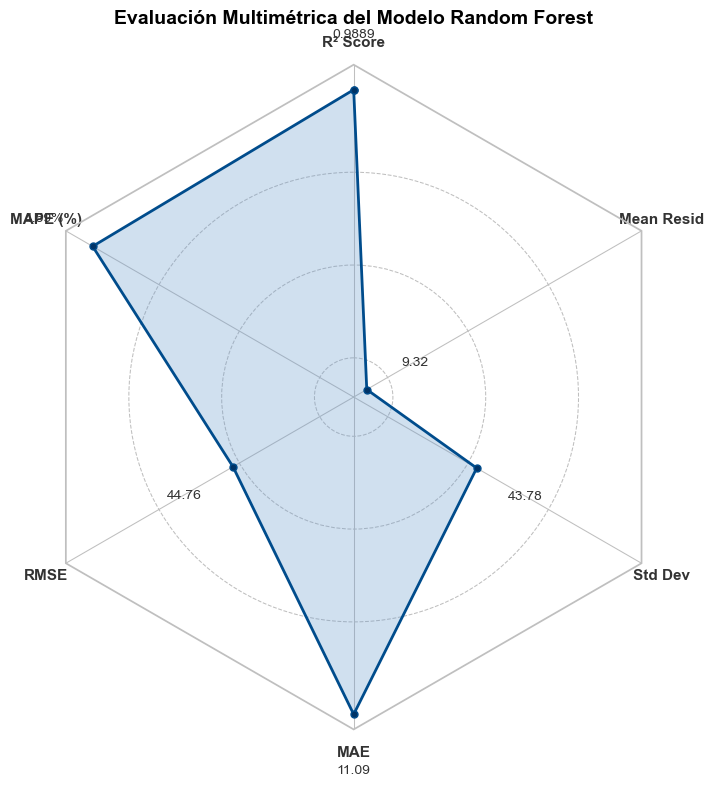

In [8]:
# --- 1. CONFIGURACIÓN DEL EJE RADAR (Igual que antes) ---
def radar_factory(num_vars, frame='circle'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)

    class RadarAxes(PolarAxes):
        name = 'radar'
        RESOLUTION = 1

        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')

        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)

        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines:
                self._close_line(line)

        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0])
                y = np.append(y, y[0])
                line.set_data(x, y)

        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)

        def _gen_axes_patch(self):
            if frame == 'circle':
                return Circle((0.5, 0.5), 0.5)
            elif frame == 'polygon':
                return RegularPolygon((0.5, 0.5), num_vars, radius=0.5, edgecolor="k")
            else:
                raise ValueError("unknown value for 'frame': %s" % frame)

        def _gen_axes_spines(self):
            if frame == 'circle':
                return super()._gen_axes_spines()
            elif frame == 'polygon':
                spine = Spine(axes=self,
                              spine_type='circle',
                              path=Path.unit_regular_polygon(num_vars))
                spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
                return {'polar': spine}
            else:
                raise ValueError("unknown value for 'frame': %s" % frame)

    register_projection(RadarAxes)
    return theta

# --- 2. DATOS Y NORMALIZACIÓN ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']
values = [0.9889, 4.59, 44.7568, 11.0893, 43.7764, 9.3165]

# Definición de "Peor caso" para normalizar (0 en el centro, 1 en el borde)
worst_case_limits = {
    'R² Score': 0.5,     
    'MAPE (%)': 131.24,    
    'RMSE': 116.5,       
    'MAE': 13592.6816,         
    'Std Dev': 115.7,    
    'Mean Resid': 14.29   
}

norm_values = []
# R2 (Mayor es mejor)
val_r2 = values[0]
lim_r2 = worst_case_limits['R² Score']
norm_r2 = (val_r2 - lim_r2) / (1.0 - lim_r2)
norm_values.append(max(0.05, norm_r2)) 

# Errores (Menor es mejor)
for i in range(1, len(values)):
    metric_name = metrics[i]
    val = values[i]
    limit = worst_case_limits[metric_name]
    norm = 1 - (val / limit)
    norm_values.append(max(0.05, norm)) 

# --- 3. ESTILO ACADÉMICO / TESIS ---
theta = radar_factory(6, frame='polygon')

# Colores Sobrios (Academic Style)
bg_color = 'white'          # Fondo blanco para impresión
grid_color = '#bfbfbf'      # Gris suave para la rejilla
text_color = '#333333'      # Gris muy oscuro (casi negro) para texto
line_color = '#004c8c'      # Azul marino profesional (Royal Blue oscuro)
fill_color = '#6699cc'      # Azul intermedio para el relleno
marker_color = '#003366'    # Puntos oscuros

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='radar'))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# Rejilla (Grid)
ax.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
ax.yaxis.grid(True, color=grid_color, linestyle='--', linewidth=0.75)
ax.xaxis.grid(True, color=grid_color, linestyle='-', linewidth=0.75)

# Dibujar Datos
ax.plot(theta, norm_values, color=line_color, linewidth=2, linestyle='-', marker='o', markersize=5, markerfacecolor=marker_color)
ax.fill(theta, norm_values, facecolor=fill_color, alpha=0.3) # Alpha bajo para que sea sutil

# Etiquetas de los ejes
ax.set_varlabels(metrics)
for label in ax.get_xticklabels():
    label.set_color(text_color)
    label.set_fontsize(11)
    label.set_fontweight('bold') # Negrita moderada para lectura

# Anotaciones de valores
for angle, val, norm_val, name in zip(theta, values, norm_values, metrics):
    if name == 'R² Score':
        txt = f"{val:.4f}"
    elif name == 'MAPE (%)':
        txt = f"{val:.2f}%"
    else:
        txt = f"{val:.2f}"
    
    # Texto en negro/gris oscuro cerca del punto
    ax.text(angle, norm_val + 0.12, txt, color=text_color, ha='center', va='center', fontsize=10)

# Limpieza de ejes
ax.spines['polar'].set_color(grid_color)
ax.set_yticklabels([])

# Título Formal
plt.title("Evaluación Multimétrica del Modelo Random Forest", color='black', size=14, weight='bold', pad=30)

plt.tight_layout()
# Guardar en alta resolución
plt.savefig('evaluacion_modelo_rf_tesis.png', dpi=300, bbox_inches='tight')
plt.show()

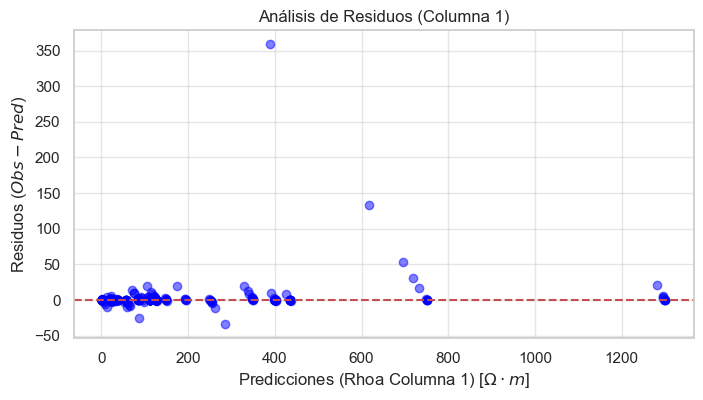

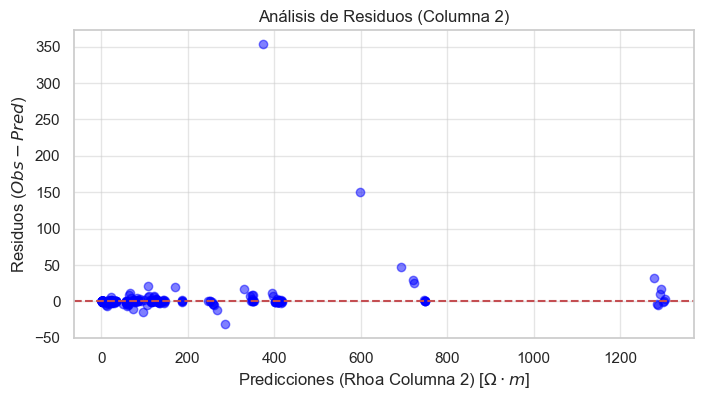

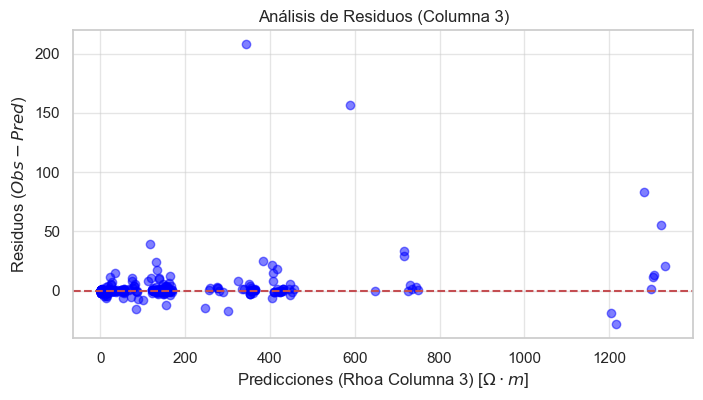

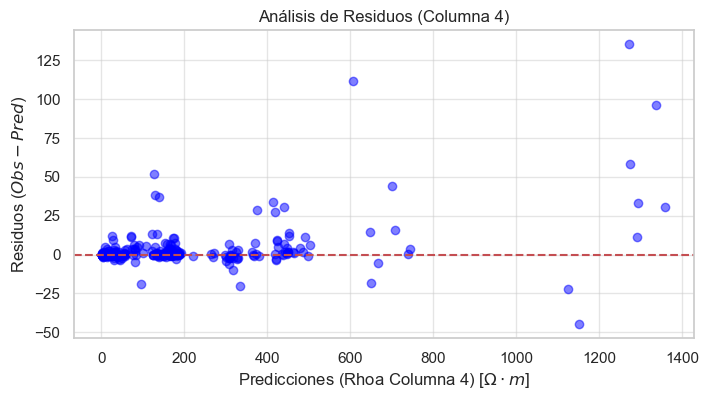

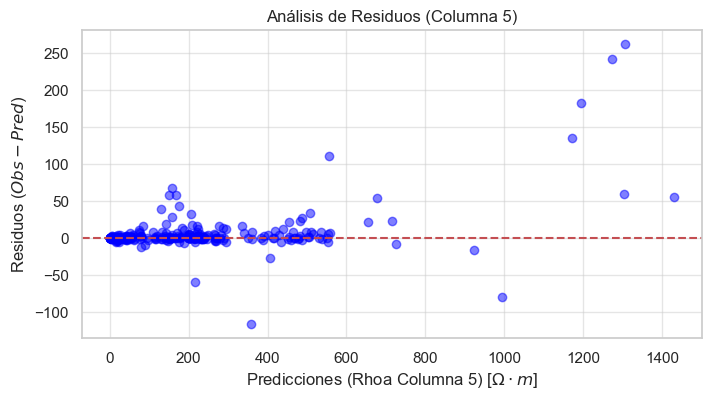

...

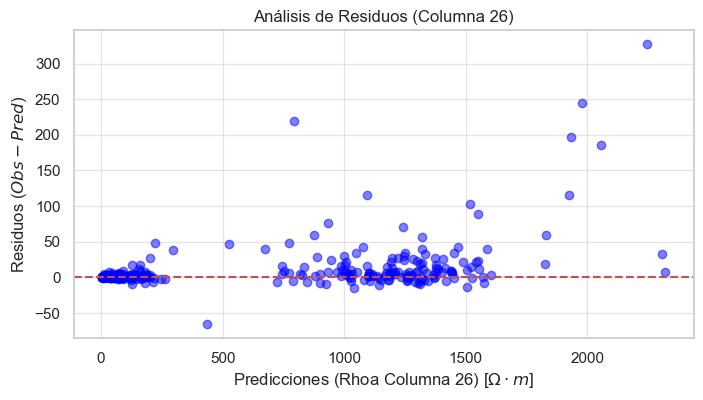

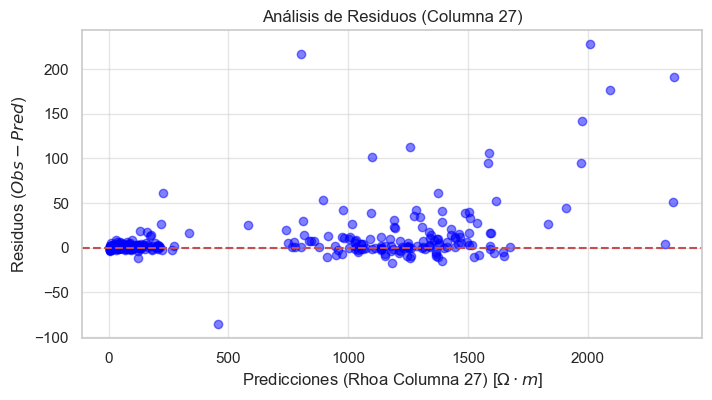

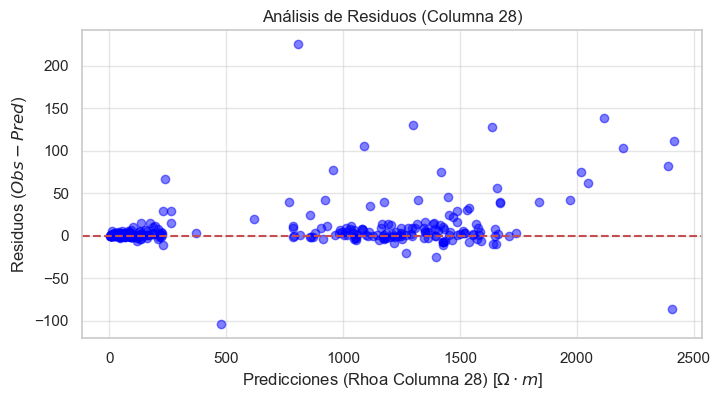

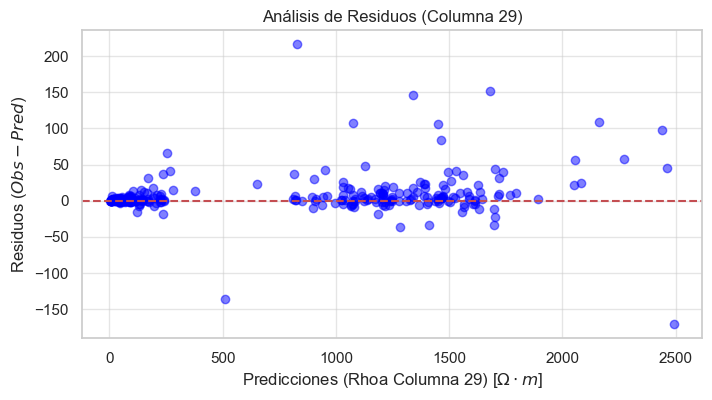

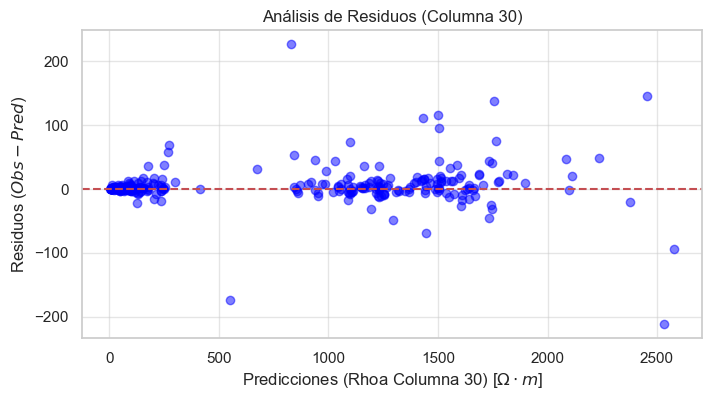

In [9]:
# Generar y guardar gráficos de residuos para las primeras 5 columnas
for i in range(30):
    plt.figure(figsize=(8, 4))
    plt.scatter(y_pred[:, i], residuals[:, i], c='blue', alpha=0.5)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel(f'Predicciones (Rhoa Columna {i+1}) [$\Omega\cdot m$]')
    plt.ylabel('Residuos ($Obs - Pred$)')
    plt.title(f'Análisis de Residuos (Columna {i+1})')
    plt.grid(True, alpha=0.5)  # Agregar rejilla para mayor claridad
    # Guardar la imagen con un nombre único
    plt.savefig(f'residual_plot_col_{i+1}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()  # Cerrar la figura para liberar memoria

## Métodos Más Rigurosos

Cross-Validation k-Fold: Implementa con cross_val_score de sklearn para obtener R² y MSE promedio:

Learning Curves: Evalúa sesgo y varianza graficando el rendimiento (R²) vs. tamaño del conjunto de entrenamiento para detectar under/overfitting.
Permutation Importance: Mide la importancia de features (e.g., AB2, Rhoa observados) para validar su contribución al modelo.

### Interpretación
Con los valores actuales (ejemplo: R² ~0.94, MSE ~bajo según datos previos), el modelo tiene alta precisión, pero MAPE y residuos ayudarán a identificar errores relativos y patrones. Si R² CV disminuye significativamente, indica posible overfitting. Usa estas métricas para ajustar hiperparámetros (e.g., max_depth, n_estimators) y optimizar el modelo, alineado con prácticas de Statistics Concepts y Groundwater Geophysics.

In [10]:
cv_scores = cross_val_score(rf_multi, X_train, y_train, cv=5, scoring='r2')
print(f"R² CV promedio: {cv_scores.mean():.4f} (±{cv_scores.std() * 2:.4f})")
#R² CV promedio: 0.9852 (±0.0067)

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Fitting 

# Support Vector Machine (SVM) V3 --- nueva propuesta

Se realizo una correcion en el metodo de entrenamiento de  SVM se realizo una estandarizacion de los datos empleando TransformedTargetRegressor , esto debido a que los datos dentro de las variociones sinteticas que se generaron,  presentando diferencias amuy marcadas en escala, la varianza y la amplitud de los datos, basicamente tenia un problema de escala, a diferencia de RF y GBR, es un problema en VSM ya que la escala de los datos y tu hiperparámetro $\epsilon$ (épsilon), ya que al tener valores extremandamente alto, en el caso de REsitividad puede ser de varios ordenes de magnitud con crecimientos logaritmicos, esto obliga a VSM a ajuastarse al punto del sobreajuste severo y fallando en la convergencia de un valor para el modelo

In [11]:
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
import joblib

# 1. Definimos el modelo base
svm_base = SVR(max_iter=50000)

# 2. Envolvemos el SVR para estandarizar la variable objetivo 'y' automáticamente
# Esto asegura que la SVR siempre vea una variable con media 0 y varianza 1,
# haciendo que tu param_grid_svm (especialmente epsilon) funcione para TODAS las columnas.
svm_scaled = TransformedTargetRegressor(
    regressor=svm_base,
    transformer=StandardScaler()
)

# 3. Ajustamos el diccionario de parámetros
# Al estar envuelto en TransformedTargetRegressor, debemos usar el prefijo 'regressor__'
param_grid_svm = {
    "regressor__C": [1, 10, 100, 150],
    "regressor__epsilon": [0.1, 0.2, 0.5, 0.9],
    "regressor__kernel": ['rbf', 'linear']
}

# 4. Construimos el pipeline de optimización
grid_search = GridSearchCV(
    estimator=svm_scaled, 
    param_grid=param_grid_svm, 
    cv=5, 
    scoring="r2", 
    n_jobs=-1, 
    verbose=1
)

# 5. MultiOutputRegressor aplicará este grid estandarizado a cada columna
svm_multi = MultiOutputRegressor(grid_search)
svm_multi.fit(X_train, y_train)

# Guardar
joblib.dump(svm_multi, "svm_multioutput.joblib")
# Asumo que X_cols está definido previamente en tu script
joblib.dump(X_cols, "svm_feature_columns.joblib") 

print("Modelo SVM entrenado. Las etiquetas 'y' han sido escaladas internamente.")

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 

In [12]:
# Predicciones
y_pred = svm_multi.predict(X_test)

# Asegurar que y_test y y_pred sean compatibles
y_test_array = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test
y_pred_array = np.array(y_pred)

# Verificar dimensiones
print(f"Shape y_test: {y_test_array.shape}, Shape y_pred: {y_pred_array.shape}")

# Métricas globales (promedio sobre todas las columnas)
mse_global = mean_squared_error(y_test_array, y_pred_array)
rmse_global = np.sqrt(mse_global)
mae_global = mean_absolute_error(y_test_array, y_pred_array)
r2_global = r2_score(y_test_array, y_pred_array, multioutput='uniform_average')

# MAPE por columna y global
def calculate_mape(y_true, y_pred):
    mape_values = []
    for i in range(y_true.shape[1]):
        mask = y_true[:, i] != 0
        if mask.sum() > 0:
            mape_col = np.mean(np.abs((y_true[mask, i] - y_pred[mask, i]) / y_true[mask, i])) * 100
            mape_values.append(mape_col)
    return np.mean(mape_values) if mape_values else np.nan

mape_global = calculate_mape(y_test_array, y_pred_array)

# Métricas por columna (ejemplo para las primeras 5 columnas)
for i in range(min(30, y_test_array.shape[1])):
    mse_col = mean_squared_error(y_test_array[:, i], y_pred_array[:, i])
    r2_col = r2_score(y_test_array[:, i], y_pred_array[:, i])
    print(f"Columna {i+1} - MSE: {mse_col:.4f}, R²: {r2_col:.4f}")

# Acceder a los mejores parámetros (corrección)
try:
    # Acceder al GridSearchCV interno del primer estimador
    best_params = svm_multi.estimators_[0].best_params_
    print("Mejores parámetros del primer target:", best_params)
except AttributeError:
    print("No se encontraron mejores parámetros. Asegúrate de que el modelo fue entrenado con GridSearchCV.")
    print("Parámetros usados en el SVR:", svm_multi.estimators_[0].get_params())

# Imprimir resultados globales
print(f"Score SVM (R² global): {r2_global:.4f}")
print(f"MSE global: {mse_global:.4f}")
print(f"RMSE global: {rmse_global:.4f}")
print(f"MAE global: {mae_global:.4f}")
print(f"MAPE global: {mape_global:.2f}%")

# Análisis estadístico de residuos (adaptado del libro: distribuciones y pruebas)
residuals = y_test_array - y_pred_array
residual_mean = np.mean(residuals)
residual_std = np.std(residuals)
print(f"Residuo medio global: {residual_mean:.4f}")
print(f"Desviación estándar de residuos global: {residual_std:.4f}")

for i in range(30):
    res_col = residuals[:, i]
    mean_res = np.mean(res_col)
    std_res = np.std(res_col)
    skew_res = skew(res_col)
    kurt_res = kurtosis(res_col)
    stat, p_value = shapiro(res_col[~np.isnan(res_col)])  # Prueba de normalidad
    print(f"Columna {i+1} - Residuo Media: {mean_res:.4f}, Std: {std_res:.4f}, Asimetría: {skew_res:.4f}, Curtosis: {kurt_res:.4f}, Shapiro-Wilk p-value: {p_value:.4f}")


Shape y_test: (347, 30), Shape y_pred: (347, 30)
Columna 1 - MSE: 5307.0933, R²: 0.9077
Columna 2 - MSE: 5242.2209, R²: 0.9085
Columna 3 - MSE: 5199.4623, R²: 0.9080
Columna 4 - MSE: 5391.9679, R²: 0.9033
Columna 5 - MSE: 5978.4564, R²: 0.8967
Columna 6 - MSE: 6122.4774, R²: 0.9048
Columna 7 - MSE: 6954.4116, R²: 0.9051
Columna 8 - MSE: 7727.7518, R²: 0.9081
Columna 9 - MSE: 8738.0422, R²: 0.9145
Columna 10 - MSE: 9469.1645, R²: 0.9217
Columna 11 - MSE: 9842.8913, R²: 0.9260
Columna 12 - MSE: 10376.3837, R²: 0.9318
Columna 13 - MSE: 10180.9100, R²: 0.9424
Columna 14 - MSE: 10103.8767, R²: 0.9466
Columna 15 - MSE: 9946.6564, R²: 0.9518
Columna 16 - MSE: 9335.4668, R²: 0.9592
Columna 17 - MSE: 9000.4442, R²: 0.9625
Columna 18 - MSE: 8808.8550, R²: 0.9665
Columna 19 - MSE: 7955.5056, R²: 0.9721
Columna 20 - MSE: 7777.3470, R²: 0.9736
Columna 21 - MSE: 7173.7332, R²: 0.9771
Columna 22 - MSE: 6689.4836, R²: 0.9799
Columna 23 - MSE: 6562.6343, R²: 0.9809
Columna 24 - MSE: 6332.8742, R²: 0.98

Columna: 1, MSE: 5307.0933, R²: 0.9077, Residuo Media: -7.4451, Std: 72.4684, Asimetría: 3.4230, Curtosis: 19.2696
Columna: 2, MSE: 5242.2209, R²: 0.9085, Residuo Media: -8.0324, Std: 71.9562, Asimetría: 3.5891, Curtosis: 20.4092
Columna: 3, MSE: 5199.4623, R²: 0.9080, Residuo Media: -8.2116, Std: 71.6382, Asimetría: 4.1391, Curtosis: 24.8075
Columna: 4, MSE: 5391.9679, R²: 0.9033, Residuo Media: -7.7087, Std: 73.0243, Asimetría: 4.5706, Curtosis: 28.6695
Columna: 5, MSE: 5978.4564, R²: 0.8967, Residuo Media: -5.1294, Std: 77.1502, Asimetría: 5.3294, Curtosis: 37.0095
Columna: 6, MSE: 6122.4774, R²: 0.9048, Residuo Media: -4.6708, Std: 78.1067, Asimetría: 5.6708, Curtosis: 41.5054
Columna: 7, MSE: 6954.4116, R²: 0.9051, Residuo Media: -4.0645, Std: 83.2940, Asimetría: 6.3361, Curtosis: 49.9751
Columna: 8, MSE: 7727.7518, R²: 0.9081, Residuo Media: -3.6316, Std: 87.8326, Asimetría: 6.7179, Curtosis: 55.3719
Columna: 9, MSE: 8738.0422, R²: 0.9145, Residuo Media: -3.5034, Std: 93.4118, Asimetría: 7.0568, Curtosis: 60.4191
Columna: 10, MSE: 9469.1645, R²: 0.9217, Residuo Media: -2.5790, Std: 97.2755, Asimetría: 7.2394, Curtosis: 63.4623
Columna: 11, MSE: 9842.8913, R²: 0.9260, Residuo Media: -2.8936, Std: 99.1691, Asimetría: 7.3500, Curtosis: 65.2801
Columna: 12, MSE: 10376.3837, R²: 0.9318, Residuo Media: -3.8577, Std: 101.7915, Asimetría: 7.6119, Curtosis: 69.1698
Columna: 13, MSE: 10180.9100, R²: 0.9424, Residuo Media: -3.6531, Std: 100.8343, Asimetría: 7.7787, Curtosis: 72.1587
Columna: 14, MSE: 10103.8767, R²: 0.9466, Residuo Media: -3.9518, Std: 100.4403, Asimetría: 7.7929, Curtosis: 72.6458
Columna: 15, MSE: 9946.6564, R²: 0.9518, Residuo Media: -4.2717, Std: 99.6414, Asimetría: 7.8098, Curtosis: 73.4537
Columna: 16, MSE: 9335.4668, R²: 0.9592, Residuo Media: -4.7492, Std: 96.5034, Asimetría: 7.8634, Curtosis: 74.9635
Columna: 17, MSE: 9000.4442, R²: 0.9625, Residuo Media: -4.9171, Std: 94.7432, Asimetría: 7.8859, Curtosis: 75.6121
Columna: 18, MSE: 8808.8550, R²: 0.9665, Residuo Media: -6.5660, Std: 93.6255, Asimetría: 7.8452, Curtosis: 74.9585
Columna: 19, MSE: 7955.5056, R²: 0.9721, Residuo Media: -7.7323, Std: 88.8578, Asimetría: 7.8909, Curtosis: 76.2316
Columna: 20, MSE: 7777.3470, R²: 0.9736, Residuo Media: -7.8491, Std: 87.8393, Asimetría: 7.7935, Curtosis: 74.8870
Columna: 21, MSE: 7173.7332, R²: 0.9771, Residuo Media: -9.3170, Std: 84.1839, Asimetría: 7.5815, Curtosis: 72.0410
Columna: 22, MSE: 6689.4836, R²: 0.9799, Residuo Media: -8.6443, Std: 81.3312, Asimetría: 7.1896, Curtosis: 66.5527
Columna: 23, MSE: 6562.6343, R²: 0.9809, Residuo Media: -8.7411, Std: 80.5371, Asimetría: 6.6608, Curtosis: 58.6776
Columna: 24, MSE: 6332.8742, R²: 0.9825, Residuo Media: -7.9926, Std: 79.1770, Asimetría: 6.1432, Curtosis: 51.3736
Columna: 25, MSE: 6232.3459, R²: 0.9836, Residuo Media: -7.7266, Std: 78.5662, Asimetría: 5.5928, Curtosis: 43.9405
Columna: 26, MSE: 6256.3824, R²: 0.9840, Residuo Media: -10.2335, Std: 78.4325, Asimetría: 5.1842, Curtosis: 38.2201
Columna: 27, MSE: 6102.3006, R²: 0.9851, Residuo Media: -9.8320, Std: 77.4960, Asimetría: 4.4610, Curtosis: 30.3903
Columna: 28, MSE: 6328.1951, R²: 0.9853, Residuo Media: -9.0697, Std: 79.0312, Asimetría: 3.8583, Curtosis: 24.2990
Columna: 29, MSE: 6675.4500, R²: 0.9852, Residuo Media: -9.5106, Std: 81.1480, Asimetría: 3.4119, Curtosis: 20.2099
Columna: 30, MSE: 7117.6727, R²: 0.9849, Residuo Media: -10.4053, Std: 83.7222, Asimetría: 3.0638, Curtosis: 17.2687

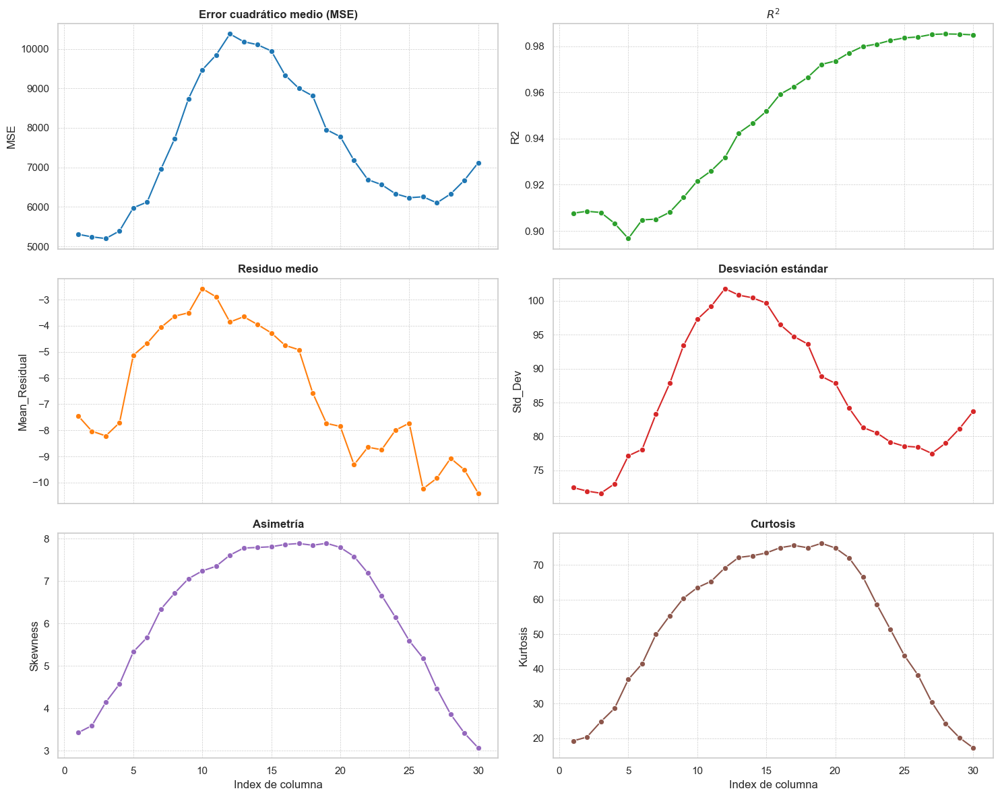

In [13]:
##########  Support Vector Machine (SVM)
# #######   CV=5

# 1. DATOS DE ENTRADA
# Copiamos el bloque de texto tal cual lo proporcionaste para evitar errores de transcripción
raw_data = """
Columna: 1, MSE: 5307.0933, R²: 0.9077, Residuo Media: -7.4451, Std: 72.4684, Asimetría: 3.4230, Curtosis: 19.2696
Columna: 2, MSE: 5242.2209, R²: 0.9085, Residuo Media: -8.0324, Std: 71.9562, Asimetría: 3.5891, Curtosis: 20.4092
Columna: 3, MSE: 5199.4623, R²: 0.9080, Residuo Media: -8.2116, Std: 71.6382, Asimetría: 4.1391, Curtosis: 24.8075
Columna: 4, MSE: 5391.9679, R²: 0.9033, Residuo Media: -7.7087, Std: 73.0243, Asimetría: 4.5706, Curtosis: 28.6695
Columna: 5, MSE: 5978.4564, R²: 0.8967, Residuo Media: -5.1294, Std: 77.1502, Asimetría: 5.3294, Curtosis: 37.0095
Columna: 6, MSE: 6122.4774, R²: 0.9048, Residuo Media: -4.6708, Std: 78.1067, Asimetría: 5.6708, Curtosis: 41.5054
Columna: 7, MSE: 6954.4116, R²: 0.9051, Residuo Media: -4.0645, Std: 83.2940, Asimetría: 6.3361, Curtosis: 49.9751
Columna: 8, MSE: 7727.7518, R²: 0.9081, Residuo Media: -3.6316, Std: 87.8326, Asimetría: 6.7179, Curtosis: 55.3719
Columna: 9, MSE: 8738.0422, R²: 0.9145, Residuo Media: -3.5034, Std: 93.4118, Asimetría: 7.0568, Curtosis: 60.4191
Columna: 10, MSE: 9469.1645, R²: 0.9217, Residuo Media: -2.5790, Std: 97.2755, Asimetría: 7.2394, Curtosis: 63.4623
Columna: 11, MSE: 9842.8913, R²: 0.9260, Residuo Media: -2.8936, Std: 99.1691, Asimetría: 7.3500, Curtosis: 65.2801
Columna: 12, MSE: 10376.3837, R²: 0.9318, Residuo Media: -3.8577, Std: 101.7915, Asimetría: 7.6119, Curtosis: 69.1698
Columna: 13, MSE: 10180.9100, R²: 0.9424, Residuo Media: -3.6531, Std: 100.8343, Asimetría: 7.7787, Curtosis: 72.1587
Columna: 14, MSE: 10103.8767, R²: 0.9466, Residuo Media: -3.9518, Std: 100.4403, Asimetría: 7.7929, Curtosis: 72.6458
Columna: 15, MSE: 9946.6564, R²: 0.9518, Residuo Media: -4.2717, Std: 99.6414, Asimetría: 7.8098, Curtosis: 73.4537
Columna: 16, MSE: 9335.4668, R²: 0.9592, Residuo Media: -4.7492, Std: 96.5034, Asimetría: 7.8634, Curtosis: 74.9635
Columna: 17, MSE: 9000.4442, R²: 0.9625, Residuo Media: -4.9171, Std: 94.7432, Asimetría: 7.8859, Curtosis: 75.6121
Columna: 18, MSE: 8808.8550, R²: 0.9665, Residuo Media: -6.5660, Std: 93.6255, Asimetría: 7.8452, Curtosis: 74.9585
Columna: 19, MSE: 7955.5056, R²: 0.9721, Residuo Media: -7.7323, Std: 88.8578, Asimetría: 7.8909, Curtosis: 76.2316
Columna: 20, MSE: 7777.3470, R²: 0.9736, Residuo Media: -7.8491, Std: 87.8393, Asimetría: 7.7935, Curtosis: 74.8870
Columna: 21, MSE: 7173.7332, R²: 0.9771, Residuo Media: -9.3170, Std: 84.1839, Asimetría: 7.5815, Curtosis: 72.0410
Columna: 22, MSE: 6689.4836, R²: 0.9799, Residuo Media: -8.6443, Std: 81.3312, Asimetría: 7.1896, Curtosis: 66.5527
Columna: 23, MSE: 6562.6343, R²: 0.9809, Residuo Media: -8.7411, Std: 80.5371, Asimetría: 6.6608, Curtosis: 58.6776
Columna: 24, MSE: 6332.8742, R²: 0.9825, Residuo Media: -7.9926, Std: 79.1770, Asimetría: 6.1432, Curtosis: 51.3736
Columna: 25, MSE: 6232.3459, R²: 0.9836, Residuo Media: -7.7266, Std: 78.5662, Asimetría: 5.5928, Curtosis: 43.9405
Columna: 26, MSE: 6256.3824, R²: 0.9840, Residuo Media: -10.2335, Std: 78.4325, Asimetría: 5.1842, Curtosis: 38.2201
Columna: 27, MSE: 6102.3006, R²: 0.9851, Residuo Media: -9.8320, Std: 77.4960, Asimetría: 4.4610, Curtosis: 30.3903
Columna: 28, MSE: 6328.1951, R²: 0.9853, Residuo Media: -9.0697, Std: 79.0312, Asimetría: 3.8583, Curtosis: 24.2990
Columna: 29, MSE: 6675.4500, R²: 0.9852, Residuo Media: -9.5106, Std: 81.1480, Asimetría: 3.4119, Curtosis: 20.2099
Columna: 30, MSE: 7117.6727, R²: 0.9849, Residuo Media: -10.4053, Std: 83.7222, Asimetría: 3.0638, Curtosis: 17.2687
"""

# 2. PROCESAMIENTO (PARSING)
rows = []
lines = raw_data.strip().split('\n')
for line in lines:
    parts = line.split(',')
    row_data = {}
    for part in parts:
        key, val = part.split(':')
        row_data[key.strip()] = float(val.strip())
    rows.append(row_data)

df = pd.DataFrame(rows)

# Renombrar columnas para facilitar manejo y estandarización (Paper en inglés)
df = df.rename(columns={
    'Columna': 'Index de columna',
    'MSE': 'MSE',
    'R²': 'R2',
    'Residuo Media': 'Mean_Residual',
    'Std': 'Std_Dev',
    'Asimetría': 'Skewness',
    'Curtosis': 'Kurtosis'
})

# 3. GRAFICACIÓN
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

# Lista de métricas y sus títulos
metrics = ['MSE', 'R2', 'Mean_Residual', 'Std_Dev', 'Skewness', 'Kurtosis']
titles = [
    'Error cuadrático medio (MSE)', 
    '$R^2$', 
    'Residuo medio', 
    'Desviación estándar', 
    'Asimetría', 
    'Curtosis'
]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red', 'tab:purple', 'tab:brown']

# Bucle para generar los 6 subgráficos
for i, metric in enumerate(metrics):
    sns.lineplot(ax=axes[i], x='Index de columna', y=metric, data=df, marker='o', color=colors[i])
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_ylabel(metric)
    # Mejora visual: añadir rejilla menor para lectura precisa
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)

# Ajustes finales
plt.xlabel('Index de columna')
plt.tight_layout()
plt.savefig('metricas_validacion_SVM_CV5.png', dpi=600)
plt.show() # O usar plt.savefig('metricas_validacion.png', dpi=300)

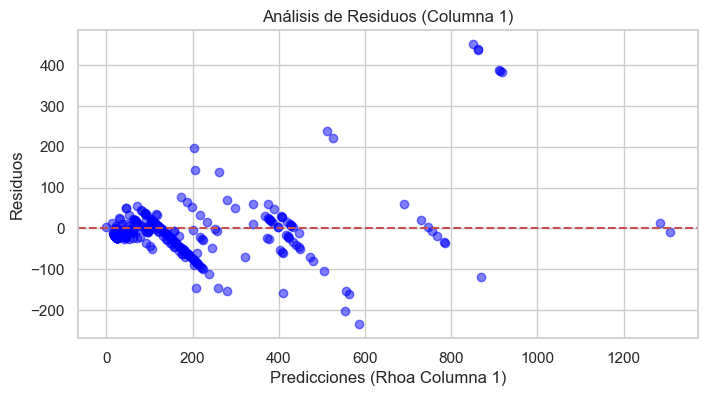

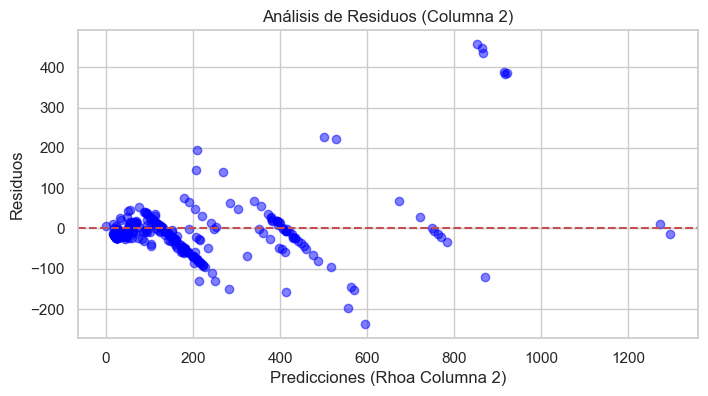

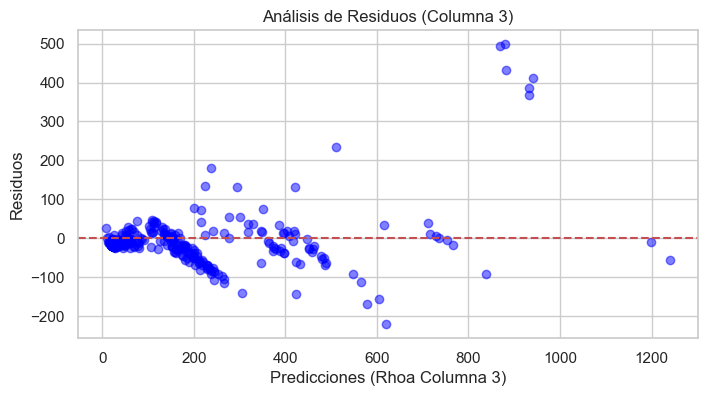

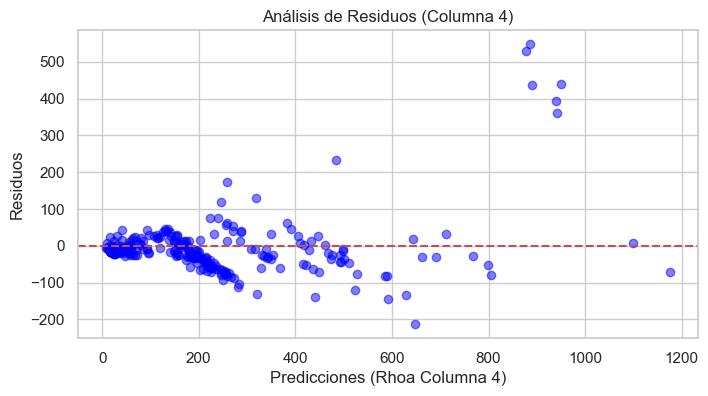

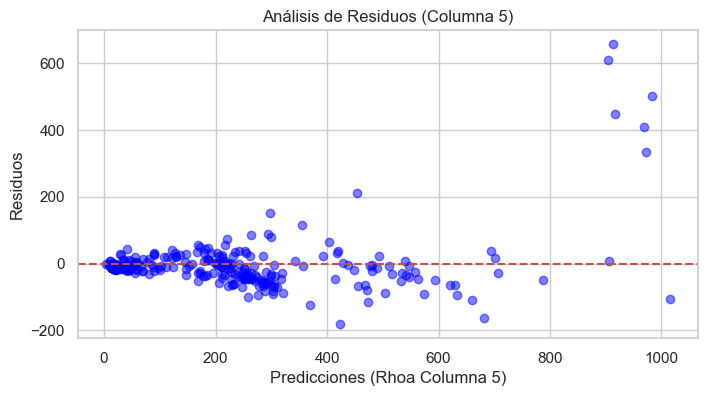

...

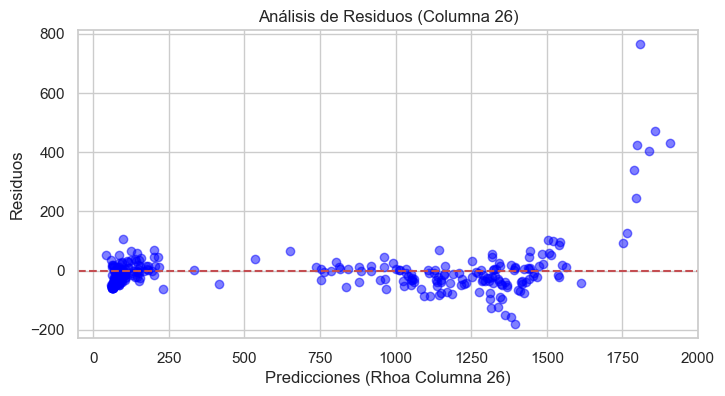

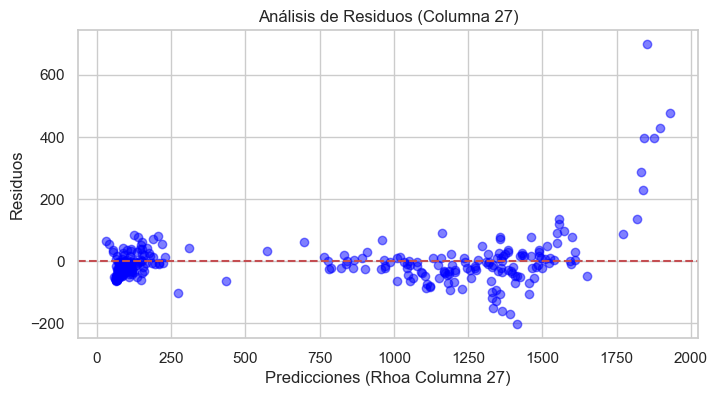

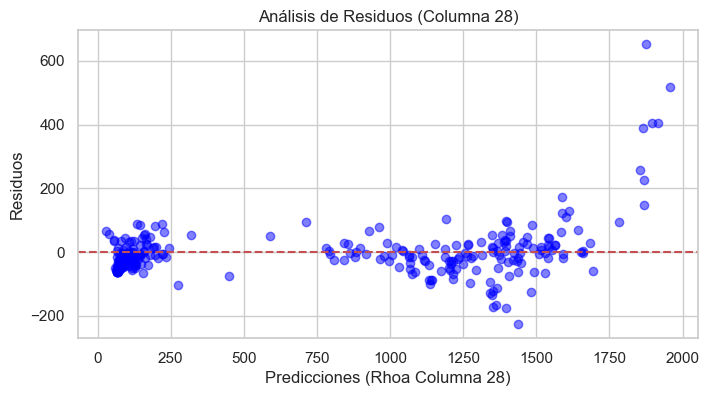

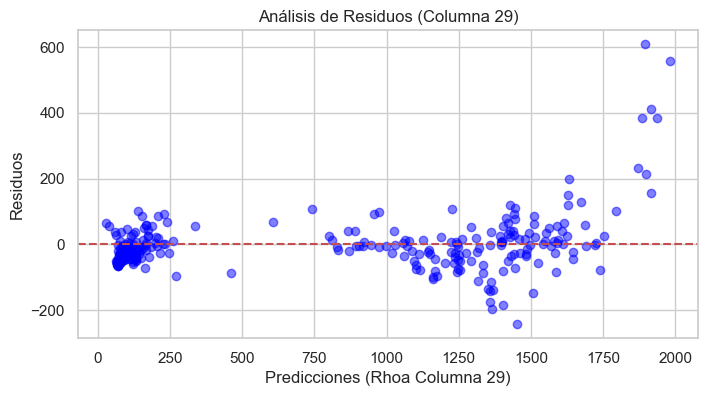

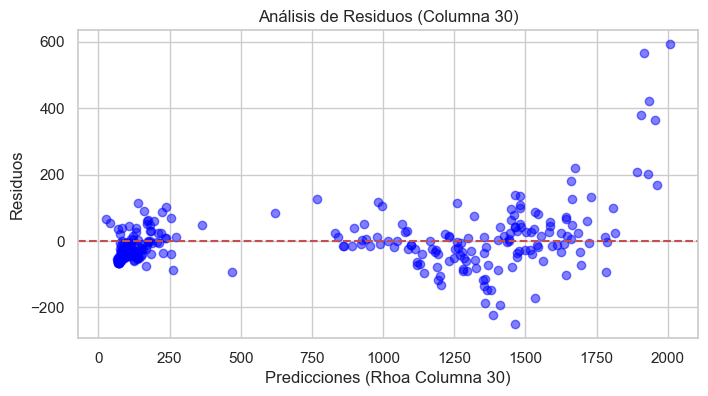

In [14]:

# Generar y guardar gráficos de residuos para las primeras 5 columnas
for i in range(30):
    plt.figure(figsize=(8, 4))
    plt.scatter(y_pred[:, i], residuals[:, i], c='blue', alpha=0.5)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel(f'Predicciones (Rhoa Columna {i+1})')
    plt.ylabel('Residuos')
    plt.title(f'Análisis de Residuos (Columna {i+1})')
    plt.grid(True)  # Agregar rejilla para mayor claridad
    # Guardar la imagen con un nombre único
    plt.savefig(f'svm_residual_plot_col_{i+1}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()  # Cerrar la figura para liberar memoria

# Support Vector Machine (SVM) V2   --- Descartada

In [122]:
# Definir parámetros para GridSearchCV (adaptado similar a RF)
param_grid_svm = {
    "C": [1, 10, 100, 150],#[1, 10, 100],
    "epsilon": [0.1, 0.2, 0.5, 0.9],#[0.1, 0.2, 0.5],
    "kernel": ['rbf', 'linear']#['rbf', 'linear']
}

# Modelo con GridSearchCV
svm = SVR(max_iter=50000)
svm_multi = MultiOutputRegressor(GridSearchCV(
    svm, param_grid_svm, cv=5, scoring="r2", n_jobs=-1, verbose=1))
svm_multi.fit(X_train, y_train)

# Guardar el modelo y columnas
joblib.dump(svm_multi, "svm_multioutput_v2.joblib")
joblib.dump(X_cols, "svm_feature_columns_v2.joblib")
print("Modelo SVM entrenado con GridSearchCV. Mejores parámetros disponibles en svm_multi.estimators_[0].best_params_.")

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=50000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Fitting 

In [130]:
# Predicciones
y_pred = svm_multi.predict(X_test)

# Asegurar que y_test y y_pred sean compatibles
y_test_array = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test
y_pred_array = np.array(y_pred)

# Verificar dimensiones
print(f"Shape y_test: {y_test_array.shape}, Shape y_pred: {y_pred_array.shape}")

# Métricas globales (promedio sobre todas las columnas)
mse_global = mean_squared_error(y_test_array, y_pred_array)
rmse_global = np.sqrt(mse_global)
mae_global = mean_absolute_error(y_test_array, y_pred_array)
r2_global = r2_score(y_test_array, y_pred_array, multioutput='uniform_average')

# MAPE por columna y global
def calculate_mape(y_true, y_pred):
    mape_values = []
    for i in range(y_true.shape[1]):
        mask = y_true[:, i] != 0
        if mask.sum() > 0:
            mape_col = np.mean(np.abs((y_true[mask, i] - y_pred[mask, i]) / y_true[mask, i])) * 100
            mape_values.append(mape_col)
    return np.mean(mape_values) if mape_values else np.nan

mape_global = calculate_mape(y_test_array, y_pred_array)

# Métricas por columna (ejemplo para las primeras 5 columnas)
for i in range(min(30, y_test_array.shape[1])):
    mse_col = mean_squared_error(y_test_array[:, i], y_pred_array[:, i])
    r2_col = r2_score(y_test_array[:, i], y_pred_array[:, i])
    print(f"Columna {i+1} - MSE: {mse_col:.4f}, R²: {r2_col:.4f}")

# Acceder a los mejores parámetros (corrección)
try:
    # Acceder al GridSearchCV interno del primer estimador
    best_params = svm_multi.estimators_[0].best_params_
    print("Mejores parámetros del primer target:", best_params)
except AttributeError:
    print("No se encontraron mejores parámetros. Asegúrate de que el modelo fue entrenado con GridSearchCV.")
    print("Parámetros usados en el SVR:", svm_multi.estimators_[0].get_params())

# Imprimir resultados globales
print(f"Score SVM (R² global): {r2_global:.4f}")
print(f"MSE global: {mse_global:.4f}")
print(f"RMSE global: {rmse_global:.4f}")
print(f"MAE global: {mae_global:.4f}")
print(f"MAPE global: {mape_global:.2f}%")

# Análisis estadístico de residuos (adaptado del libro: distribuciones y pruebas)
residuals = y_test_array - y_pred_array
residual_mean = np.mean(residuals)
residual_std = np.std(residuals)
print(f"Residuo medio global: {residual_mean:.4f}")
print(f"Desviación estándar de residuos global: {residual_std:.4f}")

for i in range(30):
    res_col = residuals[:, i]
    mean_res = np.mean(res_col)
    std_res = np.std(res_col)
    skew_res = skew(res_col)
    kurt_res = kurtosis(res_col)
    stat, p_value = shapiro(res_col[~np.isnan(res_col)])  # Prueba de normalidad
    print(f"Columna {i+1} - Residuo Media: {mean_res:.4f}, Std: {std_res:.4f}, Asimetría: {skew_res:.4f}, Curtosis: {kurt_res:.4f}, Shapiro-Wilk p-value: {p_value:.4f}")


Shape y_test: (347, 30), Shape y_pred: (347, 30)
Columna 1 - MSE: 14651.0811, R²: 0.7452
Columna 2 - MSE: 14409.8206, R²: 0.7485
Columna 3 - MSE: 13818.7349, R²: 0.7554
Columna 4 - MSE: 13425.4443, R²: 0.7593
Columna 5 - MSE: 13896.1843, R²: 0.7599
Columna 6 - MSE: 13162.8881, R²: 0.7952
Columna 7 - MSE: 13673.5835, R²: 0.8134
Columna 8 - MSE: 14382.7524, R²: 0.8289
Columna 9 - MSE: 15302.3746, R²: 0.8503
Columna 10 - MSE: 15814.3380, R²: 0.8692
Columna 11 - MSE: 15943.7699, R²: 0.8801
Columna 12 - MSE: 10184.9455, R²: 0.9330
Columna 13 - MSE: 15257.3026, R²: 0.9137
Columna 14 - MSE: 14852.7660, R²: 0.9215
Columna 15 - MSE: 14270.5600, R²: 0.9309
Columna 16 - MSE: 13263.0902, R²: 0.9421
Columna 17 - MSE: 12689.5820, R²: 0.9472
Columna 18 - MSE: 11769.2120, R²: 0.9552
Columna 19 - MSE: 10846.9000, R²: 0.9619
Columna 20 - MSE: 10566.7258, R²: 0.9641
Columna 21 - MSE: 9962.1555, R²: 0.9682
Columna 22 - MSE: 9478.9754, R²: 0.9715
Columna 23 - MSE: 9414.8911, R²: 0.9726
Columna 24 - MSE: 90

Columna: 1, MSE: 14651.0811, R²: 0.7452, Residuo Media: 18.8986, Std: 119.5572, Asimetría: 5.8594, Curtosis: 36.9387
Columna: 2, MSE: 14409.8206, R²: 0.7485, Residuo Media: 17.9133, Std: 118.6968, Asimetría: 5.9252, Curtosis: 37.6336
Columna: 3, MSE: 13818.7349, R²: 0.7554, Residuo Media: 15.6888, Std: 116.5015, Asimetría: 6.2826, Curtosis: 41.7749
Columna: 4, MSE: 13425.4443, R²: 0.7593, Residuo Media: 14.9283, Std: 114.9025, Asimetría: 6.5757, Curtosis: 45.0424
Columna: 5, MSE: 13896.1843, R²: 0.7599, Residuo Media: 14.5066, Std: 116.9861, Asimetría: 6.7511, Curtosis: 47.7943
Columna: 6, MSE: 13162.8881, R²: 0.7952, Residuo Media: 12.8725, Std: 114.0052, Asimetría: 6.6776, Curtosis: 47.9761
Columna: 7, MSE: 13673.5835, R²: 0.8134, Residuo Media: 12.3802, Std: 116.2769, Asimetría: 6.8375, Curtosis: 51.1665
Columna: 8, MSE: 14382.7524, R²: 0.8289, Residuo Media: 12.8276, Std: 119.2401, Asimetría: 6.9833, Curtosis: 54.0622
Columna: 9, MSE: 15302.3746, R²: 0.8503, Residuo Media: 14.0431, Std: 122.9031, Asimetría: 7.1456, Curtosis: 57.3901
Columna: 10, MSE: 15814.3380, R²: 0.8692, Residuo Media: 15.0564, Std: 124.8505, Asimetría: 7.3829, Curtosis: 60.9137
Columna: 11, MSE: 15943.7699, R²: 0.8801, Residuo Media: 15.3189, Std: 125.3360, Asimetría: 7.5059, Curtosis: 62.8305
Columna: 12, MSE: 10184.9455, R²: 0.9330, Residuo Media: 27.6769, Std: 97.0512, Asimetría: 0.1847, Curtosis: 3.6108
Columna: 13, MSE: 15257.3026, R²: 0.9137, Residuo Media: 15.7229, Std: 122.5157, Asimetría: 7.8949, Curtosis: 69.2260
Columna: 14, MSE: 14852.7660, R²: 0.9215, Residuo Media: 15.3424, Std: 120.9023, Asimetría: 7.9231, Curtosis: 69.9716
Columna: 15, MSE: 14270.5600, R²: 0.9309, Residuo Media: 15.4846, Std: 118.4516, Asimetría: 7.9533, Curtosis: 70.9557
Columna: 16, MSE: 13263.0902, R²: 0.9421, Residuo Media: 15.6826, Std: 114.0927, Asimetría: 7.9497, Curtosis: 71.6273
Columna: 17, MSE: 12689.5820, R²: 0.9472, Residuo Media: 15.4755, Std: 111.5800, Asimetría: 7.9892, Curtosis: 72.4312
Columna: 18, MSE: 11769.2120, R²: 0.9552, Residuo Media: 13.7641, Std: 107.6093, Asimetría: 7.9240, Curtosis: 72.1739
Columna: 19, MSE: 10846.9000, R²: 0.9619, Residuo Media: 13.3138, Std: 103.2940, Asimetría: 7.9557, Curtosis: 72.7461
Columna: 20, MSE: 10566.7258, R²: 0.9641, Residuo Media: 13.0811, Std: 101.9589, Asimetría: 7.9181, Curtosis: 72.0926
Columna: 21, MSE: 9962.1555, R²: 0.9682, Residuo Media: 12.7897, Std: 98.9878, Asimetría: 7.7833, Curtosis: 69.7732
Columna: 22, MSE: 9478.9754, R²: 0.9715, Residuo Media: 12.8470, Std: 96.5087, Asimetría: 7.5468, Curtosis: 65.9322
Columna: 23, MSE: 9414.8911, R²: 0.9726, Residuo Media: 12.6076, Std: 96.2078, Asimetría: 7.2205, Curtosis: 60.4537
Columna: 24, MSE: 9084.7935, R²: 0.9749, Residuo Media: 12.6515, Std: 94.4708, Asimetría: 6.8821, Curtosis: 55.3033
Columna: 25, MSE: 8890.3970, R²: 0.9766, Residuo Media: 12.7404, Std: 93.4242, Asimetría: 6.5142, Curtosis: 49.9584
Columna: 26, MSE: 8921.0581, R²: 0.9771, Residuo Media: 12.7265, Std: 93.5900, Asimetría: 6.1505, Curtosis: 44.8767
Columna: 27, MSE: 8624.9514, R²: 0.9790, Residuo Media: 11.9292, Std: 92.1013, Asimetría: 5.7113, Curtosis: 40.0890
Columna: 28, MSE: 8427.1903, R²: 0.9804, Residuo Media: 10.8214, Std: 91.1597, Asimetría: 5.2066, Curtosis: 35.2481
Columna: 29, MSE: 8425.1670, R²: 0.9813, Residuo Media: 9.4764, Std: 91.2982, Asimetría: 4.6222, Curtosis: 30.2665
Columna: 30, MSE: 8755.1161, R²: 0.9814, Residuo Media: 8.7419, Std: 93.1595, Asimetría: 4.0969, Curtosis: 26.0397


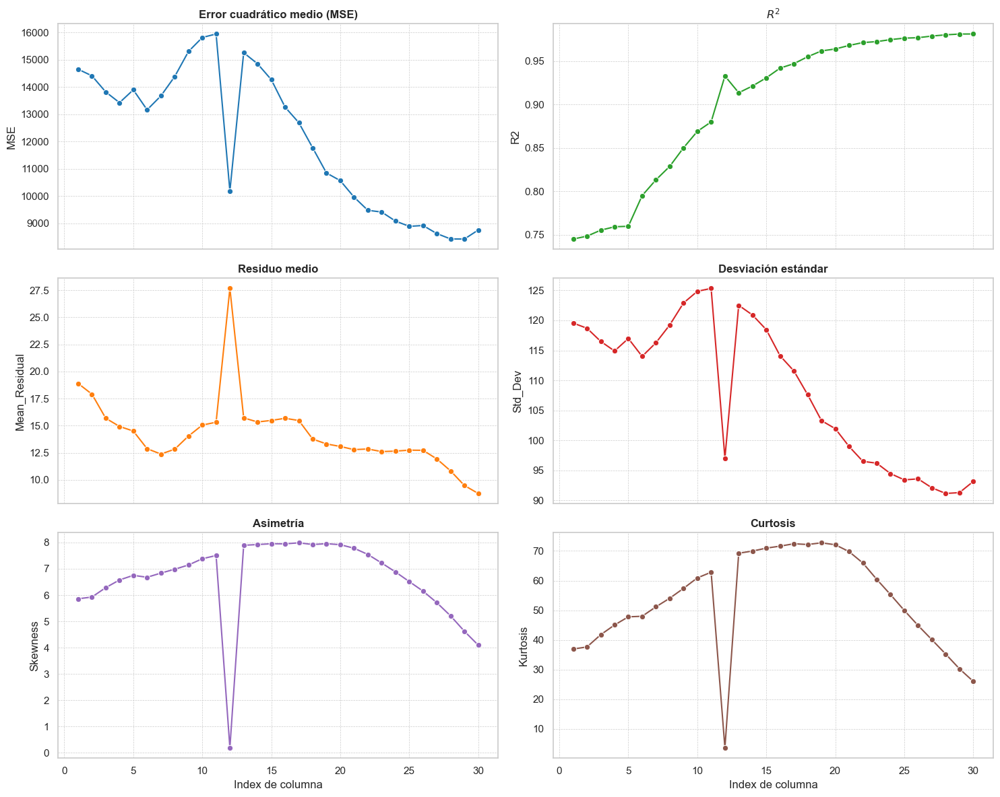

In [131]:
#################   CV=5

# 1. DATOS DE ENTRADA
# Copiamos el bloque de texto tal cual lo proporcionaste para evitar errores de transcripción
raw_data = """
Columna: 1, MSE: 14651.0811, R²: 0.7452, Residuo Media: 18.8986, Std: 119.5572, Asimetría: 5.8594, Curtosis: 36.9387
Columna: 2, MSE: 14409.8206, R²: 0.7485, Residuo Media: 17.9133, Std: 118.6968, Asimetría: 5.9252, Curtosis: 37.6336
Columna: 3, MSE: 13818.7349, R²: 0.7554, Residuo Media: 15.6888, Std: 116.5015, Asimetría: 6.2826, Curtosis: 41.7749
Columna: 4, MSE: 13425.4443, R²: 0.7593, Residuo Media: 14.9283, Std: 114.9025, Asimetría: 6.5757, Curtosis: 45.0424
Columna: 5, MSE: 13896.1843, R²: 0.7599, Residuo Media: 14.5066, Std: 116.9861, Asimetría: 6.7511, Curtosis: 47.7943
Columna: 6, MSE: 13162.8881, R²: 0.7952, Residuo Media: 12.8725, Std: 114.0052, Asimetría: 6.6776, Curtosis: 47.9761
Columna: 7, MSE: 13673.5835, R²: 0.8134, Residuo Media: 12.3802, Std: 116.2769, Asimetría: 6.8375, Curtosis: 51.1665
Columna: 8, MSE: 14382.7524, R²: 0.8289, Residuo Media: 12.8276, Std: 119.2401, Asimetría: 6.9833, Curtosis: 54.0622
Columna: 9, MSE: 15302.3746, R²: 0.8503, Residuo Media: 14.0431, Std: 122.9031, Asimetría: 7.1456, Curtosis: 57.3901
Columna: 10, MSE: 15814.3380, R²: 0.8692, Residuo Media: 15.0564, Std: 124.8505, Asimetría: 7.3829, Curtosis: 60.9137
Columna: 11, MSE: 15943.7699, R²: 0.8801, Residuo Media: 15.3189, Std: 125.3360, Asimetría: 7.5059, Curtosis: 62.8305
Columna: 12, MSE: 10184.9455, R²: 0.9330, Residuo Media: 27.6769, Std: 97.0512, Asimetría: 0.1847, Curtosis: 3.6108
Columna: 13, MSE: 15257.3026, R²: 0.9137, Residuo Media: 15.7229, Std: 122.5157, Asimetría: 7.8949, Curtosis: 69.2260
Columna: 14, MSE: 14852.7660, R²: 0.9215, Residuo Media: 15.3424, Std: 120.9023, Asimetría: 7.9231, Curtosis: 69.9716
Columna: 15, MSE: 14270.5600, R²: 0.9309, Residuo Media: 15.4846, Std: 118.4516, Asimetría: 7.9533, Curtosis: 70.9557
Columna: 16, MSE: 13263.0902, R²: 0.9421, Residuo Media: 15.6826, Std: 114.0927, Asimetría: 7.9497, Curtosis: 71.6273
Columna: 17, MSE: 12689.5820, R²: 0.9472, Residuo Media: 15.4755, Std: 111.5800, Asimetría: 7.9892, Curtosis: 72.4312
Columna: 18, MSE: 11769.2120, R²: 0.9552, Residuo Media: 13.7641, Std: 107.6093, Asimetría: 7.9240, Curtosis: 72.1739
Columna: 19, MSE: 10846.9000, R²: 0.9619, Residuo Media: 13.3138, Std: 103.2940, Asimetría: 7.9557, Curtosis: 72.7461
Columna: 20, MSE: 10566.7258, R²: 0.9641, Residuo Media: 13.0811, Std: 101.9589, Asimetría: 7.9181, Curtosis: 72.0926
Columna: 21, MSE: 9962.1555, R²: 0.9682, Residuo Media: 12.7897, Std: 98.9878, Asimetría: 7.7833, Curtosis: 69.7732
Columna: 22, MSE: 9478.9754, R²: 0.9715, Residuo Media: 12.8470, Std: 96.5087, Asimetría: 7.5468, Curtosis: 65.9322
Columna: 23, MSE: 9414.8911, R²: 0.9726, Residuo Media: 12.6076, Std: 96.2078, Asimetría: 7.2205, Curtosis: 60.4537
Columna: 24, MSE: 9084.7935, R²: 0.9749, Residuo Media: 12.6515, Std: 94.4708, Asimetría: 6.8821, Curtosis: 55.3033
Columna: 25, MSE: 8890.3970, R²: 0.9766, Residuo Media: 12.7404, Std: 93.4242, Asimetría: 6.5142, Curtosis: 49.9584
Columna: 26, MSE: 8921.0581, R²: 0.9771, Residuo Media: 12.7265, Std: 93.5900, Asimetría: 6.1505, Curtosis: 44.8767
Columna: 27, MSE: 8624.9514, R²: 0.9790, Residuo Media: 11.9292, Std: 92.1013, Asimetría: 5.7113, Curtosis: 40.0890
Columna: 28, MSE: 8427.1903, R²: 0.9804, Residuo Media: 10.8214, Std: 91.1597, Asimetría: 5.2066, Curtosis: 35.2481
Columna: 29, MSE: 8425.1670, R²: 0.9813, Residuo Media: 9.4764, Std: 91.2982, Asimetría: 4.6222, Curtosis: 30.2665
Columna: 30, MSE: 8755.1161, R²: 0.9814, Residuo Media: 8.7419, Std: 93.1595, Asimetría: 4.0969, Curtosis: 26.0397
"""

# 2. PROCESAMIENTO (PARSING)
rows = []
lines = raw_data.strip().split('\n')
for line in lines:
    parts = line.split(',')
    row_data = {}
    for part in parts:
        key, val = part.split(':')
        row_data[key.strip()] = float(val.strip())
    rows.append(row_data)

df = pd.DataFrame(rows)

# Renombrar columnas para facilitar manejo y estandarización (Paper en inglés)
df = df.rename(columns={
    'Columna': 'Index de columna',
    'MSE': 'MSE',
    'R²': 'R2',
    'Residuo Media': 'Mean_Residual',
    'Std': 'Std_Dev',
    'Asimetría': 'Skewness',
    'Curtosis': 'Kurtosis'
})

# 3. GRAFICACIÓN
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

# Lista de métricas y sus títulos
metrics = ['MSE', 'R2', 'Mean_Residual', 'Std_Dev', 'Skewness', 'Kurtosis']
titles = [
    'Error cuadrático medio (MSE)', 
    '$R^2$', 
    'Residuo medio', 
    'Desviación estándar', 
    'Asimetría', 
    'Curtosis'
]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red', 'tab:purple', 'tab:brown']

# Bucle para generar los 6 subgráficos
for i, metric in enumerate(metrics):
    sns.lineplot(ax=axes[i], x='Index de columna', y=metric, data=df, marker='o', color=colors[i])
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_ylabel(metric)
    # Mejora visual: añadir rejilla menor para lectura precisa
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)

# Ajustes finales
plt.xlabel('Index de columna')
plt.tight_layout()
plt.savefig('metricas_validacion_SVM_CV5.png', dpi=600)
plt.show() # O usar plt.savefig('metricas_validacion.png', dpi=300)

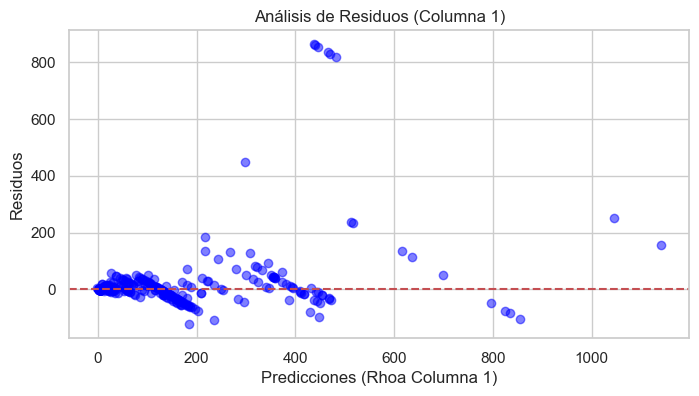

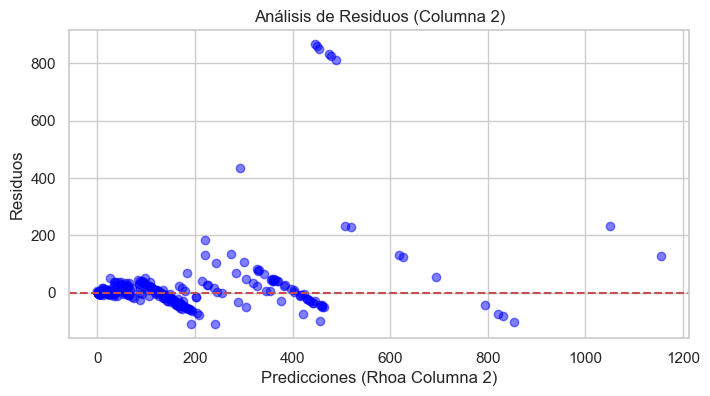

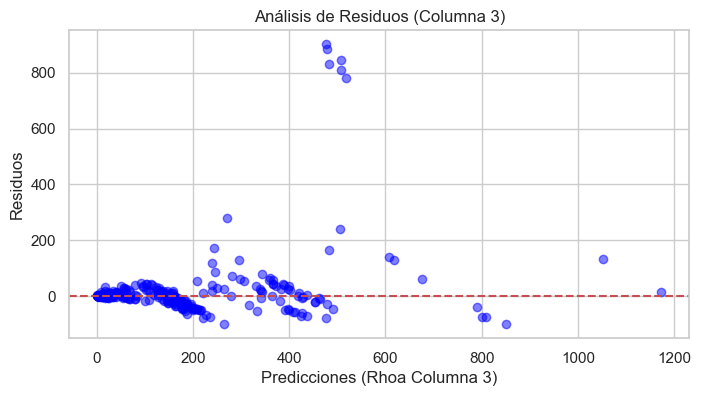

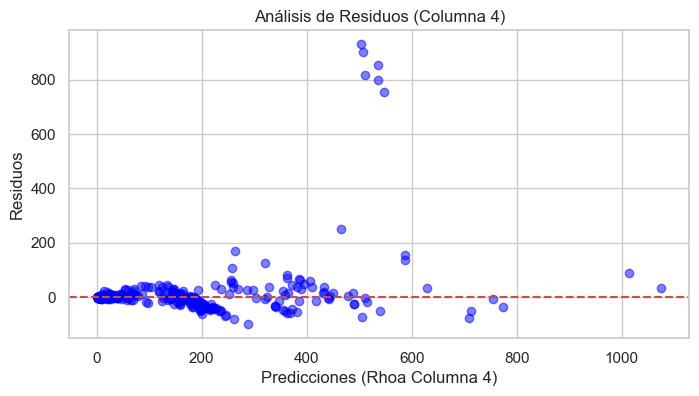

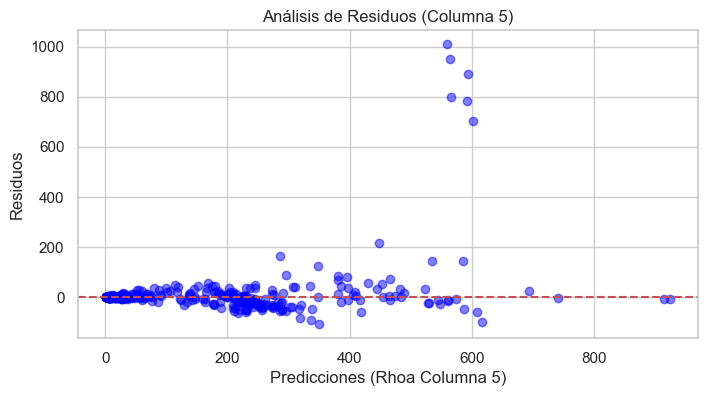

...

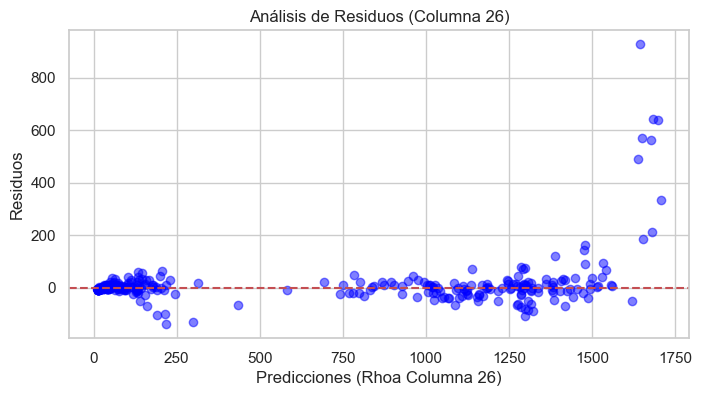

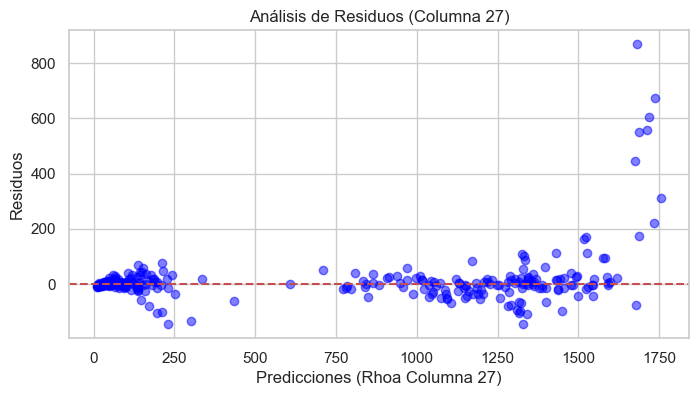

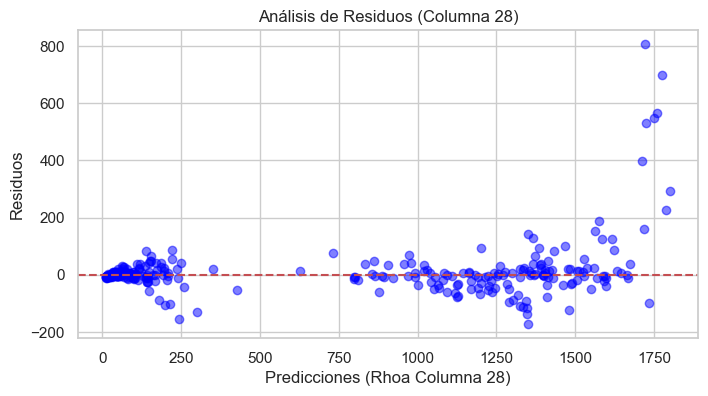

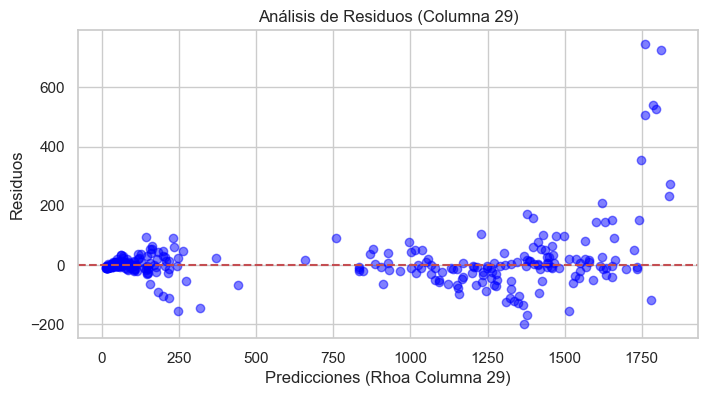

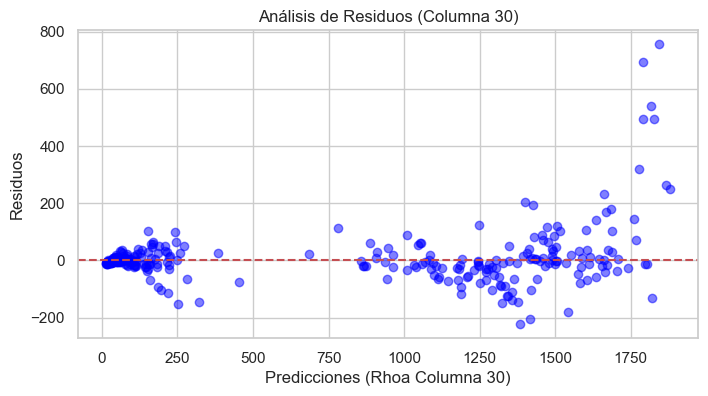

In [124]:

# Generar y guardar gráficos de residuos para las primeras 5 columnas
for i in range(30):
    plt.figure(figsize=(8, 4))
    plt.scatter(y_pred[:, i], residuals[:, i], c='blue', alpha=0.5)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel(f'Predicciones (Rhoa Columna {i+1})')
    plt.ylabel('Residuos')
    plt.title(f'Análisis de Residuos (Columna {i+1})')
    plt.grid(True)  # Agregar rejilla para mayor claridad
    # Guardar la imagen con un nombre único
    plt.savefig(f'svm_residual_plot_col_{i+1}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()  # Cerrar la figura para liberar memoria

RF
Shape y_test: (328, 30), Shape y_pred: (328, 30)
Columna 1 - MSE: 225.0519, R²: 0.9952
Columna 2 - MSE: 198.9564, R²: 0.9958
Columna 3 - MSE: 407.8908, R²: 0.9916
Columna 4 - MSE: 552.8918, R²: 0.9890
Columna 5 - MSE: 1697.3779, R²: 0.9692
Mejores parámetros del primer target: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Score RF (R² global): 0.9865
MSE global: 2296.3535
RMSE global: 47.9203
MAE global: 12.3811
MAPE global: 3.92%
Residuo medio global: 9.7690
Desviación estándar de residuos global: 46.9140

--------------------------------------------------

SVM --- max_iter=25000

Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 14377.4570, R²: 0.7389
Score SVM (R² global): 0.8749
MSE global: 15490.7104
RMSE global: 124.4617
MAE global: 44.5462
MAPE global: 121.23%

SVM --- max_iter=50000

Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 14377.4570, R²: 0.7389
Score SVM (R² global): 0.8771
MSE global: 14430.5729
RMSE global: 120.1273
MAE global: 41.4465
MAPE global: 94.18%

SVM --- max_iter=100000

Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 133910.3950, R²: -1.4323
Score SVM (R² global): 0.7845
MSE global: 22175.0023
RMSE global: 148.9127
MAE global: 71.7098
MAPE global: 386.73%


FR = R² CV promedio: 0.9852 (±0.0067)
SVM = R² CV promedio: 0.8594 (±0.0568) --- max_iter=25000
      R² CV promedio: 0.8722 (±0.0236) --- max_iter=50000
      R² CV promedio: 0.8049 (±0.1340) --- max_iter=100000

# Gradient Boosting Regressor (GBR) V2    ------- SELECCIONADA

In [15]:
# Definir parámetros para GridSearchCV (adaptado similar a SVM)
param_grid_gbr = {
    'n_estimators': [100, 200, 300, 500], #[100, 200],
    'learning_rate': [0.01, 0.1, 0.99],#[0.01, 0.1],
    'max_depth': [3, 5, 7, 10]#[3, 5]
}

# Modelo con GridSearchCV
gbr = GradientBoostingRegressor(random_state=42)
gbr_multi = MultiOutputRegressor(GridSearchCV(
    gbr, param_grid_gbr, cv=5, scoring="r2", n_jobs=-1, verbose=1))
gbr_multi.fit(X_train, y_train)

# Guardar el modelo y columnas
joblib.dump(gbr_multi, "gbr_multioutput_v2.joblib")
joblib.dump(X_cols, "gbr_feature_columns_v2.joblib")
print("Modelo GBR entrenado con GridSearchCV. Mejores parámetros disponibles en gbr_multi.estimators_[0].best_params_.")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Fitting 

Shape y_test: (347, 30), Shape y_pred: (347, 30)
Columna 1 - MSE: 396.4643, R²: 0.9931
Columna 2 - MSE: 426.3861, R²: 0.9926
Columna 3 - MSE: 210.7947, R²: 0.9963
Columna 4 - MSE: 244.2559, R²: 0.9956
Columna 5 - MSE: 821.1386, R²: 0.9858
Columna 6 - MSE: 1239.9517, R²: 0.9807
Columna 7 - MSE: 1296.8174, R²: 0.9823
Columna 8 - MSE: 1110.3594, R²: 0.9868
Columna 9 - MSE: 827.5601, R²: 0.9919
Columna 10 - MSE: 787.7813, R²: 0.9935
Columna 11 - MSE: 2722.3383, R²: 0.9795
Columna 12 - MSE: 2984.6336, R²: 0.9804
Columna 13 - MSE: 2919.6313, R²: 0.9835
Columna 14 - MSE: 2928.7910, R²: 0.9845
Columna 15 - MSE: 3076.4106, R²: 0.9851
Columna 16 - MSE: 3283.5684, R²: 0.9857
Columna 17 - MSE: 3568.5601, R²: 0.9851
Columna 18 - MSE: 2905.6785, R²: 0.9889
Columna 19 - MSE: 6118.8343, R²: 0.9785
Columna 20 - MSE: 6314.2807, R²: 0.9786
Columna 21 - MSE: 4518.9561, R²: 0.9856
Columna 22 - MSE: 4063.8293, R²: 0.9878
Columna 23 - MSE: 3374.3502, R²: 0.9902
Columna 24 - MSE: 3603.8433, R²: 0.9900
Columna

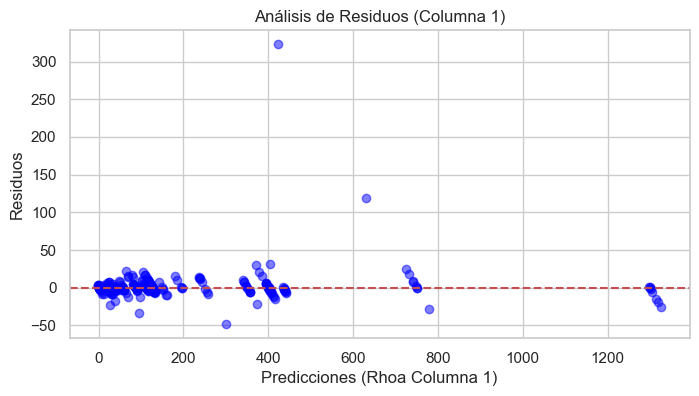

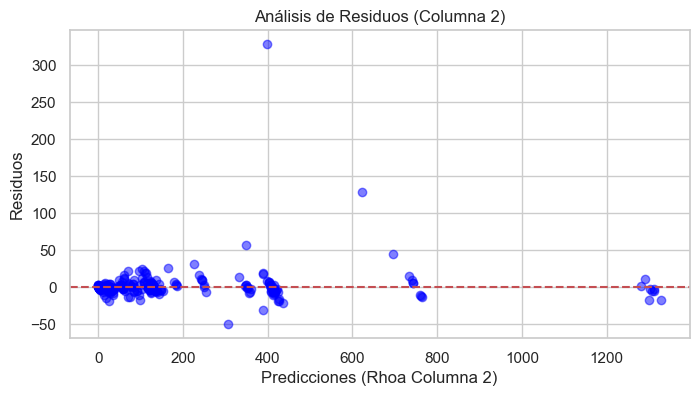

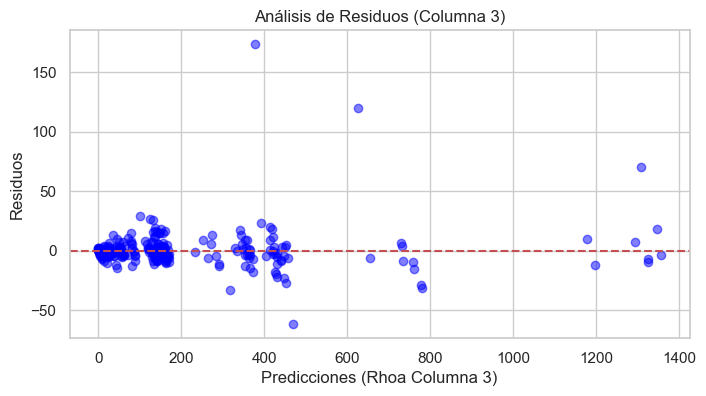

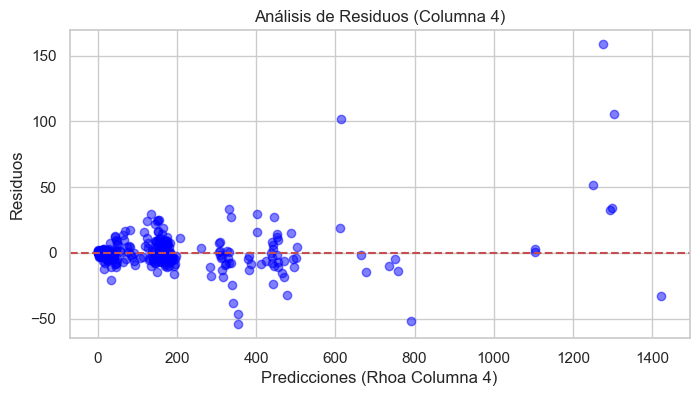

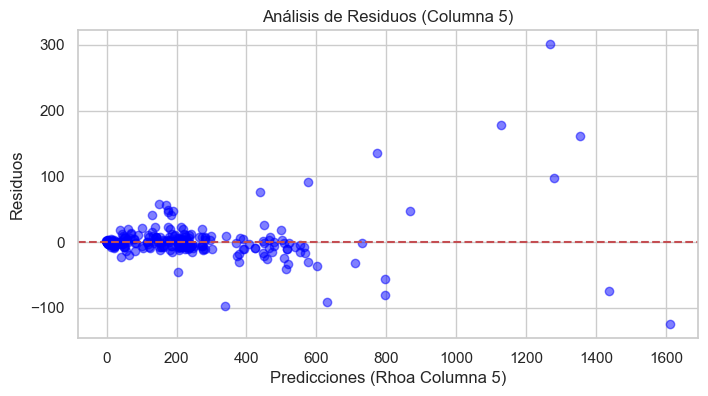

...

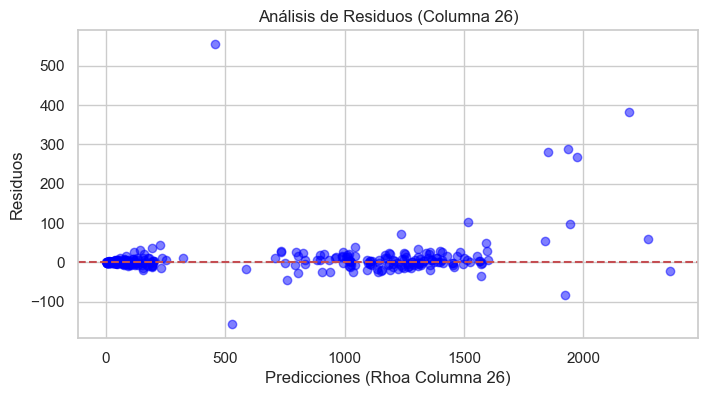

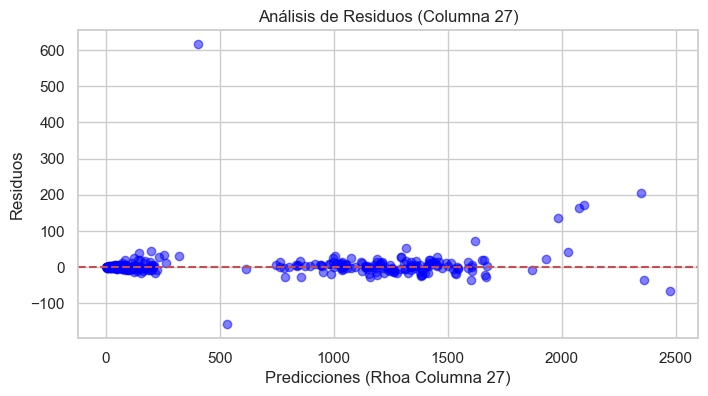

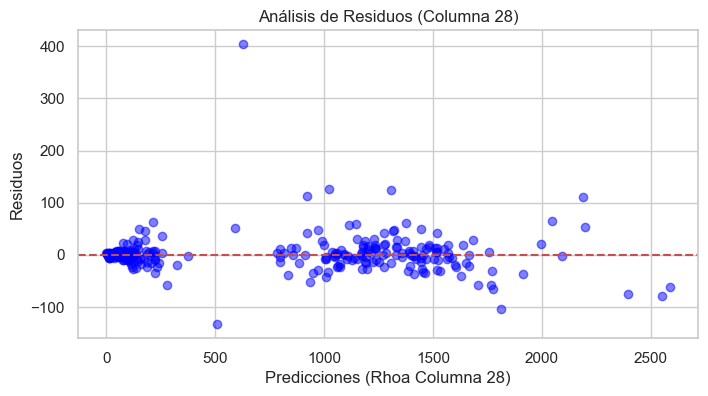

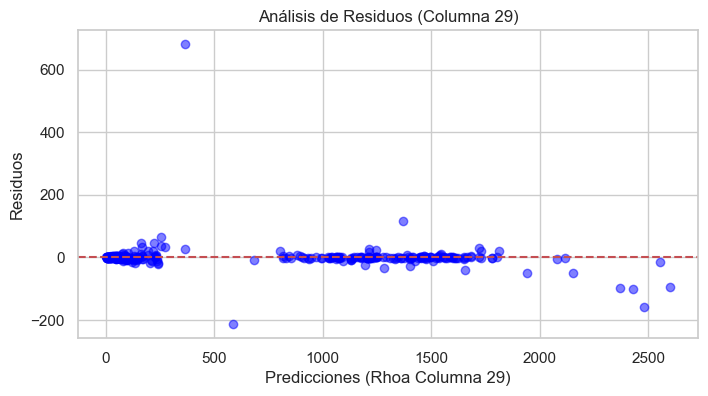

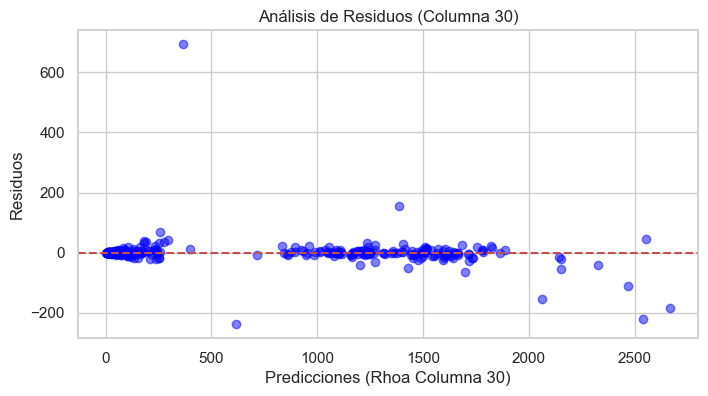

In [16]:
# Predicciones
y_pred = gbr_multi.predict(X_test)

# Asegurar que y_test y y_pred sean compatibles
y_test_array = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test
y_pred_array = np.array(y_pred)

# Verificar dimensiones
print(f"Shape y_test: {y_test_array.shape}, Shape y_pred: {y_pred_array.shape}")

# Métricas globales (promedio sobre todas las columnas)
mse_global = mean_squared_error(y_test_array, y_pred_array)
rmse_global = np.sqrt(mse_global)
mae_global = mean_absolute_error(y_test_array, y_pred_array)
r2_global = r2_score(y_test_array, y_pred_array, multioutput='uniform_average')

# MAPE por columna y global
def calculate_mape(y_true, y_pred):
    mape_values = []
    for i in range(y_true.shape[1]):
        mask = y_true[:, i] != 0
        if mask.sum() > 0:
            mape_col = np.mean(np.abs((y_true[mask, i] - y_pred[mask, i]) / y_true[mask, i])) * 100
            mape_values.append(mape_col)
    return np.mean(mape_values) if mape_values else np.nan

mape_global = calculate_mape(y_test_array, y_pred_array)

# Métricas por columna (ejemplo para las primeras 5 columnas)
for i in range(min(30, y_test_array.shape[1])):
    mse_col = mean_squared_error(y_test_array[:, i], y_pred_array[:, i])
    r2_col = r2_score(y_test_array[:, i], y_pred_array[:, i])
    print(f"Columna {i+1} - MSE: {mse_col:.4f}, R²: {r2_col:.4f}")

# Acceder a los mejores parámetros (corrección)
try:
    # Acceder al GridSearchCV interno del primer estimador
    best_params = gbr_multi.estimators_[0].best_params_
    print("Mejores parámetros del primer target:", best_params)
except AttributeError:
    print("No se encontraron mejores parámetros. Asegúrate de que el modelo fue entrenado con GridSearchCV.")
    print("Parámetros usados en el GradientBoostingRegressor:", gbr_multi.estimators_[0].get_params())

# Imprimir resultados globales
print(f"Score GBR (R² global): {r2_global:.4f}")
print(f"MSE global: {mse_global:.4f}")
print(f"RMSE global: {rmse_global:.4f}")
print(f"MAE global: {mae_global:.4f}")
print(f"MAPE global: {mape_global:.2f}%")

# Análisis estadístico de residuos (adaptado del libro: distribuciones y pruebas)
residuals = y_test_array - y_pred_array
residual_mean = np.mean(residuals)
residual_std = np.std(residuals)
print(f"Residuo medio global: {residual_mean:.4f}")
print(f"Desviación estándar de residuos global: {residual_std:.4f}")

for i in range(30):
    res_col = residuals[:, i]
    mean_res = np.mean(res_col)
    std_res = np.std(res_col)
    skew_res = skew(res_col)
    kurt_res = kurtosis(res_col)
    stat, p_value = shapiro(res_col[~np.isnan(res_col)])  # Prueba de normalidad
    print(f"Columna {i+1} - Residuo Media: {mean_res:.4f}, Std: {std_res:.4f}, Asimetría: {skew_res:.4f}, Curtosis: {kurt_res:.4f}, Shapiro-Wilk p-value: {p_value:.4f}")

# Gráficos de residuos
for i in range(30):
    plt.figure(figsize=(8, 4))
    plt.scatter(y_pred_array[:, i], residuals[:, i], c='blue', alpha=0.5)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel(f'Predicciones (Rhoa Columna {i+1})')
    plt.ylabel('Residuos')
    plt.title(f'Análisis de Residuos (Columna {i+1})')
    plt.grid(True)
    plt.savefig(f'gbr_residual_plot_col_{i+1}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()


Columna: 1, MSE: 396.4643, R²: 0.9931, Residuo Media: 1.2300, Std: 19.8734, Asimetría: 12.7695, Curtosis: 198.7380
Columna: 2, MSE: 426.3861, R²: 0.9926, Residuo Media: 1.5711, Std: 20.5893, Asimetría: 12.2025, Curtosis: 183.9603
Columna: 3, MSE: 210.7947, R²: 0.9963, Residuo Media: 0.5862, Std: 14.5069, Asimetría: 6.5341, Curtosis: 71.5436
Columna: 4, MSE: 244.2559, R²: 0.9956, Residuo Media: 0.8002, Std: 15.6082, Asimetría: 4.4674, Curtosis: 40.1631
Columna: 5, MSE: 821.1386, R²: 0.9858, Residuo Media: 1.2330, Std: 28.6290, Asimetría: 4.4820, Curtosis: 43.1516
Columna: 6, MSE: 1239.9517, R²: 0.9807, Residuo Media: 2.7462, Std: 35.1057, Asimetría: 4.8158, Curtosis: 36.3486
Columna: 7, MSE: 1296.8174, R²: 0.9823, Residuo Media: 4.4782, Std: 35.7318, Asimetría: 6.2297, Curtosis: 56.1501
Columna: 8, MSE: 1110.3594, R²: 0.9868, Residuo Media: 3.1771, Std: 33.1703, Asimetría: 4.6689, Curtosis: 46.1681
Columna: 9, MSE: 827.5601, R²: 0.9919, Residuo Media: 2.7031, Std: 28.6401, Asimetría: 5.8453, Curtosis: 59.6795
Columna: 10, MSE: 787.7813, R²: 0.9935, Residuo Media: 3.9160, Std: 27.7929, Asimetría: 6.9041, Curtosis: 61.1699
Columna: 11, MSE: 2722.3383, R²: 0.9795, Residuo Media: 8.7891, Std: 51.4304, Asimetría: 8.5314, Curtosis: 79.8390
Columna: 12, MSE: 2984.6336, R²: 0.9804, Residuo Media: 8.9811, Std: 53.8885, Asimetría: 7.8899, Curtosis: 70.2374
Columna: 13, MSE: 2919.6313, R²: 0.9835, Residuo Media: 8.8812, Std: 53.2987, Asimetría: 7.8534, Curtosis: 75.3181
Columna: 14, MSE: 2928.7910, R²: 0.9845, Residuo Media: 8.3072, Std: 53.4769, Asimetría: 8.1042, Curtosis: 82.1989
Columna: 15, MSE: 3076.4106, R²: 0.9851, Residuo Media: 7.3022, Std: 54.9826, Asimetría: 8.8074, Curtosis: 95.6479
Columna: 16, MSE: 3283.5684, R²: 0.9857, Residuo Media: 7.1158, Std: 56.8589, Asimetría: 10.2648, Curtosis: 141.8309
Columna: 17, MSE: 3568.5601, R²: 0.9851, Residuo Media: 6.6896, Std: 59.3617, Asimetría: 9.0888, Curtosis: 111.5702
Columna: 18, MSE: 2905.6785, R²: 0.9889, Residuo Media: 6.2805, Std: 53.5372, Asimetría: 7.1015, Curtosis: 67.2915
Columna: 19, MSE: 6118.8343, R²: 0.9785, Residuo Media: 10.7392, Std: 77.4823, Asimetría: 13.7887, Curtosis: 217.3084
Columna: 20, MSE: 6314.2807, R²: 0.9786, Residuo Media: 10.0950, Std: 78.8186, Asimetría: 13.8572, Curtosis: 216.5034
Columna: 21, MSE: 4518.9561, R²: 0.9856, Residuo Media: 10.7695, Std: 66.3549, Asimetría: 12.3518, Curtosis: 178.4985
Columna: 22, MSE: 4063.8293, R²: 0.9878, Residuo Media: 10.3534, Std: 62.9018, Asimetría: 10.7608, Curtosis: 138.5977
Columna: 23, MSE: 3374.3502, R²: 0.9902, Residuo Media: 10.1830, Std: 57.1897, Asimetría: 10.3410, Curtosis: 128.5735
Columna: 24, MSE: 3603.8433, R²: 0.9900, Residuo Media: 9.6035, Std: 59.2589, Asimetría: 9.4088, Curtosis: 107.6691
Columna: 25, MSE: 3147.3341, R²: 0.9917, Residuo Media: 8.7732, Std: 55.4109, Asimetría: 8.4773, Curtosis: 85.2933
Columna: 26, MSE: 2276.3013, R²: 0.9942, Residuo Media: 7.1854, Std: 47.1664, Asimetría: 7.4736, Curtosis: 70.5818
Columna: 27, MSE: 1647.6870, R²: 0.9960, Residuo Media: 4.6155, Std: 40.3285, Asimetría: 10.6790, Curtosis: 153.8392
Columna: 28, MSE: 1082.7931, R²: 0.9975, Residuo Media: 1.4447, Std: 32.8741, Asimetría: 5.4330, Curtosis: 65.4646
Columna: 29, MSE: 1758.2669, R²: 0.9961, Residuo Media: 0.6365, Std: 41.9269, Asimetría: 11.7469, Curtosis: 200.1167
Columna: 30, MSE: 2103.0844, R²: 0.9955, Residuo Media: 0.4367, Std: 45.8573, Asimetría: 8.9747, Curtosis: 152.2202


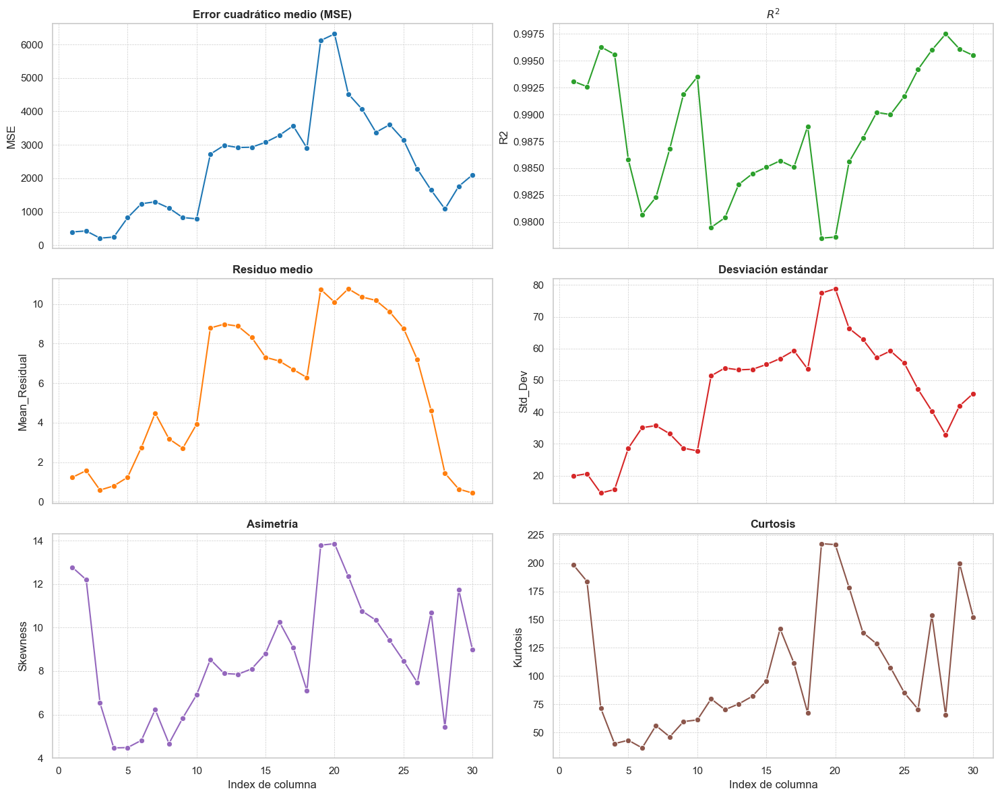

In [17]:
######## Gradient Boosting Regressor (GBR)
########  CV=5

# 1. DATOS DE ENTRADA
# Copiamos el bloque de texto tal cual lo proporcionaste para evitar errores de transcripción
raw_data = """
Columna: 1, MSE: 396.4643, R²: 0.9931, Residuo Media: 1.2300, Std: 19.8734, Asimetría: 12.7695, Curtosis: 198.7380
Columna: 2, MSE: 426.3861, R²: 0.9926, Residuo Media: 1.5711, Std: 20.5893, Asimetría: 12.2025, Curtosis: 183.9603
Columna: 3, MSE: 210.7947, R²: 0.9963, Residuo Media: 0.5862, Std: 14.5069, Asimetría: 6.5341, Curtosis: 71.5436
Columna: 4, MSE: 244.2559, R²: 0.9956, Residuo Media: 0.8002, Std: 15.6082, Asimetría: 4.4674, Curtosis: 40.1631
Columna: 5, MSE: 821.1386, R²: 0.9858, Residuo Media: 1.2330, Std: 28.6290, Asimetría: 4.4820, Curtosis: 43.1516
Columna: 6, MSE: 1239.9517, R²: 0.9807, Residuo Media: 2.7462, Std: 35.1057, Asimetría: 4.8158, Curtosis: 36.3486
Columna: 7, MSE: 1296.8174, R²: 0.9823, Residuo Media: 4.4782, Std: 35.7318, Asimetría: 6.2297, Curtosis: 56.1501
Columna: 8, MSE: 1110.3594, R²: 0.9868, Residuo Media: 3.1771, Std: 33.1703, Asimetría: 4.6689, Curtosis: 46.1681
Columna: 9, MSE: 827.5601, R²: 0.9919, Residuo Media: 2.7031, Std: 28.6401, Asimetría: 5.8453, Curtosis: 59.6795
Columna: 10, MSE: 787.7813, R²: 0.9935, Residuo Media: 3.9160, Std: 27.7929, Asimetría: 6.9041, Curtosis: 61.1699
Columna: 11, MSE: 2722.3383, R²: 0.9795, Residuo Media: 8.7891, Std: 51.4304, Asimetría: 8.5314, Curtosis: 79.8390
Columna: 12, MSE: 2984.6336, R²: 0.9804, Residuo Media: 8.9811, Std: 53.8885, Asimetría: 7.8899, Curtosis: 70.2374
Columna: 13, MSE: 2919.6313, R²: 0.9835, Residuo Media: 8.8812, Std: 53.2987, Asimetría: 7.8534, Curtosis: 75.3181
Columna: 14, MSE: 2928.7910, R²: 0.9845, Residuo Media: 8.3072, Std: 53.4769, Asimetría: 8.1042, Curtosis: 82.1989
Columna: 15, MSE: 3076.4106, R²: 0.9851, Residuo Media: 7.3022, Std: 54.9826, Asimetría: 8.8074, Curtosis: 95.6479
Columna: 16, MSE: 3283.5684, R²: 0.9857, Residuo Media: 7.1158, Std: 56.8589, Asimetría: 10.2648, Curtosis: 141.8309
Columna: 17, MSE: 3568.5601, R²: 0.9851, Residuo Media: 6.6896, Std: 59.3617, Asimetría: 9.0888, Curtosis: 111.5702
Columna: 18, MSE: 2905.6785, R²: 0.9889, Residuo Media: 6.2805, Std: 53.5372, Asimetría: 7.1015, Curtosis: 67.2915
Columna: 19, MSE: 6118.8343, R²: 0.9785, Residuo Media: 10.7392, Std: 77.4823, Asimetría: 13.7887, Curtosis: 217.3084
Columna: 20, MSE: 6314.2807, R²: 0.9786, Residuo Media: 10.0950, Std: 78.8186, Asimetría: 13.8572, Curtosis: 216.5034
Columna: 21, MSE: 4518.9561, R²: 0.9856, Residuo Media: 10.7695, Std: 66.3549, Asimetría: 12.3518, Curtosis: 178.4985
Columna: 22, MSE: 4063.8293, R²: 0.9878, Residuo Media: 10.3534, Std: 62.9018, Asimetría: 10.7608, Curtosis: 138.5977
Columna: 23, MSE: 3374.3502, R²: 0.9902, Residuo Media: 10.1830, Std: 57.1897, Asimetría: 10.3410, Curtosis: 128.5735
Columna: 24, MSE: 3603.8433, R²: 0.9900, Residuo Media: 9.6035, Std: 59.2589, Asimetría: 9.4088, Curtosis: 107.6691
Columna: 25, MSE: 3147.3341, R²: 0.9917, Residuo Media: 8.7732, Std: 55.4109, Asimetría: 8.4773, Curtosis: 85.2933
Columna: 26, MSE: 2276.3013, R²: 0.9942, Residuo Media: 7.1854, Std: 47.1664, Asimetría: 7.4736, Curtosis: 70.5818
Columna: 27, MSE: 1647.6870, R²: 0.9960, Residuo Media: 4.6155, Std: 40.3285, Asimetría: 10.6790, Curtosis: 153.8392
Columna: 28, MSE: 1082.7931, R²: 0.9975, Residuo Media: 1.4447, Std: 32.8741, Asimetría: 5.4330, Curtosis: 65.4646
Columna: 29, MSE: 1758.2669, R²: 0.9961, Residuo Media: 0.6365, Std: 41.9269, Asimetría: 11.7469, Curtosis: 200.1167
Columna: 30, MSE: 2103.0844, R²: 0.9955, Residuo Media: 0.4367, Std: 45.8573, Asimetría: 8.9747, Curtosis: 152.2202
"""

# 2. PROCESAMIENTO (PARSING)
rows = []
lines = raw_data.strip().split('\n')
for line in lines:
    parts = line.split(',')
    row_data = {}
    for part in parts:
        key, val = part.split(':')
        row_data[key.strip()] = float(val.strip())
    rows.append(row_data)

df = pd.DataFrame(rows)

# Renombrar columnas para facilitar manejo y estandarización (Paper en inglés)
df = df.rename(columns={
    'Columna': 'Index de columna',
    'MSE': 'MSE',
    'R²': 'R2',
    'Residuo Media': 'Mean_Residual',
    'Std': 'Std_Dev',
    'Asimetría': 'Skewness',
    'Curtosis': 'Kurtosis'
})

# 3. GRAFICACIÓN
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

# Lista de métricas y sus títulos
metrics = ['MSE', 'R2', 'Mean_Residual', 'Std_Dev', 'Skewness', 'Kurtosis']
titles = [
    'Error cuadrático medio (MSE)', 
    '$R^2$', 
    'Residuo medio', 
    'Desviación estándar', 
    'Asimetría', 
    'Curtosis'
]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red', 'tab:purple', 'tab:brown']

# Bucle para generar los 6 subgráficos
for i, metric in enumerate(metrics):
    sns.lineplot(ax=axes[i], x='Index de columna', y=metric, data=df, marker='o', color=colors[i])
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_ylabel(metric)
    # Mejora visual: añadir rejilla menor para lectura precisa
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.5)

# Ajustes finales
plt.xlabel('Index de columna')
plt.tight_layout()
plt.savefig('metricas_validacion_GBR_CV5.png', dpi=600)
plt.show() # O usar plt.savefig('metricas_validacion.png', dpi=300)

GRB

Columna 1 - MSE: 94.3834, R²: 0.9980
Columna 2 - MSE: 358.9965, R²: 0.9924
Columna 3 - MSE: 475.4980, R²: 0.9902
Columna 4 - MSE: 358.6226, R²: 0.9928
Columna 5 - MSE: 593.6401, R²: 0.9892
Score GBR (R² global): 0.9880
MSE global: 2356.5881
RMSE global: 48.5447
MAE global: 15.7448
MAPE global: 10.65%

GRB v2   ------------  SELECCIONADA

Shape y_test: (328, 30), Shape y_pred: (328, 30)
Columna 1 - MSE: 94.3834, R²: 0.9980
Columna 2 - MSE: 358.9965, R²: 0.9924
Columna 3 - MSE: 475.4980, R²: 0.9902
Columna 4 - MSE: 358.6226, R²: 0.9928
Columna 5 - MSE: 593.6401, R²: 0.9892
Mejores parámetros del primer target: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Score GBR (R² global): 0.9880
MSE global: 2356.5881
RMSE global: 48.5447
MAE global: 15.7448
MAPE global: 10.65%

---------------------------------------------------

RF ----- SELECCIONADA
Shape y_test: (328, 30), Shape y_pred: (328, 30)
Columna 1 - MSE: 225.0519, R²: 0.9952
Columna 2 - MSE: 198.9564, R²: 0.9958
Columna 3 - MSE: 407.8908, R²: 0.9916
Columna 4 - MSE: 552.8918, R²: 0.9890
Columna 5 - MSE: 1697.3779, R²: 0.9692
Mejores parámetros del primer target: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Score RF (R² global): 0.9865
MSE global: 2296.3535
RMSE global: 47.9203
MAE global: 12.3811
MAPE global: 3.92%
Residuo medio global: 9.7690
Desviación estándar de residuos global: 46.9140

--------------------------------------------------

SVM --- max_iter=25000

Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 14377.4570, R²: 0.7389
Score SVM (R² global): 0.8749
MSE global: 15490.7104
RMSE global: 124.4617
MAE global: 44.5462
MAPE global: 121.23%

SVM --- max_iter=50000

Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 14377.4570, R²: 0.7389
Score SVM (R² global): 0.8771
MSE global: 14430.5729
RMSE global: 120.1273
MAE global: 41.4465
MAPE global: 94.18%

SVM --- max_iter=100000

Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 133910.3950, R²: -1.4323
Score SVM (R² global): 0.7845
MSE global: 22175.0023
RMSE global: 148.9127
MAE global: 71.7098
MAPE global: 386.73%


SVM v2-- SELECCIONADA

Shape y_test: (328, 30), Shape y_pred: (328, 30)
Columna 1 - MSE: 13119.8863, R²: 0.7191
Columna 2 - MSE: 13062.4238, R²: 0.7226
Columna 3 - MSE: 13088.4034, R²: 0.7315
Columna 4 - MSE: 13159.0328, R²: 0.7372
Columna 5 - MSE: 14377.4570, R²: 0.7389
Mejores parámetros del primer target: {'C': 100, 'epsilon': 0.5, 'kernel': 'rbf'}
Score SVM (R² global): 0.8771
MSE global: 14430.5729
RMSE global: 120.1273
MAE global: 41.4465
MAPE global: 94.18%

GBR = R² CV promedio: 0.9832 (±0.0059)
FR = R² CV promedio: 0.9852 (±0.0067)
SVM = R² CV promedio: 0.8594 (±0.0568) --- max_iter=25000
      R² CV promedio: 0.8722 (±0.0236) --- max_iter=50000
      R² CV promedio: 0.8049 (±0.1340) --- max_iter=100000


RF  cv=3

Mejores parámetros del primer target: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100}
Score RF (R² global): 0.9889
MSE global: 2003.1724
RMSE global: 44.7568
MAE global: 11.0893
MAPE global: 4.59%
Residuo medio global: 9.3165
Desviación estándar de residuos global: 43.7764

RF  cv=5

Mejores parámetros del primer target: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Score RF (R² global): 0.9892
MSE global: 1943.8695
RMSE global: 44.0893
MAE global: 11.0689
MAPE global: 4.04%
Residuo medio global: 9.2626
Desviación estándar de residuos global: 43.1054

VSM cv=3

Mejores parámetros del primer target: {'C': 100, 'epsilon': 0.5, 'kernel': 'rbf'}
Score SVM (R² global): 0.8915
MSE global: 13592.6816
RMSE global: 116.5877
MAE global: 45.6039
MAPE global: 131.24%
Residuo medio global: 14.2944
Desviación estándar de residuos global: 115.7080

VSM cv=5

Mejores parámetros del primer target: {'C': 150, 'epsilon': 0.9, 'kernel': 'rbf'}
Score SVM (R² global): 0.9013
MSE global: 12072.2250
RMSE global: 109.8737
MAE global: 33.9187
MAPE global: 30.48%
Residuo medio global: 14.2437
Desviación estándar de residuos global: 108.9465

GBR cv=3

Mejores parámetros del primer target: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Score GBR (R² global): 0.9903
MSE global: 1891.7343
RMSE global: 43.4941
MAE global: 15.1317
MAPE global: 10.48%
Residuo medio global: 5.1651
Desviación estándar de residuos global: 43.1863

GBR cv=5

Mejores parámetros del primer target: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500}
Score GBR (R² global): 0.9884
MSE global: 2392.0227
RMSE global: 48.9083
MAE global: 13.0453
MAPE global: 9.51%
Residuo medio global: 5.6541
Desviación estándar de residuos global: 48.5804

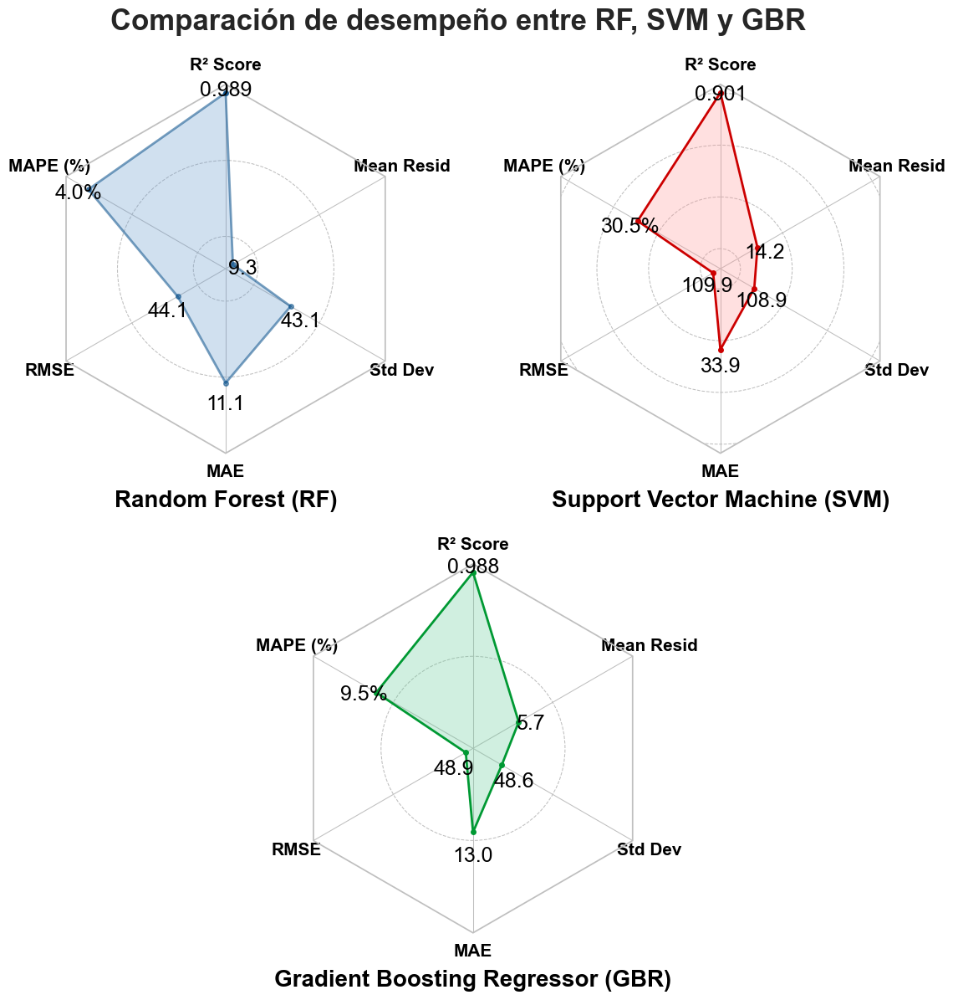

In [18]:


# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='circle'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        RESOLUTION = 1
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines:
                self._close_line(line)
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0])
                y = np.append(y, y[0])
                line.set_data(x, y)
        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)
        def _gen_axes_patch(self):
            if frame == 'circle': return Circle((0.5, 0.5), 0.5)
            elif frame == 'polygon': return RegularPolygon((0.5, 0.5), num_vars, radius=0.5, edgecolor="k")
            else: raise ValueError("unknown value for 'frame': %s" % frame)
        def _gen_axes_spines(self):
            if frame == 'circle': return super()._gen_axes_spines()
            elif frame == 'polygon':
                spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
                spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
                return {'polar': spine}
            else: raise ValueError("unknown value for 'frame': %s" % frame)
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS REALES ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']
models_data = {
    'Random Forest (RF)': [0.9892, 4.04, 44.0893, 11.0689, 43.1054, 9.2626],
    'Support Vector Machine (SVM)': [0.9013, 30.48, 109.8737, 33.9187, 108.9465, 14.2437],
    'Gradient Boosting Regressor (GBR)': [0.9884, 9.51, 48.9083, 13.0453, 48.5804, 5.6541]
}


# --- 3. DEFINICIÓN DE LÍMITES UNIFICADOS (ESCALA FIJA) ---
limits = {
    'R² Score': 0.5,      
    'MAPE (%)': 60.0,    
    'RMSE': 130.0,        
    'MAE': 60.0,          
    'Std Dev': 150.0,     
    'Mean Resid': 20.0    
}

def normalize_data(values):
    norm_list = []
    # R2: Mayor es mejor
    val_r2 = values[0]
    norm_r2 = (val_r2 - limits['R² Score']) / (1.0 - limits['R² Score'])
    norm_list.append(max(0.01, norm_r2))
    
    # Errores: Menor es mejor (Inversión)
    for i in range(1, len(values)):
        metric = metrics[i]
        val = values[i]
        limit = limits[metric]
        norm = 1 - (val / limit)
        norm_list.append(max(0.01, norm))
    return norm_list

# --- 4. GRAFICACIÓN ---
theta = radar_factory(6, frame='polygon')

bg_color = 'white'
text_color = "#000000"
line_colors = ["#004a8789", '#cc0000', '#009933'] # Azul, Rojo, Verde
fill_colors = ['#6699cc', '#ff9999', '#66cc99']

# --- MODIFICACIÓN DE LA DISTRIBUCIÓN ---
# Usamos GridSpec para crear una cuadrícula de 2 filas x 4 columnas.
# Fila 1: Ocupa espacios [0:2] y [2:4].
# Fila 2: Ocupa el espacio central [1:3].
fig = plt.figure(figsize=(14, 13)) 
fig.patch.set_facecolor(bg_color)
gs = fig.add_gridspec(2, 4, wspace=0.5, hspace=0.3)

ax1 = fig.add_subplot(gs[0, 0:2], projection='radar')
ax2 = fig.add_subplot(gs[0, 2:4], projection='radar')
ax3 = fig.add_subplot(gs[1, 1:3], projection='radar')

axes = [ax1, ax2, ax3]
# ----------------------------------------

model_names = list(models_data.keys())

for i, ax in enumerate(axes):
    name = model_names[i]
    data = models_data[name]
    norm_data = normalize_data(data)
    
    ax.set_facecolor(bg_color)
    
    # Rejilla
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax.yaxis.grid(True, color='#bfbfbf', linestyle='--', linewidth=0.75)
    ax.xaxis.grid(True, color='#bfbfbf', linestyle='-', linewidth=0.75)
    
    # Trazado
    ax.plot(theta, norm_data, color=line_colors[i], linewidth=2, marker='o', markersize=4)
    ax.fill(theta, norm_data, facecolor=fill_colors[i], alpha=0.3)
    
    # Etiquetas de Variables
    ax.set_varlabels(metrics)
    for label in ax.get_xticklabels():
        label.set_color(text_color)
        label.set_fontsize(15)
        label.set_fontweight('bold')
    
    # Valores Numéricos
    for angle, val, norm_val, metric_name in zip(theta, data, norm_data, metrics):
        if metric_name == 'R² Score': txt = f"{val:.3f}"
        elif metric_name == 'MAPE (%)': txt = f"{val:.1f}%"
        else: txt = f"{val:.1f}"
        
        ax.text(angle, norm_val + 0.03, txt, color=text_color, ha='center', va='top', fontsize=18, fontweight='normal')
        
    ax.spines['polar'].set_color('#bfbfbf')
    ax.set_yticklabels([])

    # Título del modelo ABAJO
    ax.text(0.5, -0.10, name, transform=ax.transAxes, 
            ha='center', va='top', fontsize=20, fontweight='bold', color=text_color)

# Título Principal ARRIBA
plt.suptitle("Comparación de desempeño entre RF, SVM y GBR", fontsize=25, fontweight='bold', y=0.95)

plt.subplots_adjust(bottom=0.1) # Espacio para títulos inferiores
plt.savefig('comparacion_modelos_triangular.png', dpi=600, bbox_inches='tight')
plt.show()

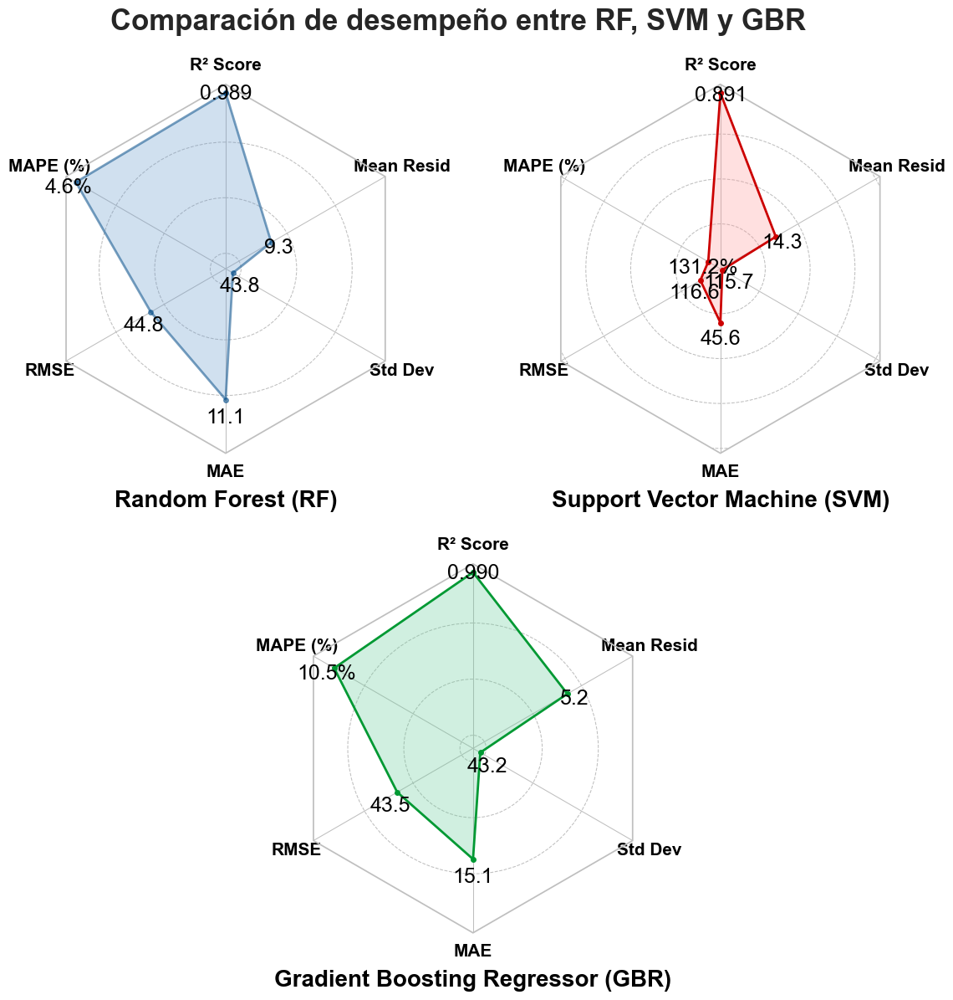

In [19]:

# CV:3
# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='circle'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        RESOLUTION = 1
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines:
                self._close_line(line)
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0])
                y = np.append(y, y[0])
                line.set_data(x, y)
        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)
        def _gen_axes_patch(self):
            if frame == 'circle': return Circle((0.5, 0.5), 0.5)
            elif frame == 'polygon': return RegularPolygon((0.5, 0.5), num_vars, radius=0.5, edgecolor="k")
            else: raise ValueError("unknown value for 'frame': %s" % frame)
        def _gen_axes_spines(self):
            if frame == 'circle': return super()._gen_axes_spines()
            elif frame == 'polygon':
                spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
                spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
                return {'polar': spine}
            else: raise ValueError("unknown value for 'frame': %s" % frame)
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS REALES ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']
models_data = {
    'Random Forest (RF)': [0.9889, 4.59, 44.7568, 11.0893, 43.7764, 9.3165],
    'Support Vector Machine (SVM)': [0.8915, 131.24, 116.5877, 45.6039, 115.7080, 14.2944],
    'Gradient Boosting Regressor (GBR)': [0.9903, 10.48, 43.4941, 15.1317, 43.1863, 5.1651]
}

# --- 3. DEFINICIÓN DE LÍMITES UNIFICADOS (ESCALA FIJA) ---
limits = {
    'R² Score': 0.5,      
    'MAPE (%)': 140.0,    
    'RMSE': 130.0,        
    'MAE': 60.0,          
    'Std Dev': 70.0,     
    'Mean Resid': 20.0    
}

def normalize_data(values):
    norm_list = []
    # R2: Mayor es mejor
    val_r2 = values[0]
    norm_r2 = (val_r2 - limits['R² Score']) / (1.0 - limits['R² Score'])
    norm_list.append(max(0.01, norm_r2))
    
    # Errores: Menor es mejor (Inversión)
    for i in range(1, len(values)):
        metric = metrics[i]
        val = values[i]
        limit = limits[metric]
        norm = 1 - (val / limit)
        norm_list.append(max(0.01, norm))
    return norm_list

# --- 4. GRAFICACIÓN ---
theta = radar_factory(6, frame='polygon')

bg_color = 'white'
text_color = "#000000"
line_colors = ["#004a8789", '#cc0000', '#009933'] # Azul, Rojo, Verde
fill_colors = ['#6699cc', '#ff9999', '#66cc99']

# --- MODIFICACIÓN DE LA DISTRIBUCIÓN ---
# Usamos GridSpec para crear una cuadrícula de 2 filas x 4 columnas.
# Fila 1: Ocupa espacios [0:2] y [2:4].
# Fila 2: Ocupa el espacio central [1:3].
fig = plt.figure(figsize=(14, 13)) 
fig.patch.set_facecolor(bg_color)
gs = fig.add_gridspec(2, 4, wspace=0.5, hspace=0.3)

ax1 = fig.add_subplot(gs[0, 0:2], projection='radar')
ax2 = fig.add_subplot(gs[0, 2:4], projection='radar')
ax3 = fig.add_subplot(gs[1, 1:3], projection='radar')

axes = [ax1, ax2, ax3]
# ----------------------------------------

model_names = list(models_data.keys())

for i, ax in enumerate(axes):
    name = model_names[i]
    data = models_data[name]
    norm_data = normalize_data(data)
    
    ax.set_facecolor(bg_color)
    
    # Rejilla
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax.yaxis.grid(True, color='#bfbfbf', linestyle='--', linewidth=0.75)
    ax.xaxis.grid(True, color='#bfbfbf', linestyle='-', linewidth=0.75)
    
    # Trazado
    ax.plot(theta, norm_data, color=line_colors[i], linewidth=2, marker='o', markersize=4)
    ax.fill(theta, norm_data, facecolor=fill_colors[i], alpha=0.3)
    
    # Etiquetas de Variables
    ax.set_varlabels(metrics)
    for label in ax.get_xticklabels():
        label.set_color(text_color)
        label.set_fontsize(15)
        label.set_fontweight('bold')
    
    # Valores Numéricos
    for angle, val, norm_val, metric_name in zip(theta, data, norm_data, metrics):
        if metric_name == 'R² Score': txt = f"{val:.3f}"
        elif metric_name == 'MAPE (%)': txt = f"{val:.1f}%"
        else: txt = f"{val:.1f}"
        
        ax.text(angle, norm_val + 0.03, txt, color=text_color, ha='center', va='top', fontsize=18, fontweight='normal')
        
    ax.spines['polar'].set_color('#bfbfbf')
    ax.set_yticklabels([])

    # Título del modelo ABAJO
    ax.text(0.5, -0.10, name, transform=ax.transAxes, 
            ha='center', va='top', fontsize=20, fontweight='bold', color=text_color)

# Título Principal ARRIBA
plt.suptitle("Comparación de desempeño entre RF, SVM y GBR", fontsize=25, fontweight='bold', y=0.95)

plt.subplots_adjust(bottom=0.1) # Espacio para títulos inferiores
plt.savefig('comparacion_modelos_triangular.png', dpi=600, bbox_inches='tight')
plt.show()

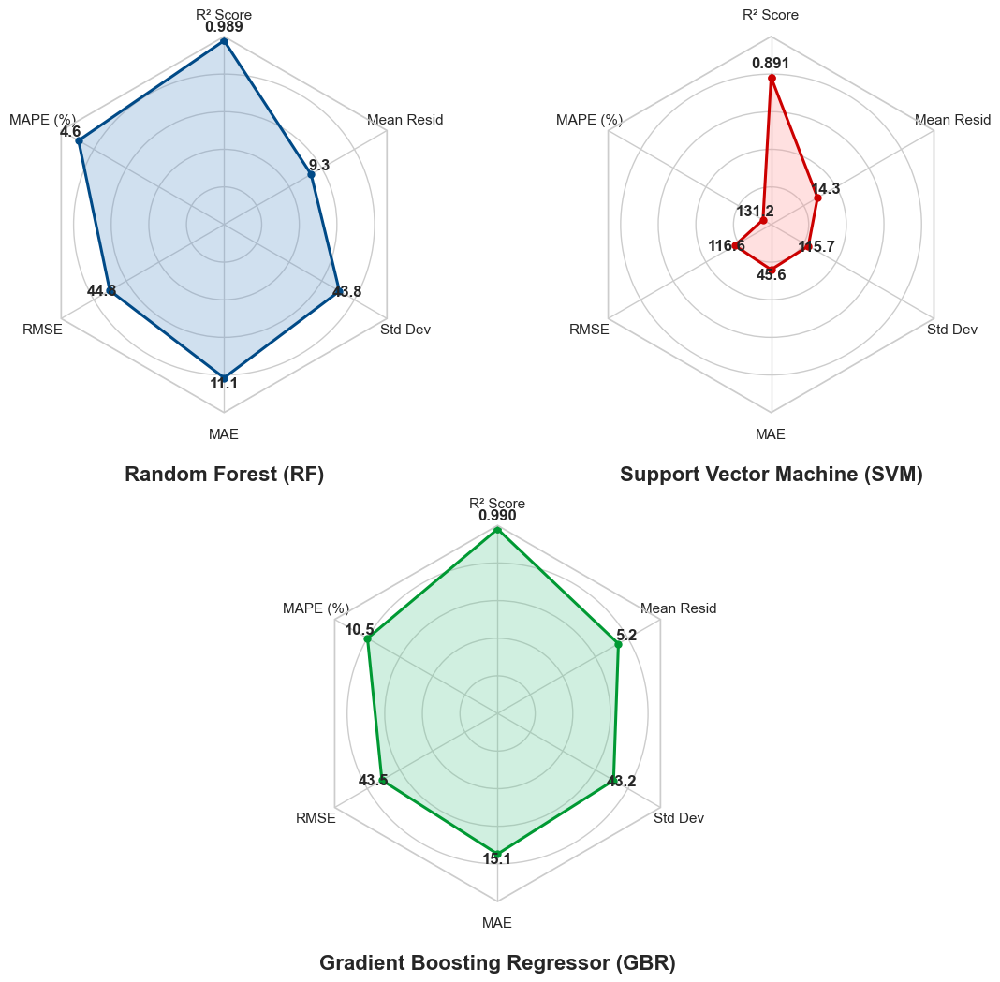

In [159]:
#k =3

# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='polygon'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines: self._close_line(line)
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0]); y = np.append(y, y[0])
                line.set_data(x, y)
        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)
        def _gen_axes_patch(self):
            return RegularPolygon((0.5, 0.5), num_vars, radius=0.5)
        def _gen_axes_spines(self):
            spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
            spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
            return {'polar': spine}
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS Y LÓGICA DE NORMALIZACIÓN INVERSA ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']
models_data = {
    'Random Forest (RF)': [0.9889, 4.59, 44.7568, 11.0893, 43.7764, 9.3165],
    'Support Vector Machine (SVM)': [0.8915, 131.24, 116.5877, 45.6039, 115.7080, 14.2944],
    'Gradient Boosting Regressor (GBR)': [0.9903, 10.48, 43.4941, 15.1317, 43.1863, 5.1651]
}

# Definimos límites [PEOR, MEJOR] para cada métrica
limits = {
    'R² Score': [0.5, 1.0],      
    'MAPE (%)': [60.0, -2],    
    'RMSE': [150.0, 0.0],       
    'MAE': [60.0, 0.0],         
    'Std Dev': [150.0, 0.0],    
    'Mean Resid': [20.0, 0.0]   
}

def normalize_data(values):
    norm_list = []
    for i, val in enumerate(values):
        low, high = limits[metrics[i]]
        # Normalización: (valor - peor) / (mejor - peor)
        # Si error es 0 (mejor), norm = (0 - 60) / (0 - 60) = 1.0 (exterior)
        norm = (val - low) / (high - low)
        norm_list.append(np.clip(norm, 0.05, 1.0))
    return norm_list

# --- 3. CREACIÓN DE LA FIGURA (2 Arriba, 1 Abajo Centrado) ---
theta = radar_factory(len(metrics))
fig = plt.figure(figsize=(14, 12), facecolor='white')
gs = fig.add_gridspec(2, 4, hspace=0.3, wspace=0.4)

# Definir ejes en la cuadrícula
ax1 = fig.add_subplot(gs[0, 0:2], projection='radar') # Top Izq
ax2 = fig.add_subplot(gs[0, 2:4], projection='radar') # Top Der
ax3 = fig.add_subplot(gs[1, 1:3], projection='radar') # Bottom Centro

axes = [ax1, ax2, ax3]
line_colors = ["#004a87", '#cc0000', '#009933']
fill_colors = ['#6699cc', '#ff9999', '#66cc99']
model_names = list(models_data.keys())

for i, ax in enumerate(axes):
    name = model_names[i]
    data = models_data[name]
    norm_data = normalize_data(data)
    
    # Estética del eje
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax.plot(theta, norm_data, color=line_colors[i], lw=2.2, marker='o', ms=5)
    ax.fill(theta, norm_data, facecolor=fill_colors[i], alpha=0.3)
    ax.set_varlabels(metrics)
    
    # Etiquetas de valores reales sobre los puntos
    for angle, val, norm_val, m_name in zip(theta, data, norm_data, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax.set_ylim(0, 1)
    ax.set_title(name, y=-0.2, fontsize=16, weight='bold')

#plt.suptitle("Evaluación de Modelos de Regresión", 
#             fontsize=20, fontweight='bold', y=0.98)
plt.savefig('radar_final_tesis.png', dpi=600, bbox_inches='tight')
plt.show()

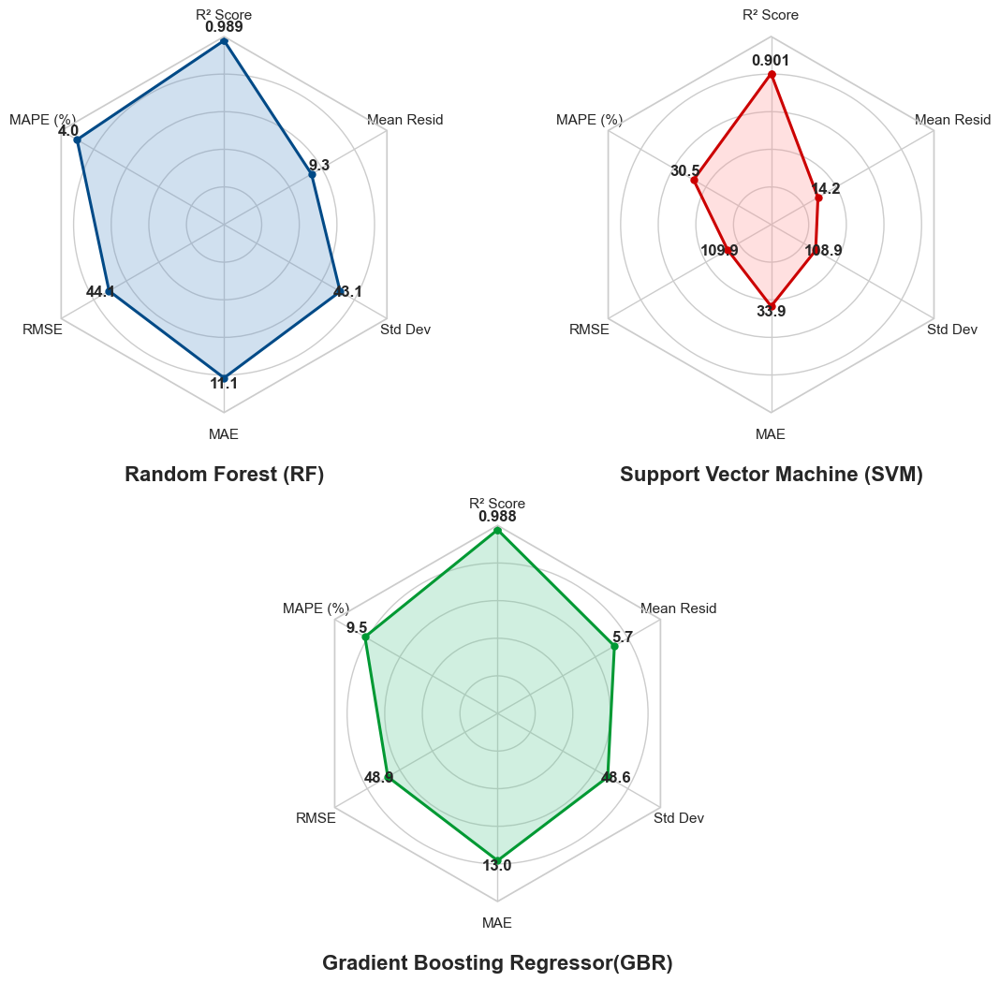

In [ ]:
# K=5

# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='polygon'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines: self._close_line(line)
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0]); y = np.append(y, y[0])
                line.set_data(x, y)
        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)
        def _gen_axes_patch(self):
            return RegularPolygon((0.5, 0.5), num_vars, radius=0.5)
        def _gen_axes_spines(self):
            spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
            spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
            return {'polar': spine}
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS Y LÓGICA DE NORMALIZACIÓN INVERSA ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']
models_data = {
    'Random Forest (RF)': [0.9892, 4.04, 44.0893, 11.0689, 43.1054, 9.2626],
    'Support Vector Machine (SVM)': [0.9013, 30.48, 109.8737, 33.9187, 108.9465, 14.2437],
    'Gradient Boosting Regressor(GBR)': [0.9884, 9.51, 48.9083, 13.0453, 48.5804, 5.6541]
}

# Definimos límites [PEOR, MEJOR] para cada métrica
limits = {
    'R² Score': [0.5, 1.0],      
    'MAPE (%)': [60.0, -2],    
    'RMSE': [150.0, 0.0],       
    'MAE': [60.0, 0.0],         
    'Std Dev': [150.0, 0.0],    
    'Mean Resid': [20.0, 0.0]   
}

def normalize_data(values):
    norm_list = []
    for i, val in enumerate(values):
        low, high = limits[metrics[i]]
        # Normalización: (valor - peor) / (mejor - peor)
        # Si error es 0 (mejor), norm = (0 - 60) / (0 - 60) = 1.0 (exterior)
        norm = (val - low) / (high - low)
        norm_list.append(np.clip(norm, 0.05, 1.0))
    return norm_list

# --- 3. CREACIÓN DE LA FIGURA (2 Arriba, 1 Abajo Centrado) ---
theta = radar_factory(len(metrics))
fig = plt.figure(figsize=(14, 12), facecolor='white')
gs = fig.add_gridspec(2, 4, hspace=0.3, wspace=0.4)

# Definir ejes en la cuadrícula
ax1 = fig.add_subplot(gs[0, 0:2], projection='radar') # Top Izq
ax2 = fig.add_subplot(gs[0, 2:4], projection='radar') # Top Der
ax3 = fig.add_subplot(gs[1, 1:3], projection='radar') # Bottom Centro

axes = [ax1, ax2, ax3]
line_colors = ["#004a87", '#cc0000', '#009933']
fill_colors = ['#6699cc', '#ff9999', '#66cc99']
model_names = list(models_data.keys())

for i, ax in enumerate(axes):
    name = model_names[i]
    data = models_data[name]
    norm_data = normalize_data(data)
    
    # Estética del eje
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax.plot(theta, norm_data, color=line_colors[i], lw=2.2, marker='o', ms=5)
    ax.fill(theta, norm_data, facecolor=fill_colors[i], alpha=0.3)
    ax.set_varlabels(metrics)
    
    # Etiquetas de valores reales sobre los puntos
    for angle, val, norm_val, m_name in zip(theta, data, norm_data, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax.set_ylim(0, 1)
    ax.set_title(name, y=-0.2, fontsize=16, weight='bold')

#plt.suptitle("Evaluación de Modelos de Regresión", 
#             fontsize=20, fontweight='bold', y=0.98)
plt.savefig('radar_final_tesis.png', dpi=600, bbox_inches='tight')
plt.show()

Mejores parámetros del primer target: {'regressor__C': 150, 'regressor__epsilon': 0.1, 'regressor__kernel': 'rbf'}
Score SVM (R² global): 0.9480
MSE global: 7497.6819
RMSE global: 86.5892
MAE global: 40.5720
MAPE global: 142.52%
Residuo medio global: -6.5630
Desviación estándar de residuos global: 86.3401


############

Mejores parámetros del primer target: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500}
Score GBR (R² global): 0.9884
MSE global: 2392.0227
RMSE global: 48.9083
MAE global: 13.0453
MAPE global: 9.51%
Residuo medio global: 5.6541
Desviación estándar de residuos global: 48.5804

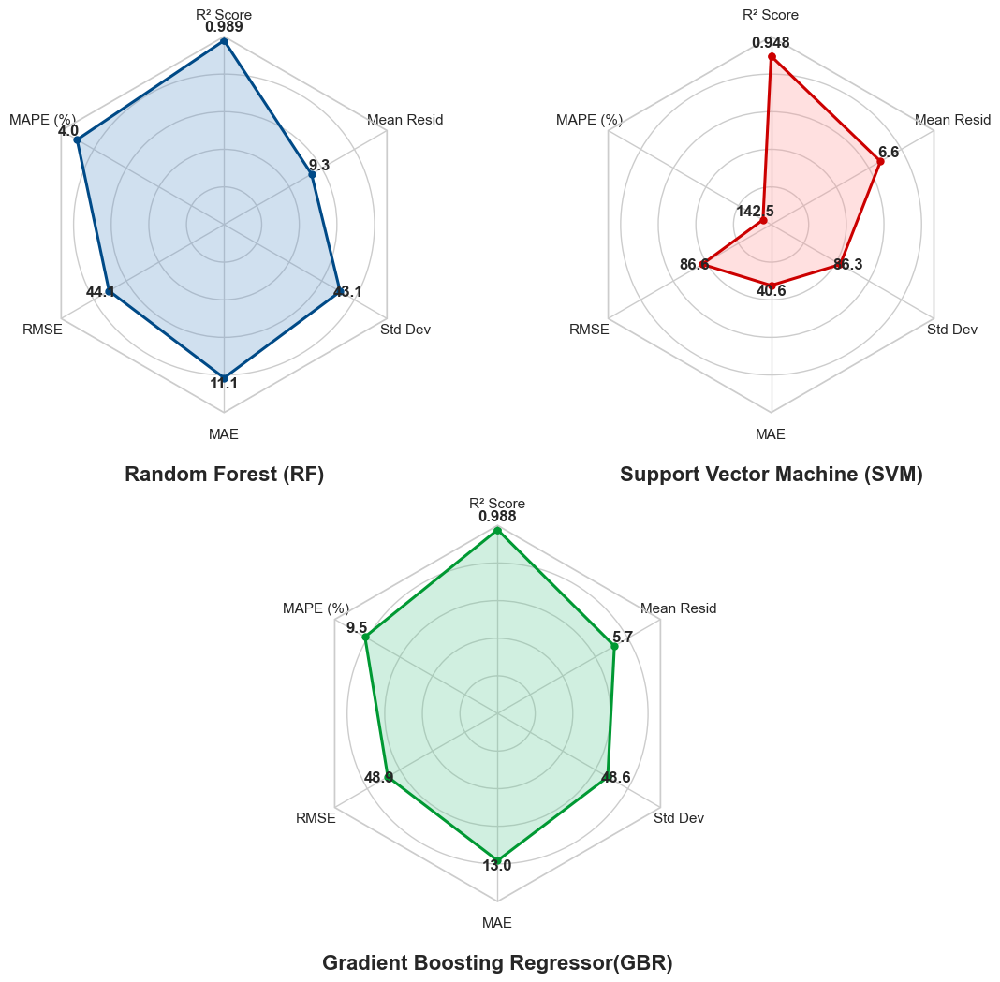

In [11]:
# K=5

# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='polygon'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines: self._close_line(line)
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0]); y = np.append(y, y[0])
                line.set_data(x, y)
        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)
        def _gen_axes_patch(self):
            return RegularPolygon((0.5, 0.5), num_vars, radius=0.5)
        def _gen_axes_spines(self):
            spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
            spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
            return {'polar': spine}
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS Y LÓGICA DE NORMALIZACIÓN INVERSA ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']
models_data = {
    'Random Forest (RF)': [0.9892, 4.04, 44.0893, 11.0689, 43.1054, 9.2626],
    'Support Vector Machine (SVM)': [0.9480, 142.52, 86.5892, 40.5720, 86.3401, 6.5630],
    'Gradient Boosting Regressor(GBR)': [0.9884, 9.51, 48.9083, 13.0453, 48.5804, 5.6541]
}

# Definimos límites [PEOR, MEJOR] para cada métrica
limits = {
    'R² Score': [0.5, 1.0],      
    'MAPE (%)': [60.0, -2],    
    'RMSE': [150.0, 0.0],       
    'MAE': [60.0, 0.0],         
    'Std Dev': [150.0, 0.0],    
    'Mean Resid': [20.0, 0.0]   
}

def normalize_data(values):
    norm_list = []
    for i, val in enumerate(values):
        low, high = limits[metrics[i]]
        # Normalización: (valor - peor) / (mejor - peor)
        # Si error es 0 (mejor), norm = (0 - 60) / (0 - 60) = 1.0 (exterior)
        norm = (val - low) / (high - low)
        norm_list.append(np.clip(norm, 0.05, 1.0))
    return norm_list

# --- 3. CREACIÓN DE LA FIGURA (2 Arriba, 1 Abajo Centrado) ---
theta = radar_factory(len(metrics))
fig = plt.figure(figsize=(14, 12), facecolor='white')
gs = fig.add_gridspec(2, 4, hspace=0.3, wspace=0.4)

# Definir ejes en la cuadrícula
ax1 = fig.add_subplot(gs[0, 0:2], projection='radar') # Top Izq
ax2 = fig.add_subplot(gs[0, 2:4], projection='radar') # Top Der
ax3 = fig.add_subplot(gs[1, 1:3], projection='radar') # Bottom Centro

axes = [ax1, ax2, ax3]
line_colors = ["#004a87", '#cc0000', '#009933']
fill_colors = ['#6699cc', '#ff9999', '#66cc99']
model_names = list(models_data.keys())

for i, ax in enumerate(axes):
    name = model_names[i]
    data = models_data[name]
    norm_data = normalize_data(data)
    
    # Estética del eje
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax.plot(theta, norm_data, color=line_colors[i], lw=2.2, marker='o', ms=5)
    ax.fill(theta, norm_data, facecolor=fill_colors[i], alpha=0.3)
    ax.set_varlabels(metrics)
    
    # Etiquetas de valores reales sobre los puntos
    for angle, val, norm_val, m_name in zip(theta, data, norm_data, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax.set_ylim(0, 1)
    ax.set_title(name, y=-0.2, fontsize=16, weight='bold')

#plt.suptitle("Evaluación de Modelos de Regresión", 
#             fontsize=20, fontweight='bold', y=0.98)
plt.savefig('radar_final_tesis.png', dpi=600, bbox_inches='tight')
plt.show()

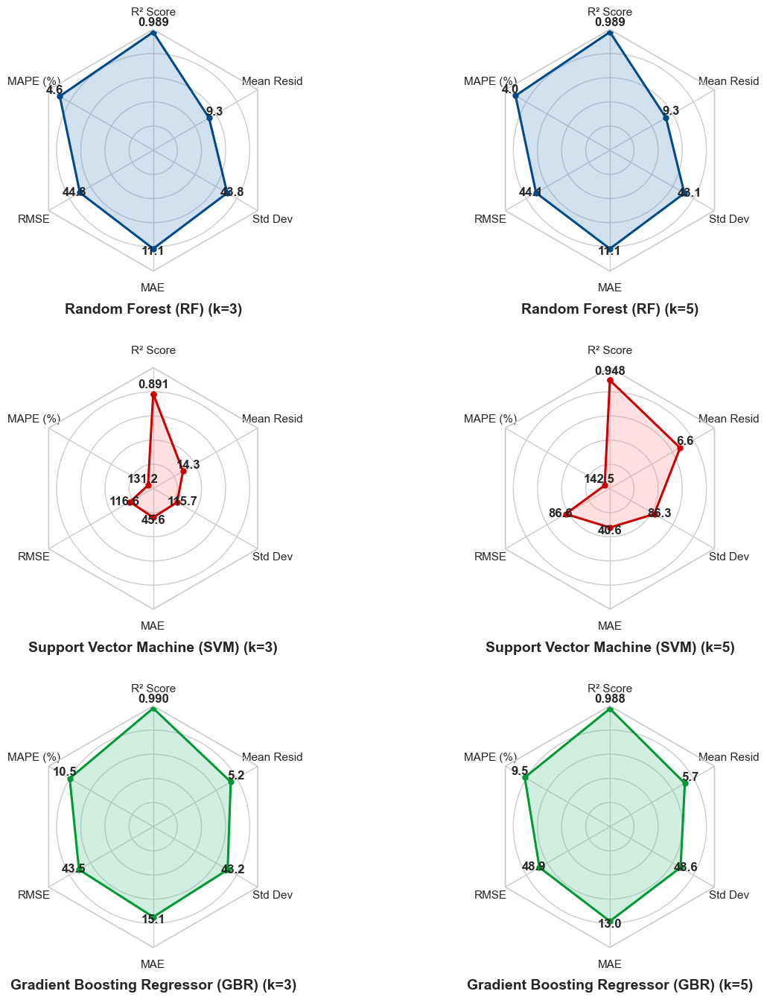

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D
from matplotlib.projections.polar import PolarAxes
from matplotlib.projections import register_projection
from matplotlib.patches import RegularPolygon

# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='polygon'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines: self._close_line(line)
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0]); y = np.append(y, y[0])
                line.set_data(x, y)
        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)
        def _gen_axes_patch(self):
            return RegularPolygon((0.5, 0.5), num_vars, radius=0.5)
        def _gen_axes_spines(self):
            spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
            spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
            return {'polar': spine}
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS Y LÓGICA DE NORMALIZACIÓN INVERSA ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']

# Datos de evaluación para k=3
models_data_k3 = {
    'Random Forest (RF)': [0.9889, 4.59, 44.7568, 11.0893, 43.7764, 9.3165],
    'Support Vector Machine (SVM)': [0.8915, 131.24, 116.5877, 45.6039, 115.7080, 14.2944],
    'Gradient Boosting Regressor (GBR)': [0.9903, 10.48, 43.4941, 15.1317, 43.1863, 5.1651]
}

# Datos de evaluación para k=5 (Nota: Se ajustó el nombre del GBR para que coincida exactamente con k=3)
models_data_k5 = {
    'Random Forest (RF)': [0.9892, 4.04, 44.0893, 11.0689, 43.1054, 9.2626],
    'Support Vector Machine (SVM)': [0.9480, 142.52, 86.5892, 40.5720, 86.3401, 6.5630],
    'Gradient Boosting Regressor (GBR)': [0.9884, 9.51, 48.9083, 13.0453, 48.5804, 5.6541]
}

# Definimos límites [PEOR, MEJOR] para cada métrica
limits = {
    'R² Score': [0.5, 1.0],      
    'MAPE (%)': [60.0, -2],    
    'RMSE': [150.0, 0.0],       
    'MAE': [60.0, 0.0],         
    'Std Dev': [150.0, 0.0],    
    'Mean Resid': [20.0, 0.0]   
}

def normalize_data(values):
    norm_list = []
    for i, val in enumerate(values):
        low, high = limits[metrics[i]]
        norm = (val - low) / (high - low)
        norm_list.append(np.clip(norm, 0.05, 1.0))
    return norm_list

# --- 3. CREACIÓN DE LA FIGURA (3 Filas, 2 Columnas) ---
theta = radar_factory(len(metrics))
# Se amplía el tamaño del lienzo para acomodar las 3 filas con claridad
fig = plt.figure(figsize=(14, 16), facecolor='white')
gs = fig.add_gridspec(3, 2, hspace=0.4, wspace=0.3)

line_colors = ["#004a87", '#cc0000', '#009933']
fill_colors = ['#6699cc', '#ff9999', '#66cc99']
model_names = list(models_data_k3.keys())

# Generación dinámica de la matriz de gráficos
for row, name in enumerate(model_names):
    
    # --- COLUMNA 1: k=3 ---
    ax_k3 = fig.add_subplot(gs[row, 0], projection='radar')
    data_k3 = models_data_k3[name]
    norm_data_k3 = normalize_data(data_k3)
    
    ax_k3.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax_k3.plot(theta, norm_data_k3, color=line_colors[row], lw=2.2, marker='o', ms=5)
    ax_k3.fill(theta, norm_data_k3, facecolor=fill_colors[row], alpha=0.3)
    ax_k3.set_varlabels(metrics)
    
    for angle, val, norm_val, m_name in zip(theta, data_k3, norm_data_k3, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax_k3.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax_k3.set_ylim(0, 1)
    ax_k3.set_title(f"{name} (k=3)", y=-0.2, fontsize=14, weight='bold')

    # --- COLUMNA 2: k=5 ---
    ax_k5 = fig.add_subplot(gs[row, 1], projection='radar')
    data_k5 = models_data_k5[name]
    norm_data_k5 = normalize_data(data_k5)
    
    ax_k5.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax_k5.plot(theta, norm_data_k5, color=line_colors[row], lw=2.2, marker='o', ms=5)
    ax_k5.fill(theta, norm_data_k5, facecolor=fill_colors[row], alpha=0.3)
    ax_k5.set_varlabels(metrics)
    
    for angle, val, norm_val, m_name in zip(theta, data_k5, norm_data_k5, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax_k5.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax_k5.set_ylim(0, 1)
    ax_k5.set_title(f"{name} (k=5)", y=-0.2, fontsize=14, weight='bold')

# Título principal de la figura (Opcional, descomentar si se requiere en el documento)
# plt.suptitle("Comparativa de Modelos de Regresión: k-Fold Cross-Validation (k=3 vs k=5)", 
#              fontsize=20, fontweight='bold', y=0.92)

# Guardar y mostrar
plt.savefig('radar_kfold_comparativa_tesis.png', dpi=600, bbox_inches='tight')
plt.show()

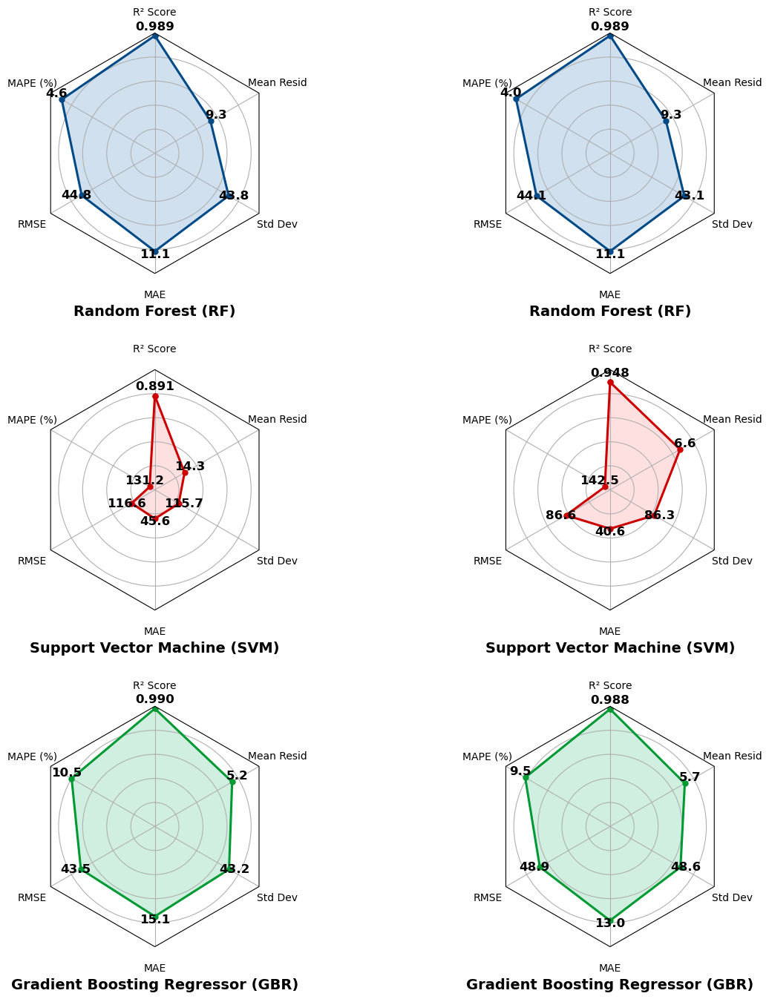

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D
from matplotlib.projections.polar import PolarAxes
from matplotlib.projections import register_projection
from matplotlib.patches import RegularPolygon

# --- 1. CONFIGURACIÓN DEL RADAR ---
def radar_factory(num_vars, frame='polygon'):
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)
    class RadarAxes(PolarAxes):
        name = 'radar'
        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            self.set_theta_zero_location('N')
            
        def fill(self, *args, closed=True, **kwargs):
            return super().fill(closed=closed, *args, **kwargs)
            
        def plot(self, *args, **kwargs):
            lines = super().plot(*args, **kwargs)
            for line in lines: self._close_line(line)
            
        def _close_line(self, line):
            x, y = line.get_data()
            if x[0] != x[-1]:
                x = np.append(x, x[0]); y = np.append(y, y[0])
                line.set_data(x, y)
                
        def set_varlabels(self, labels, pad=10):
            """
            Configura las etiquetas de las variables.
            El parámetro 'pad' controla la distancia radial entre el polígono y la etiqueta.
            """
            self.set_thetagrids(np.degrees(theta), labels)
            self.tick_params(axis='x', pad=pad) # Aleja los títulos del borde
            
        def _gen_axes_patch(self):
            return RegularPolygon((0.5, 0.5), num_vars, radius=0.5)
            
        def _gen_axes_spines(self):
            spine = Spine(axes=self, spine_type='circle', path=Path.unit_regular_polygon(num_vars))
            spine.set_transform(Affine2D().scale(.5).translate(.5, .5) + self.transAxes)
            return {'polar': spine}
            
    register_projection(RadarAxes)
    return theta

# --- 2. DATOS Y LÓGICA DE NORMALIZACIÓN INVERSA ---
metrics = ['R² Score', 'MAPE (%)', 'RMSE', 'MAE', 'Std Dev', 'Mean Resid']

# Datos de evaluación para k=3
models_data_k3 = {
    'Random Forest (RF)': [0.9889, 4.59, 44.7568, 11.0893, 43.7764, 9.3165],
    'Support Vector Machine (SVM)': [0.8915, 131.24, 116.5877, 45.6039, 115.7080, 14.2944],
    'Gradient Boosting Regressor (GBR)': [0.9903, 10.48, 43.4941, 15.1317, 43.1863, 5.1651]
}

# Datos de evaluación para k=5
models_data_k5 = {
    'Random Forest (RF)': [0.9892, 4.04, 44.0893, 11.0689, 43.1054, 9.2626],
    'Support Vector Machine (SVM)': [0.9480, 142.52, 86.5892, 40.5720, 86.3401, 6.5630],
    'Gradient Boosting Regressor (GBR)': [0.9884, 9.51, 48.9083, 13.0453, 48.5804, 5.6541]
}

# Límites [PEOR, MEJOR] para normalización
limits = {
    'R² Score': [0.5, 1.0],      
    'MAPE (%)': [60.0, -2],    
    'RMSE': [150.0, 0.0],       
    'MAE': [60.0, 0.0],         
    'Std Dev': [150.0, 0.0],    
    'Mean Resid': [20.0, 0.0]   
}

def normalize_data(values):
    norm_list = []
    for i, val in enumerate(values):
        low, high = limits[metrics[i]]
        norm = (val - low) / (high - low)
        norm_list.append(np.clip(norm, 0.05, 1.0))
    return norm_list

# --- 3. CREACIÓN DE LA FIGURA (3 Filas, 2 Columnas) ---
theta = radar_factory(len(metrics))
fig = plt.figure(figsize=(14, 16), facecolor='white')
gs = fig.add_gridspec(3, 2, hspace=0.4, wspace=0.3)

line_colors = ["#004a87", '#cc0000', '#009933']
fill_colors = ['#6699cc', '#ff9999', '#66cc99']
model_names = list(models_data_k3.keys())

for row, name in enumerate(model_names):
    
    # --- COLUMNA 1: k=3 ---
    ax_k3 = fig.add_subplot(gs[row, 0], projection='radar')
    data_k3 = models_data_k3[name]
    norm_data_k3 = normalize_data(data_k3)
    
    ax_k3.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax_k3.plot(theta, norm_data_k3, color=line_colors[row], lw=2.2, marker='o', ms=5)
    ax_k3.fill(theta, norm_data_k3, facecolor=fill_colors[row], alpha=0.3)
    # Se aplica un pad paramétrico; puedes aumentarlo si las etiquetas siguen muy cerca
    ax_k3.set_varlabels(metrics, pad=10) 
    
    for angle, val, norm_val, m_name in zip(theta, data_k3, norm_data_k3, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax_k3.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax_k3.set_ylim(0, 1)
    ax_k3.set_title(f"{name}", y=-0.2, fontsize=14, weight='bold')

    # --- COLUMNA 2: k=5 ---
    ax_k5 = fig.add_subplot(gs[row, 1], projection='radar')
    data_k5 = models_data_k5[name]
    norm_data_k5 = normalize_data(data_k5)
    
    ax_k5.set_rgrids([0.2, 0.4, 0.6, 0.8], labels=[], angle=0)
    ax_k5.plot(theta, norm_data_k5, color=line_colors[row], lw=2.2, marker='o', ms=5)
    ax_k5.fill(theta, norm_data_k5, facecolor=fill_colors[row], alpha=0.3)
    ax_k5.set_varlabels(metrics, pad=10)
    
    for angle, val, norm_val, m_name in zip(theta, data_k5, norm_data_k5, metrics):
        txt = f"{val:.3f}" if "R²" in m_name else f"{val:.1f}"
        ax_k5.text(angle, norm_val + 0.05, txt, size=12, weight='bold', ha='center')

    ax_k5.set_ylim(0, 1)
    ax_k5.set_title(f"{name}", y=-0.2, fontsize=14, weight='bold')

plt.savefig('radar_kfold_comparativa_tesis.png', dpi=600, bbox_inches='tight')
plt.show()

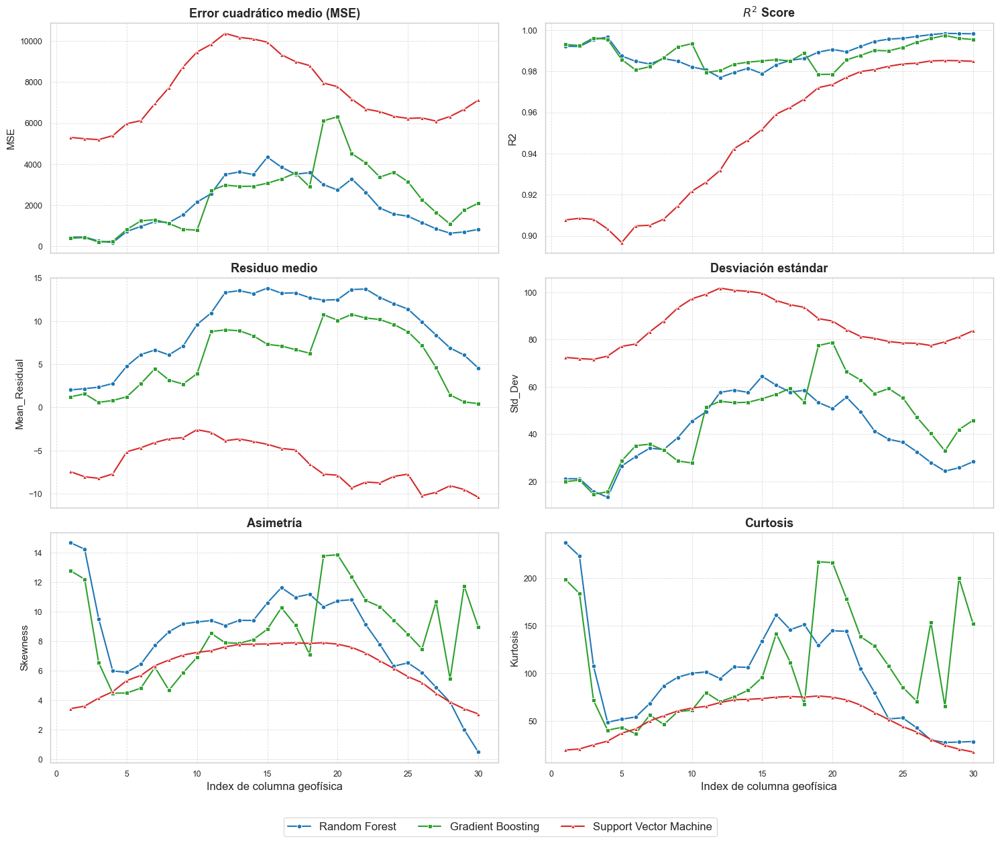

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. DATOS DE ENTRADA (Mantenidos inalterados por rigor científico)
raw_rf = """
Columna: 1, MSE: 449.3789, R²: 0.9922, Residuo Media: 2.0281, Std: 21.1013, Asimetría: 14.6709, Curtosis: 237.3178
Columna: 2, MSE: 451.7683, R²: 0.9921, Residuo Media: 2.1709, Std: 21.1437, Asimetría: 14.2406, Curtosis: 223.4228
Columna: 3, MSE: 255.7646, R²: 0.9955, Residuo Media: 2.3439, Std: 15.8200, Asimetría: 9.5241, Curtosis: 107.4582
Columna: 4, MSE: 184.1613, R²: 0.9967, Residuo Media: 2.7779, Std: 13.2833, Asimetría: 5.9781, Curtosis: 48.5586
Columna: 5, MSE: 723.6514, R²: 0.9875, Residuo Media: 4.7892, Std: 26.4710, Asimetría: 5.8868, Curtosis: 51.6807
Columna: 6, MSE: 968.7905, R²: 0.9849, Residuo Media: 6.1243, Std: 30.5169, Asimetría: 6.4381, Curtosis: 54.1212
Columna: 7, MSE: 1202.3735, R²: 0.9836, Residuo Media: 6.6501, Std: 34.0316, Asimetría: 7.7135, Curtosis: 68.2500
Columna: 8, MSE: 1159.9705, R²: 0.9862, Residuo Media: 6.0848, Std: 33.5104, Asimetría: 8.6403, Curtosis: 86.8977
Columna: 9, MSE: 1534.1931, R²: 0.9850, Residuo Media: 7.0963, Std: 38.5206, Asimetría: 9.1762, Curtosis: 95.9442
Columna: 10, MSE: 2157.5640, R²: 0.9822, Residuo Media: 9.6115, Std: 45.4443, Asimetría: 9.2997, Curtosis: 100.0925
Columna: 11, MSE: 2561.9288, R²: 0.9807, Residuo Media: 10.9458, Std: 49.4178, Asimetría: 9.3978, Curtosis: 101.4424
Columna: 12, MSE: 3499.5387, R²: 0.9770, Residuo Media: 13.3127, Std: 57.6395, Asimetría: 9.0650, Curtosis: 94.5313
Columna: 13, MSE: 3623.6083, R²: 0.9795, Residuo Media: 13.5188, Std: 58.6588, Asimetría: 9.4085, Curtosis: 106.7399
Columna: 14, MSE: 3496.7671, R²: 0.9815, Residuo Media: 13.1906, Std: 57.6435, Asimetría: 9.4054, Curtosis: 106.2402
Columna: 15, MSE: 4345.8189, R²: 0.9789, Residuo Media: 13.8201, Std: 64.4579, Asimetría: 10.5982, Curtosis: 134.0419
Columna: 16, MSE: 3855.2248, R²: 0.9832, Residuo Media: 13.2270, Std: 60.6652, Asimetría: 11.6313, Curtosis: 161.5394
Columna: 17, MSE: 3514.3269, R²: 0.9854, Residuo Media: 13.2683, Std: 57.7778, Asimetría: 10.9768, Curtosis: 145.9213
Columna: 18, MSE: 3589.4009, R²: 0.9863, Residuo Media: 12.7074, Std: 58.5485, Asimetría: 11.1859, Curtosis: 151.1576
Columna: 19, MSE: 3003.6186, R²: 0.9894, Residuo Media: 12.4223, Std: 53.3789, Asimetría: 10.3359, Curtosis: 129.3795
Columna: 20, MSE: 2743.7693, R²: 0.9907, Residuo Media: 12.4880, Std: 50.8706, Asimetría: 10.7330, Curtosis: 144.8018
Columna: 21, MSE: 3281.9315, R²: 0.9895, Residuo Media: 13.6569, Std: 55.6365, Asimetría: 10.8109, Curtosis: 144.1573
Columna: 22, MSE: 2634.1303, R²: 0.9921, Residuo Media: 13.7054, Std: 49.4600, Asimetría: 9.1230, Curtosis: 104.8610
Columna: 23, MSE: 1864.8633, R²: 0.9946, Residuo Media: 12.7347, Std: 41.2637, Asimetría: 7.7806, Curtosis: 79.6351
Columna: 24, MSE: 1572.4660, R²: 0.9957, Residuo Media: 12.0078, Std: 37.7926, Asimetría: 6.3038, Curtosis: 52.0747
Columna: 25, MSE: 1467.5920, R²: 0.9961, Residuo Media: 11.3971, Std: 36.5745, Asimetría: 6.5244, Curtosis: 53.1132
Columna: 26, MSE: 1157.2403, R²: 0.9970, Residuo Media: 9.8961, Std: 32.5470, Asimetría: 5.8833, Curtosis: 42.6215
Columna: 27, MSE: 852.9950, R²: 0.9979, Residuo Media: 8.3870, Std: 27.9759, Asimetría: 4.8718, Curtosis: 29.8495
Columna: 28, MSE: 640.3746, R²: 0.9985, Residuo Media: 6.8832, Std: 24.3515, Asimetría: 3.8627, Curtosis: 27.2376
Columna: 29, MSE: 700.1945, R²: 0.9984, Residuo Media: 6.0625, Std: 25.7573, Asimetría: 1.9985, Curtosis: 27.6856
Columna: 30, MSE: 822.6785, R²: 0.9983, Residuo Media: 4.5694, Std: 28.3161, Asimetría: 0.4818, Curtosis: 28.2685
"""

raw_gbr = """
Columna: 1, MSE: 396.4643, R²: 0.9931, Residuo Media: 1.2300, Std: 19.8734, Asimetría: 12.7695, Curtosis: 198.7380
Columna: 2, MSE: 426.3861, R²: 0.9926, Residuo Media: 1.5711, Std: 20.5893, Asimetría: 12.2025, Curtosis: 183.9603
Columna: 3, MSE: 210.7947, R²: 0.9963, Residuo Media: 0.5862, Std: 14.5069, Asimetría: 6.5341, Curtosis: 71.5436
Columna: 4, MSE: 244.2559, R²: 0.9956, Residuo Media: 0.8002, Std: 15.6082, Asimetría: 4.4674, Curtosis: 40.1631
Columna: 5, MSE: 821.1386, R²: 0.9858, Residuo Media: 1.2330, Std: 28.6290, Asimetría: 4.4820, Curtosis: 43.1516
Columna: 6, MSE: 1239.9517, R²: 0.9807, Residuo Media: 2.7462, Std: 35.1057, Asimetría: 4.8158, Curtosis: 36.3486
Columna: 7, MSE: 1296.8174, R²: 0.9823, Residuo Media: 4.4782, Std: 35.7318, Asimetría: 6.2297, Curtosis: 56.1501
Columna: 8, MSE: 1110.3594, R²: 0.9868, Residuo Media: 3.1771, Std: 33.1703, Asimetría: 4.6689, Curtosis: 46.1681
Columna: 9, MSE: 827.5601, R²: 0.9919, Residuo Media: 2.7031, Std: 28.6401, Asimetría: 5.8453, Curtosis: 59.6795
Columna: 10, MSE: 787.7813, R²: 0.9935, Residuo Media: 3.9160, Std: 27.7929, Asimetría: 6.9041, Curtosis: 61.1699
Columna: 11, MSE: 2722.3383, R²: 0.9795, Residuo Media: 8.7891, Std: 51.4304, Asimetría: 8.5314, Curtosis: 79.8390
Columna: 12, MSE: 2984.6336, R²: 0.9804, Residuo Media: 8.9811, Std: 53.8885, Asimetría: 7.8899, Curtosis: 70.2374
Columna: 13, MSE: 2919.6313, R²: 0.9835, Residuo Media: 8.8812, Std: 53.2987, Asimetría: 7.8534, Curtosis: 75.3181
Columna: 14, MSE: 2928.7910, R²: 0.9845, Residuo Media: 8.3072, Std: 53.4769, Asimetría: 8.1042, Curtosis: 82.1989
Columna: 15, MSE: 3076.4106, R²: 0.9851, Residuo Media: 7.3022, Std: 54.9826, Asimetría: 8.8074, Curtosis: 95.6479
Columna: 16, MSE: 3283.5684, R²: 0.9857, Residuo Media: 7.1158, Std: 56.8589, Asimetría: 10.2648, Curtosis: 141.8309
Columna: 17, MSE: 3568.5601, R²: 0.9851, Residuo Media: 6.6896, Std: 59.3617, Asimetría: 9.0888, Curtosis: 111.5702
Columna: 18, MSE: 2905.6785, R²: 0.9889, Residuo Media: 6.2805, Std: 53.5372, Asimetría: 7.1015, Curtosis: 67.2915
Columna: 19, MSE: 6118.8343, R²: 0.9785, Residuo Media: 10.7392, Std: 77.4823, Asimetría: 13.7887, Curtosis: 217.3084
Columna: 20, MSE: 6314.2807, R²: 0.9786, Residuo Media: 10.0950, Std: 78.8186, Asimetría: 13.8572, Curtosis: 216.5034
Columna: 21, MSE: 4518.9561, R²: 0.9856, Residuo Media: 10.7695, Std: 66.3549, Asimetría: 12.3518, Curtosis: 178.4985
Columna: 22, MSE: 4063.8293, R²: 0.9878, Residuo Media: 10.3534, Std: 62.9018, Asimetría: 10.7608, Curtosis: 138.5977
Columna: 23, MSE: 3374.3502, R²: 0.9902, Residuo Media: 10.1830, Std: 57.1897, Asimetría: 10.3410, Curtosis: 128.5735
Columna: 24, MSE: 3603.8433, R²: 0.9900, Residuo Media: 9.6035, Std: 59.2589, Asimetría: 9.4088, Curtosis: 107.6691
Columna: 25, MSE: 3147.3341, R²: 0.9917, Residuo Media: 8.7732, Std: 55.4109, Asimetría: 8.4773, Curtosis: 85.2933
Columna: 26, MSE: 2276.3013, R²: 0.9942, Residuo Media: 7.1854, Std: 47.1664, Asimetría: 7.4736, Curtosis: 70.5818
Columna: 27, MSE: 1647.6870, R²: 0.9960, Residuo Media: 4.6155, Std: 40.3285, Asimetría: 10.6790, Curtosis: 153.8392
Columna: 28, MSE: 1082.7931, R²: 0.9975, Residuo Media: 1.4447, Std: 32.8741, Asimetría: 5.4330, Curtosis: 65.4646
Columna: 29, MSE: 1758.2669, R²: 0.9961, Residuo Media: 0.6365, Std: 41.9269, Asimetría: 11.7469, Curtosis: 200.1167
Columna: 30, MSE: 2103.0844, R²: 0.9955, Residuo Media: 0.4367, Std: 45.8573, Asimetría: 8.9747, Curtosis: 152.2202
"""

raw_svm = """
Columna: 1, MSE: 5307.0933, R²: 0.9077, Residuo Media: -7.4451, Std: 72.4684, Asimetría: 3.4230, Curtosis: 19.2696
Columna: 2, MSE: 5242.2209, R²: 0.9085, Residuo Media: -8.0324, Std: 71.9562, Asimetría: 3.5891, Curtosis: 20.4092
Columna: 3, MSE: 5199.4623, R²: 0.9080, Residuo Media: -8.2116, Std: 71.6382, Asimetría: 4.1391, Curtosis: 24.8075
Columna: 4, MSE: 5391.9679, R²: 0.9033, Residuo Media: -7.7087, Std: 73.0243, Asimetría: 4.5706, Curtosis: 28.6695
Columna: 5, MSE: 5978.4564, R²: 0.8967, Residuo Media: -5.1294, Std: 77.1502, Asimetría: 5.3294, Curtosis: 37.0095
Columna: 6, MSE: 6122.4774, R²: 0.9048, Residuo Media: -4.6708, Std: 78.1067, Asimetría: 5.6708, Curtosis: 41.5054
Columna: 7, MSE: 6954.4116, R²: 0.9051, Residuo Media: -4.0645, Std: 83.2940, Asimetría: 6.3361, Curtosis: 49.9751
Columna: 8, MSE: 7727.7518, R²: 0.9081, Residuo Media: -3.6316, Std: 87.8326, Asimetría: 6.7179, Curtosis: 55.3719
Columna: 9, MSE: 8738.0422, R²: 0.9145, Residuo Media: -3.5034, Std: 93.4118, Asimetría: 7.0568, Curtosis: 60.4191
Columna: 10, MSE: 9469.1645, R²: 0.9217, Residuo Media: -2.5790, Std: 97.2755, Asimetría: 7.2394, Curtosis: 63.4623
Columna: 11, MSE: 9842.8913, R²: 0.9260, Residuo Media: -2.8936, Std: 99.1691, Asimetría: 7.3500, Curtosis: 65.2801
Columna: 12, MSE: 10376.3837, R²: 0.9318, Residuo Media: -3.8577, Std: 101.7915, Asimetría: 7.6119, Curtosis: 69.1698
Columna: 13, MSE: 10180.9100, R²: 0.9424, Residuo Media: -3.6531, Std: 100.8343, Asimetría: 7.7787, Curtosis: 72.1587
Columna: 14, MSE: 10103.8767, R²: 0.9466, Residuo Media: -3.9518, Std: 100.4403, Asimetría: 7.7929, Curtosis: 72.6458
Columna: 15, MSE: 9946.6564, R²: 0.9518, Residuo Media: -4.2717, Std: 99.6414, Asimetría: 7.8098, Curtosis: 73.4537
Columna: 16, MSE: 9335.4668, R²: 0.9592, Residuo Media: -4.7492, Std: 96.5034, Asimetría: 7.8634, Curtosis: 74.9635
Columna: 17, MSE: 9000.4442, R²: 0.9625, Residuo Media: -4.9171, Std: 94.7432, Asimetría: 7.8859, Curtosis: 75.6121
Columna: 18, MSE: 8808.8550, R²: 0.9665, Residuo Media: -6.5660, Std: 93.6255, Asimetría: 7.8452, Curtosis: 74.9585
Columna: 19, MSE: 7955.5056, R²: 0.9721, Residuo Media: -7.7323, Std: 88.8578, Asimetría: 7.8909, Curtosis: 76.2316
Columna: 20, MSE: 7777.3470, R²: 0.9736, Residuo Media: -7.8491, Std: 87.8393, Asimetría: 7.7935, Curtosis: 74.8870
Columna: 21, MSE: 7173.7332, R²: 0.9771, Residuo Media: -9.3170, Std: 84.1839, Asimetría: 7.5815, Curtosis: 72.0410
Columna: 22, MSE: 6689.4836, R²: 0.9799, Residuo Media: -8.6443, Std: 81.3312, Asimetría: 7.1896, Curtosis: 66.5527
Columna: 23, MSE: 6562.6343, R²: 0.9809, Residuo Media: -8.7411, Std: 80.5371, Asimetría: 6.6608, Curtosis: 58.6776
Columna: 24, MSE: 6332.8742, R²: 0.9825, Residuo Media: -7.9926, Std: 79.1770, Asimetría: 6.1432, Curtosis: 51.3736
Columna: 25, MSE: 6232.3459, R²: 0.9836, Residuo Media: -7.7266, Std: 78.5662, Asimetría: 5.5928, Curtosis: 43.9405
Columna: 26, MSE: 6256.3824, R²: 0.9840, Residuo Media: -10.2335, Std: 78.4325, Asimetría: 5.1842, Curtosis: 38.2201
Columna: 27, MSE: 6102.3006, R²: 0.9851, Residuo Media: -9.8320, Std: 77.4960, Asimetría: 4.4610, Curtosis: 30.3903
Columna: 28, MSE: 6328.1951, R²: 0.9853, Residuo Media: -9.0697, Std: 79.0312, Asimetría: 3.8583, Curtosis: 24.2990
Columna: 29, MSE: 6675.4500, R²: 0.9852, Residuo Media: -9.5106, Std: 81.1480, Asimetría: 3.4119, Curtosis: 20.2099
Columna: 30, MSE: 7117.6727, R²: 0.9849, Residuo Media: -10.4053, Std: 83.7222, Asimetría: 3.0638, Curtosis: 17.2687
"""

# 2. PROCESAMIENTO (PARSING CONSOLIDADO)
def parse_model_data(raw_text, model_name):
    """Convierte el bloque de texto crudo en un DataFrame de Pandas."""
    rows = []
    lines = raw_text.strip().split('\n')
    for line in lines:
        parts = line.split(',')
        row_data = {'Modelo': model_name} # Etiqueta identificadora del modelo
        for part in parts:
            key, val = part.split(':')
            row_data[key.strip()] = float(val.strip())
        rows.append(row_data)
    return pd.DataFrame(rows)

# Extraemos y concatenamos los DataFrames
df_rf = parse_model_data(raw_rf, 'Random Forest')
df_gbr = parse_model_data(raw_gbr, 'Gradient Boosting')
df_svm = parse_model_data(raw_svm, 'Support Vector Machine')

df_all = pd.concat([df_rf, df_gbr, df_svm], ignore_index=True)

# Renombramos columnas para estandarización en gráficos
df_all = df_all.rename(columns={
    'Columna': 'Index_Columna',
    'MSE': 'MSE',
    'R²': 'R2',
    'Residuo Media': 'Mean_Residual',
    'Std': 'Std_Dev',
    'Asimetría': 'Skewness',
    'Curtosis': 'Kurtosis'
})

# 3. GRAFICACIÓN CONSOLIDADA
sns.set_theme(style="whitegrid", context="paper") # Estilo apropiado para papers/tesis
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

# Mapeo de métricas y configuraciones visuales
metrics = ['MSE', 'R2', 'Mean_Residual', 'Std_Dev', 'Skewness', 'Kurtosis']
titles = [
    'Error cuadrático medio (MSE)', 
    '$R^2$ Score', 
    'Residuo medio', 
    'Desviación estándar', 
    'Asimetría', 
    'Curtosis'
]

# Definimos una paleta de colores distintiva para comparar los modelos
model_palette = {
    'Random Forest': '#1f77b4',  # Azul
    'Gradient Boosting': '#2ca02c', # Verde
    'Support Vector Machine': '#d62728'           # Rojo
}
model_markers = ['o', 's', '^']

# Generación de los subgráficos
for i, metric in enumerate(metrics):
    sns.lineplot(
        ax=axes[i], 
        data=df_all, 
        x='Index_Columna', 
        y=metric, 
        hue='Modelo', 
        style='Modelo',
        markers=model_markers,
        palette=model_palette,
        dashes=False, 
        linewidth=1.5
    )
    axes[i].set_title(titles[i], fontsize=13, fontweight='bold')
    axes[i].set_ylabel(metric, fontsize=11)
    
    # Mejora visual de las rejillas
    axes[i].grid(True, which='both', linestyle='--', linewidth=0.6, alpha=0.7)
    
    # Removemos la leyenda individual de cada subgráfico para colocar una sola al final
    if axes[i].get_legend() is not None:
        axes[i].get_legend().remove()

# Configuración del eje X global
for ax in axes[-2:]:
    ax.set_xlabel('Index de columna geofísica', fontsize=12)

plt.tight_layout()

# 4. LEYENDA GLOBAL Y GUARDADO
# Creamos una única leyenda en la parte inferior o superior de la figura
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05), fontsize=12, frameon=True)

# Guardar la figura con márgenes ajustados para evitar recortar la leyenda
plt.savefig('metricas_validacion_comparativa_modelos_CV5.png', dpi=600, bbox_inches='tight')
plt.show()